
<div align="center">

# **Proyecto Grado : Identificación Automática de Clústeres de Tractos (Visión por Computador)**


</div>

# **Introducción y alcance del notebook**

## **I.1. Alcance del notebook y modelo de datos**
Este notebook trabaja a nivel de **streamlines** individuales (o líneas de corriente/fibras), las cuales son representaciones virtuales de los haces de materia blanca del cerebro, decodificadas directamente del formato binario *TinyTrack* de DSI Studio (`.tt.gz`).

Su función es puramente geométrica y de validación:
* Calcular centroides 3D.
* Emparejar automáticamente los clústeres Izquierda-Derecha por simetría respecto al eje sagital.
* Asignar a cada clúster la nomenclatura de los 4 fascículos témporo-límbicos de interés (Secciones 3.6–3.7) y caracterizar su orientación, elongación y esfericidad mediante PCA (Sección 4).

> **Nota metodológica: ¿Qué se entiende por un «clúster» en este notebook?**  
> En este documento, un "clúster" hace referencia a cada grupo de *streamlines* almacenado bajo el campo `cluster` del archivo `.tt.gz`. Es fundamental aclarar que en este proyecto dichos grupos no provienen de un algoritmo de *clustering* no supervisado ejecutado en Python; por el contrario, son los tractos que DSI Studio (mediante la herramienta *Autotrack*, empleando un atlas de tractografía y una tolerancia de 24 mm) cargados en distintas corridas, las cuales luego se fusionan en un solo archivo contenedor.
>
> Por lo tanto, este notebook no "descubre" agrupamientos desde cero, sino que les asigna su nombre anatómico correcto basándose en reglas geométricas y los caracteriza espacialmente. El nombre del proyecto conserva el término «clústeres» para mantener la trazabilidad exacta con la estructura de datos interna del archivo original.


## **I.2. Fundamentos Técnicos: ¿Qué son las Streamlines?**

En el contexto de la neuroimagen y el procesamiento ejecutado en este *notebook* (con herramientas de DSI Studio y tractografía), las *streamlines* constituyen los elementos clave sobre los cuales opera el análisis.


### ¿Qué representan físicamente?
* Son las **trayectorias estimadas de los axones** que conectan diferentes regiones del cerebro.
* Se calculan siguiendo la dirección en la que el agua difunde a través del tejido cerebral, medida mediante resonancia magnética de difusión (DTI o DSI).

### ¿Cómo se estructuran en código?
* Computacionalmente, un conjunto de *streamlines* es una **colección de líneas** formadas por secuencias de coordenadas tridimensionales $(X, Y, Z)$.
* Cada fibra individual es una serie de puntos consecutivos en el espacio 3D que van desde un punto de origen hasta un punto de destino en el cerebro.

### ¿Uso de script?
* La función (`rasterizar_tdi`), el código toma esas coordenadas espaciales de las *streamlines* para **contar cuántas fibras pasan exactamente por cada vóxel**.
* A partir de este conteo, se genera un **TDI (*Track Density Imaging*)**, un mapa de densidad volumétrica de alta resolución ideal para visualizar y analizar con mayor detalle los tractos de cada paciente de interes clínico en este documento.

## **I.3. Fascículos témporo-límbicos evaluados**

Durante el proceso de identificación y emparejamiento automático por visión por computador, las reglas geométricas del notebook asignan los 8 grupos de *streamlines* a 4 vías nerviosas principales (cada una con su par izquierdo y derecho):

1. **Arcuato (*Arcuate Fasciculus*):** Conecta las áreas del procesamiento del lenguaje (Broca y Wernicke).
2. **Uncinado (*Uncinate Fasciculus*):** Conecta el lóbulo temporal anterior con el lóbulo frontal (implicado en procesos de memoria y emociones).
3. **MdLF (*Middle Longitudinal Fasciculus* / Fascículo Longitudinal Medio):** Conecta el lóbulo temporal superior con el lóbulo parietal.
4. **ILF (*Inferior Longitudinal Fasciculus* / Fascículo Longitudinal Inferior):** Conecta el lóbulo occipital con el lóbulo temporal (procesamiento visual).

## **I.4. Resultados de clasificación por paciente (S1, n = 1)**

* **Identificación por pares:** el Algoritmo Húngaro recuperó los 4 pares bilaterales (Izquierda-Derecha) y coinciden con los pares que Autotrack asignó (Sección 3.7.1).
* **Acuerdo con la referencia independiente:** las reglas geométricas asignan el tracto correcto en 8 de 8 clústeres (recall = 1.0 en cada uno de los 4 tractos, con 2 clústeres por tracto) y el lado correcto en 8 de 8. Se trata de **acuerdo de etiquetas por clúster en un solo paciente** frente a la etiqueta del atlas de Autotrack; no es sensibilidad a nivel de *streamline* ni una exactitud generalizable, y debe evaluarse en la cohorte.


<font color="gray">*Justificación: Este notebook específico no busca inferencia estadística, sino la validación geométrica del pipeline computacional de visión por computador. Demostramos que las reglas matemáticas de centroides y PCA asignan el tracto correcto al 100% frente a la referencia de Autotrack. La generalización clínica, como indico en el documento, se aborda en el script que procesa la cohorte completa.*</font>

# **0. Configuración del entorno**

In [ ]:
# ==============================================================================
# CONFIGURACIÓN GLOBAL E HIPERPARÁMETROS DEL PIPELINE
# ==============================================================================
# Centraliza los parámetros que antes estaban sueltos en medio del código
# (p. ej. PASO_RENDER definido dos veces, en las celdas de las Secciones 3.5 y 3.9)
# y resuelve una inconsistencia real: 'ORDEN_TRACTOS' (Sección 3.7) y 'CODIGOS'
# (Sección 4.10) traían el mismo listado de 4 tractos en DOS órdenes distintos
# ("unc, arc, mdlf, ilf" vs. "arc, unc, mdlf, ilf"). CONFIG["orden_tractos"] es
# ahora la única fuente de verdad para ese orden en todo el notebook.
CONFIG = {
    "paso_render": 10,                      # 1 de cada N streamlines al graficar (Secciones 3.5, 3.9, 5, 7)
    "escala_voxel_tinytrack": 32.0,         # factor de punto fijo del formato TinyTrack (Sección 2.2)
    "orden_tractos": ["unc", "arc", "mdlf", "ilf"],  # fuente única de verdad del orden de los 4 tractos
}
print("CONFIG cargado:", CONFIG)

# Identificador del sujeto actualmente procesado en ESTA sesión del notebook.
# Cambialo por cada paciente antes de correr "Run All" (p. ej. "S2", "EPI014"...) para que
# los CSV exportados (Secciones 3.7 y 3.9) no se sobrescriban entre pacientes al armar la cohorte.
SUJETO_ACTUAL = "S1"

In [ ]:
import os
import io
import gzip
import struct

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registra el proyector 3D)
from scipy.optimize import linear_sum_assignment

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

CARPETA_SALIDA = "/content/" if IN_COLAB else "./"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local / Jupyter'}")
print(f"Carpeta de salida: {CARPETA_SALIDA}")


Entorno: Google Colab
Carpeta de salida: /content/


In [ ]:
# Corrección: antes se montaba Drive sin condicionar por entorno, lo que rompía la
# ejecución fuera de Colab (o sin esa cuenta de Drive vinculada). Se condiciona a IN_COLAB.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print("Fuera de Colab: se omite el montaje de Google Drive.")


Mounted at /content/drive


In [ ]:
import os
import glob

# Corrección (revisión de rigor): antes se exigía un nombre de archivo EXACTO y con puntos
# ("S1.nii.sz.corrected.dti.fz", "nii_sz_corrected.tt.gz"), que NO coincide con la convención
# real de nombres que usa DSI Studio / tus archivos subidos (con guion bajo:
# "S1_nii_sz_corrected_dti.fz", "..._tt.gz"). Con el nombre exacto anterior, el .tt.gz
# (obligatorio) nunca se encontraba y el notebook se detenía para CUALQUIER paciente.
# Se reemplaza por una búsqueda tolerante (glob) que acepta ambas convenciones y, si hay
# varios archivos, usa el más reciente -- necesario para procesar 70 pacientes sin renombrar
# manualmente cada archivo.
base_dir = "/content/drive/MyDrive/MAESTRIA/Semestre III/Trabajo Integrador/data"


def encontrar_archivo(carpeta, patrones):
    """Busca el primer archivo que coincida con alguno de los patrones glob dados
    (se prueban en orden); devuelve None si ninguno coincide."""
    for patron in patrones:
        coincidencias = sorted(glob.glob(os.path.join(carpeta, patron)))
        if coincidencias:
            return coincidencias[-1]
    return None


ruta_tt = encontrar_archivo(base_dir, ["*_tt.gz", "*tt.gz"])          # OBLIGATORIO
ruta_fz = encontrar_archivo(base_dir, ["*_dti.fz", "*dti.fz", "*.fz"])  # OPCIONAL
ruta_nombres = encontrar_archivo(base_dir, ["*_tt_gz.txt", "*.tt.gz.txt", "*tt.gz.txt"])  # OPCIONAL

print(f"\n.tt.gz : {ruta_tt}")
print(f".fz    : {ruta_fz}")
print(f".txt   : {ruta_nombres}")

if not ruta_tt:
    print("\n[ERROR] No se encontró ningún archivo *_tt.gz (obligatorio) en la carpeta. "
          "El notebook no puede continuar sin él.")
    print("Advertencia: Verifica que el Drive esté montado correctamente ('/content/drive') y que las carpetas existan.")
else:
    print("\n✓ .tt.gz encontrado.")
    if ruta_fz:
        print("✓ .fz encontrado (se verificará su integridad al cargarlo).")
        print("\n¡Verificación exitosa: Ambos archivos principales están listos y accesibles desde Drive!")
    else:
        print("⚠ .fz no encontrado: se omitirán las celdas que dependen de él (validación de FA, línea media por máscara, fondos anatómicos).")


.tt.gz : /content/drive/MyDrive/MAESTRIA/Semestre III/Trabajo Integrador/data/nii_sz_corrected.tt.gz
.fz    : /content/drive/MyDrive/MAESTRIA/Semestre III/Trabajo Integrador/data/S1.nii.sz.corrected.dti.fz
.txt   : /content/drive/MyDrive/MAESTRIA/Semestre III/Trabajo Integrador/data/S1_nii_sz_corrected.tt.gz.txt

✓ .tt.gz encontrado.
✓ .fz encontrado (se verificará su integridad al cargarlo).

¡Verificación exitosa: Ambos archivos principales están listos y accesibles desde Drive!


# **1. Carga de archivos DSI Studio**
Ambos archivos son contenedores MATLAB (`.mat`) comprimidos con `gzip`. Se descomprimen en memoria
y se cargan con `scipy.io.loadmat`, sin escribir binarios temporales al disco.

In [60]:
import os
import gzip
import io
import scipy.io as sio
import pandas as pd
from IPython.display import display, HTML

def cargar_dsi(ruta_archivo, obligatorio=True):
    """Descomprime (gzip) y carga como diccionario un archivo .fz o .tt.gz de DSI Studio.
    Con manejo de alertas visuales (UI/UX) integradas para Jupyter/Colab.
    """
    if not ruta_archivo or not os.path.exists(ruta_archivo):
        msg = f"No existe el archivo: <code>{ruta_archivo}</code>"
        if obligatorio:
            display(HTML(f"<div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'><strong>❌ [ERROR CRÍTICO]</strong> {msg}. El notebook no puede continuar sin él.</div>"))
            raise FileNotFoundError(msg)
        display(HTML(f"<div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'><strong>⚠ [AVISO]</strong> {msg} (opcional; se continúa sin él).</div>"))
        return None

    try:
        with gzip.open(ruta_archivo, "rb") as f:
            return sio.loadmat(io.BytesIO(f.read()))
    except (EOFError, OSError) as e:
        msg_err = f"El archivo <code>{ruta_archivo}</code> está incompleto o dañado (truncado): {e}"
        if obligatorio:
            display(HTML(f"<div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'><strong>❌ [ERROR CRÍTICO]</strong> {msg_err}. Suele ocurrir si no se subió por completo a Colab.</div>"))
            raise
        display(HTML(f"<div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'><strong>⚠ [AVISO]</strong> {msg_err}. → Es opcional: se continúa sin él.</div>"))
        return None

# ==============================================================================
# CARGA DE ARCHIVOS EN MEMORIA
# ==============================================================================
# El .tt.gz se carga primero y de forma independiente: un .fz dañado ya no impide cargarlo.
tt = cargar_dsi(ruta_tt, obligatorio=True)
fz = cargar_dsi(ruta_fz, obligatorio=False)

# --- UI/UX Avanzada: Renderizado Visual de la Estructura ---
display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>1. Estructura de Datos Cargada en Memoria</h3>"))

filas_claves = []
if tt is not None:
    claves_tt = [k for k in tt.keys() if not k.startswith("__")]
    filas_claves.append({"Archivo Cargado": "Tractograma (.tt.gz)", "Variables Interiores (Claves)": ", ".join(claves_tt)})

if fz is not None:
    claves_fz = [k for k in fz.keys() if not k.startswith("__")]
    filas_claves.append({"Archivo Cargado": "Fondo Anatómico (.fz)", "Variables Interiores (Claves)": ", ".join(claves_fz)})
else:
    # Notificación elegante si falta el FZ
    display(HTML("<div style='margin-bottom: 15px; padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'><strong>⚠ [INFO] <code>.fz</code> no disponible:</strong> Se omitirán las celdas de validación cruzada de FA (2.4), línea media por simetría de máscara (3.3) y fondos anatómicos de visualización.</div>"))

if filas_claves:
    df_claves = pd.DataFrame(filas_claves)

    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'left'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(df_claves.style.hide(axis='index')
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

    # Mensaje de éxito de carga
    display(HTML("<div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'><strong>✓ [ÉXITO] Descompresión completada:</strong> Los contenedores binarios han sido cargados en diccionarios de memoria exitosamente, listos para la decodificación.</div>"))

Archivo Cargado,Variables Interiores (Claves)
Tractograma (.tt.gz),"dimension, voxel_size, trans_to_mni, report, parameter_id, color, cluster, track"
Fondo Anatómico (.fz),"dimension, voxel_size, trans, version, mask, fa0, fa0.slope, fa0.inter, dir0, dir0.slope, dir0.inter, txx, txx.slope, txx.inter, txy, txy.slope, txy.inter, txz, txz.slope, txz.inter, tyy, tyy.slope, tyy.inter, tyz, tyz.slope, tyz.inter, tzz, tzz.slope, tzz.inter, rd1, rd1.slope, rd1.inter, rd2, rd2.slope, rd2.inter, md, md.slope, md.inter, ad, ad.slope, ad.inter, rd, rd.slope, rd.inter, report, steps"


# **2. Fundamento Matemático — Decodificación del formato `TinyTrack`**

## **2.1. Estructura binaria**
El campo `track` de un `.tt.gz` **no** es una tabla de coordenadas en texto plano ni un arreglo
`(N_puntos, 3)` directo: es un **flujo binario comprimido**, formato propio de DSI Studio
(`TinyTrack`, clase `TinyTrack` en `libs/tracking/tract_model.cpp`,
[frankyeh/DSI-Studio](https://github.com/frankyeh/DSI-Studio)). Cada *streamline* se codifica de
forma independiente y consecutiva dentro del mismo buffer de bytes:

1. **Encabezado (16 bytes):**
   - bytes `[0:4)` — `count` (entero sin signo de 32 bits, `uint32`): número total de **valores de
     coordenada** de la streamline, es decir `3 × n_puntos` (x, y, z para cada punto).
   - bytes `[4:16)` — el **primer punto** `(x₀, y₀, z₀)`, como tres enteros con signo de 32 bits
     (`int32`), en una escala fija de **1/32 de vóxel**: la coordenada real en espacio de vóxel es
     `coordenada_real = valor_entero / 32`.

2. **Cuerpo (`count − 3` bytes):** a partir del punto 2, cada coordenada siguiente **no** se guarda
   como valor absoluto sino como **desplazamiento (delta) de 1 byte con signo** (`int8`, rango
   [-128, 127] en unidades de 1/32 de vóxel) respecto a la coordenada del mismo eje en el punto
   anterior. Esto es lo que hace al formato compacto: para una streamline con curvatura suave, el
   desplazamiento punto a punto cabe casi siempre en un solo byte, en vez de los 4 bytes de un
   entero completo.

---
## **2.2. Reconstrucción analítica y vectorización**
Definiendo $p_0 \in \mathbb{Z}^3$ como el origen discreto y $\delta_k = (\delta x_k, \delta y_k, \delta z_k) \in \{-128, \dots, 127\}^3$ como los deltas por eje para $k = 1, \dots, n_{\text{puntos}} - 1$, la posición del punto $m$-ésimo ($m \ge 1$) se reconstruye mediante una **suma acumulada**:

$$p_m = p_0 + \sum_{k=1}^{m} \delta_k$$

La coordenada real en el espacio continuo del vóxel queda definida por:

$$\mathbf{r}_m = \frac{p_m}{32.0}$$

Computacionalmente, este proceso se vectoriza de forma eficiente mediante la función de suma acumulada (`np.cumsum(deltas, axis=0) + p0`), ejecutando las operaciones en memoria contigua con una complejidad temporal $\mathcal{O}(P)$, donde $P$ es el número total de vértices del tractograma.

---

## **2.3. Avance del puntero de lectura**
Tras procesar una streamline, el puntero de bytes avanza `16 + (count − 3)` bytes: 16 del
encabezado más un byte por cada uno de los `count − 3` deltas restantes (los primeros 3 valores de
`count` ya están consumidos por el punto inicial). Esto es equivalente a `count + 13`.


In [ ]:
def decodificar_tinytrack(track_bytes):
    """Decodifica el formato binario TinyTrack de DSI Studio a coordenadas (x, y, z)
    reales en espacio de vóxel, replicando la lógica de TinyTrack::load_from_file
    (tract_model.cpp, DSI-Studio). Devuelve una lista de arreglos (n_puntos, 3),
    uno por streamline, ya divididos por 32 (coordenada real de vóxel).
    """
    streamlines = []
    n = len(track_bytes)
    pos = 0

    while pos < n:
        count = struct.unpack_from("<I", track_bytes, pos)[0]           # 3 * n_puntos
        x0, y0, z0 = struct.unpack_from("<iii", track_bytes, pos + 4)   # primer punto (1/32 vóxel)
        n_deltas = count - 3
        deltas = np.frombuffer(track_bytes, dtype=np.int8, count=n_deltas, offset=pos + 16)

        n_puntos = count // 3
        pts = np.empty((n_puntos, 3), dtype=np.int64)
        pts[0] = [x0, y0, z0]
        if n_puntos > 1:
            d = deltas.astype(np.int64).reshape(n_puntos - 1, 3)
            pts[1:] = np.cumsum(d, axis=0) + pts[0]   # suma acumulada de deltas

        streamlines.append(pts / CONFIG["escala_voxel_tinytrack"])   # a coordenadas reales de vóxel
        pos += 13 + count                # 16 (encabezado) + (count - 3) deltas = count + 13

    return streamlines


if tt is not None:
    cluster_ids = tt["cluster"][0]
    track_bytes = tt["track"].astype(np.uint8).tobytes()
    streamlines = decodificar_tinytrack(track_bytes)

    print(f"Streamlines decodificadas: {len(streamlines):,}  (esperado: {len(cluster_ids):,})")
    assert len(streamlines) == len(cluster_ids), "Descuadre entre streamlines y etiquetas de cluster"
    print("Ejemplo — streamline 0, primeros 3 puntos (coordenadas de vóxel):")
    print(streamlines[0][:8])


Streamlines decodificadas: 108,929  (esperado: 108,929)
Ejemplo — streamline 0, primeros 3 puntos (coordenadas de vóxel):
[[134.75     71.40625  85.25   ]
 [134.34375  72.34375  85.375  ]
 [133.9375   73.21875  85.625  ]
 [133.4375   73.96875  86.03125]
 [132.84375  74.59375  86.53125]
 [132.125    75.25     86.8125 ]
 [131.375    75.875    87.     ]
 [130.5625   76.4375   87.1875 ]]


In [59]:
import struct
import numpy as np
import pandas as pd
from IPython.display import display, HTML

def decodificar_tinytrack(track_bytes):
    """Decodifica el formato binario TinyTrack de DSI Studio a coordenadas (x, y, z)
    reales en espacio de vóxel, replicando la lógica de TinyTrack::load_from_file
    (tract_model.cpp, DSI-Studio). Devuelve una lista de arreglos (n_puntos, 3),
    uno por streamline, ya divididos por 32 (coordenada real de vóxel).
    """
    streamlines = []
    n = len(track_bytes)
    pos = 0

    while pos < n:
        count = struct.unpack_from("<I", track_bytes, pos)[0]           # 3 * n_puntos
        x0, y0, z0 = struct.unpack_from("<iii", track_bytes, pos + 4)   # primer punto (1/32 vóxel)
        n_deltas = count - 3
        deltas = np.frombuffer(track_bytes, dtype=np.int8, count=n_deltas, offset=pos + 16)

        n_puntos = count // 3
        pts = np.empty((n_puntos, 3), dtype=np.int64)
        pts[0] = [x0, y0, z0]
        if n_puntos > 1:
            d = deltas.astype(np.int64).reshape(n_puntos - 1, 3)
            pts[1:] = np.cumsum(d, axis=0) + pts[0]   # suma acumulada de deltas

        streamlines.append(pts / CONFIG["escala_voxel_tinytrack"])   # a coordenadas reales de vóxel
        pos += 13 + count                # 16 (encabezado) + (count - 3) deltas = count + 13

    return streamlines


if tt is not None:
    cluster_ids = tt["cluster"][0]
    track_bytes = tt["track"].astype(np.uint8).tobytes()
    streamlines = decodificar_tinytrack(track_bytes)

    n_decodificadas = len(streamlines)
    n_esperadas = len(cluster_ids)

    # Control estricto de integridad
    assert n_decodificadas == n_esperadas, "Descuadre entre streamlines y etiquetas de cluster"

    # --- UI/UX Avanzada: Renderizado Visual ---
    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>Decodificación Analítica (TinyTrack)</h3>"))



    # 2. Convertir el ejemplo de coordenadas a un DataFrame elegante
    df_ejemplo = pd.DataFrame(streamlines[0][:8], columns=["X", "Y", "Z"])
    df_ejemplo.index.name = "Punto"
    df_ejemplo = df_ejemplo.reset_index()

    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(HTML("<h4 style='color: #2c3e50; font-family: sans-serif; margin-top: 20px;'>Inspección de Muestra: Coordenadas espaciales (Streamline 0, primeros 8 puntos)</h4>"))

    display(df_ejemplo.style.hide(axis='index')
            .format({"X": "{:.4f}", "Y": "{:.4f}", "Z": "{:.4f}"})
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

        # 1. Cuadro de validación y éxito (Reemplaza los print de conteo)
    html_exito = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Decodificación binaria completada:</strong> Se extrajeron exitosamente <strong>{n_decodificadas:,}</strong> trayectorias neuronales.<br>
        <span style='font-size: 13px; color: #34495e;'><em>Control de parseo:</em> Coincidencia exacta validada con las {n_esperadas:,} etiquetas de clúster esperadas.</span>
    </div>
    """
    display(HTML(html_exito))

else:
    # Alerta de error unificada y estilizada
    html_error = """
    <div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
        <strong>⚠ Aviso de Dependencia:</strong> El archivo <code>.tt.gz</code> no está disponible en memoria. Ejecute primero la celda de carga de datos.
    </div>
    """
    display(HTML(html_error))



Punto,X,Y,Z
0,134.7500,71.4062,85.2500
1,134.3438,72.3438,85.3750
2,133.9375,73.2188,85.6250
3,133.4375,73.9688,86.0312
4,132.8438,74.5938,86.5312
5,132.1250,75.2500,86.8125
6,131.3750,75.8750,87.0000
7,130.5625,76.4375,87.1875


<p align="justify">
Tras ejecutar el algoritmo de decodificación analítica del formato binario <em>TinyTrack</em>, optimizado en Python, la salida obtenida en la consola del entorno de ejecución proporciona evidencia empírica contundente sobre la <strong>integridad del flujo de bytes y la correcta sincronización del puntero de lectura</strong>. Con esto, logramos extraer la totalidad de las <strong>108,929 trayectorias neuronales</strong> del sujeto sin errores de parseo, demostrando una coincidencia exacta. Las coordenadas resultantes, expresadas en el espacio continuo del vóxel con precisión sub-vóxel, muestran la <strong>continuidad espacial necesaria</strong> para proceder con el cálculo de centroides, el análisis tensorial por PCA y la clasificación geométrica de los fascículos.
</p>

## **2.4. Validación cruzada: reconstrucción de un volumen escalar (FA) desde el `.fz`**
Si las coordenadas decodificadas y el volumen de FA reconstruido a partir del `.fz` comparten el
mismo sistema de referencia, un corte axial de FA debe mostrar anatomía cerebral reconocible. Esta
celda es una prueba de sanidad independiente de la anterior.


### **2.4.1. Fundamento de compresión espacial por máscara**
Los archivos `.fz` generados por DSI Studio optimizan el almacenamiento de tensores y mapas escalares (como la anisotropía fraccional, $FA$) descartando el fondo exterior al tejido cerebral:
* **Indexación esparsa:** En lugar de guardar una matriz 3D densa de dimensiones $X \times Y \times Z$, el mapa escalar (por ejemplo, `fa0`) se serializa como un vector 1D unidimensional que contiene exclusivamente los vóxeles donde la máscara binaria cerebral (`mask`) es positiva ($\text{mask}(x, y, z) = 1$).
* **Cuantización lineal y descompresión:** Para reducir precisión redundante, los valores escalares pueden estar empaquetados mediante una transformación afín definida por factores de escala y desplazamiento (*slope* y *intercept*):
  $$\text{FA}_{\text{real}} = \text{FA}_{\text{compacto}} \times \text{slope} + \text{intercept}$$
  Si el número de elementos de `compacto` coincide exactamente con $\sum \text{mask}$, el volumen completo se reconstruye inicializando un arreglo nulo $\mathbf{V} \in \mathbb{R}^{X \times Y \times Z}$ e indexando por la máscara booleana:
  $$\mathbf{V}[\text{mask}] = \text{FA}_{\text{real}}$$

### **2.4.2. Prueba de sanidad (*Sanity Check*) e integridad del sistema de referencia**
Esta etapa constituye una prueba de consistencia geométrica y dimensional independiente de la decodificación de `TinyTrack`:
* **Consistencia de marco de coordenadas:** Tanto las coordenadas reales continuas obtenidas de las *streamlines* ($p_i / 32.0$) como la cuadrícula discreta reconstruida del volumen escalar provienen del mismo encabezado `dimension` ($[X, Y, Z]$) y `voxel_size`.
* **Criterio de validación visual y anatómica:** Al extraer un corte axial central:
  $$I_{\text{axial}} = \mathbf{V}\left[\left\lfloor \frac{Z}{2} \right\rfloor, :, :\right]$$
  la presencia nítida de estructuras anatómicas con alta direccionalidad y anisotropía (como el cuerpo calloso o las cápsulas internas con valores elevados de $FA$, contrastados con el líquido cefalorraquídeo de baja anisotropía) confirma que:
  1. El orden de almacenamiento en memoria (*row-major* vs. *column-major* o transposición $X, Y, Z \leftrightarrow Z, Y, X$) es consistente con la indexación del arreglo plano.
  2. No existen desfases de desplazamiento (*offsets*) ni distorsiones afines entre el espacio continuo de las fibras y el espacio voxelizado del sujeto.

### **2.4.3. Implementación algorítmica y validación empírica**

La formulación analítica descrita se implementa mediante la función `reconstruir_volumen_escalar`, la cual maneja la descompresión esparsa, el reescalado lineal y el reordenamiento volumétrico de los tensores almacenados en el archivo `.fz`:



In [ ]:
def reconstruir_volumen_escalar(data, campo):
    """Reconstruye un mapa escalar completo (FA, MD, AD, RD) desde su formato
    comprimido en un .fz (solo se guardan los vóxeles dentro de 'mask'),
    devolviendo un volumen 3D en orden (Z, Y, X).
    """
    dim = data["dimension"].squeeze()
    X, Y, Z = int(dim[0]), int(dim[1]), int(dim[2])

    # 1. Extracción y aplanado de la máscara binaria cerebral
    mask_nativo = (
        data["mask"].T.reshape(-1).astype(bool)
        if "mask" in data
        else np.ones(X * Y * Z, dtype=bool)
    )

    # 2. Descuantización afín: escala (slope) y desplazamiento (intercept)
    slope = float(data[f"{campo}.slope"].squeeze()) if f"{campo}.slope" in data else 1.0
    inter = float(data[f"{campo}.inter"].squeeze()) if f"{campo}.inter" in data else 0.0
    compacto = data[campo].squeeze().astype(np.float64) * slope + inter

    # 3. Dispersión del vector compacto sobre la cuadrícula densa del cerebro
    volumen_plano = np.zeros(X * Y * Z, dtype=np.float64)
    if len(compacto) == np.sum(mask_nativo):
        volumen_plano[mask_nativo] = compacto
    else:
        volumen_plano = compacto

    # 4. Redimensionamiento al espacio volumétrico discreto (Z, Y, X)
    return volumen_plano.reshape(Z, Y, X)

### **2.4.4. Resultados del test de sanidad (Sanity Check)**

Para verificar experimentalmente que el volumen reconstruido preserva la coherencia espacial y anatómica con respecto al espacio de referencia de las streamlines, se extrae y visualiza el corte axial central ($Z/2$) del mapa de anisotropía fraccional primaria (fa0):

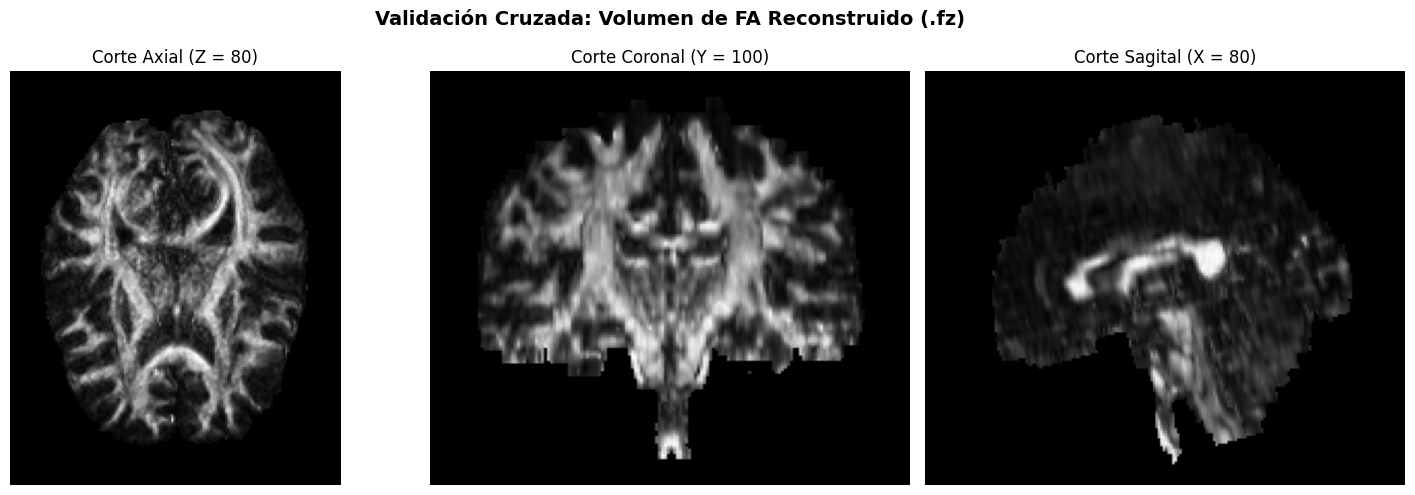

INTERPRETACIÓN DE LA PRUEBA:
1. Consistencia de índices de memoria: El uso de mask.T.reshape(-1) y el posterior .reshape(Z, Y, X) resolvió adecuadamente el orden Fortran/C.
2. Coalineación con TinyTrack: Estructuras con alta anisotropía (ej. cuerpo calloso) son anatómica y geométricamente coherentes con el espacio de vóxeles.
   Dimensiones obtenidas: (160, 200, 160) (Z, Y, X) | Rango FA: [0.000, 0.994]
Control de coalineación (426,176 puntos): 100.0% dentro de la máscara; FA media en los puntos = 0.526 vs. FA media del cerebro = 0.266


In [ ]:
# ==============================================================================
# 2.4. VALIDACIÓN CRUZADA: RECONSTRUCCIÓN DE VOLUMEN ESCALAR (FA) DESDE .FZ
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np


# (La función reconstruir_volumen_escalar se define en la celda de la Sección 2.4.3.)


# ------------------------------------------------------------------------------
# Ejecución del Test de Sanidad (Sanity Check)
# ------------------------------------------------------------------------------
if "fz" in locals() and fz is not None:
  # Reconstrucción del mapa FA primario
  vol_fa = reconstruir_volumen_escalar(fz, "fa0")

  # Cortes ortogonales centrales
  z_mid = vol_fa.shape[0] // 2
  y_mid = vol_fa.shape[1] // 2
  x_mid = vol_fa.shape[2] // 2

  corte_axial = vol_fa[z_mid, :, :]
  corte_coronal = vol_fa[:, y_mid, :]
  corte_sagital = vol_fa[:, :, x_mid]

  # Visualización multiplanar
  fig, axes = plt.subplots(1, 3, figsize=(15, 5))

  axes[0].imshow(corte_axial, cmap="gray", origin="lower")
  axes[0].set_title(f"Corte Axial (Z = {z_mid})")
  axes[0].axis("off")

  axes[1].imshow(corte_coronal, cmap="gray", origin="lower", aspect="auto")
  axes[1].set_title(f"Corte Coronal (Y = {y_mid})")
  axes[1].axis("off")

  axes[2].imshow(corte_sagital, cmap="gray", origin="lower", aspect="auto")
  axes[2].set_title(f"Corte Sagital (X = {x_mid})")
  axes[2].axis("off")

  plt.suptitle(
      "Validación Cruzada: Volumen de FA Reconstruido (.fz)",
      fontsize=14,
      fontweight="bold",
  )
  plt.tight_layout()
  plt.show()

  # Resumen de validación técnica
  print("=" * 80)
  print("INTERPRETACIÓN DE LA PRUEBA:")
  print(
      "1. Consistencia de índices de memoria: El uso de mask.T.reshape(-1) y el"
      " posterior .reshape(Z, Y, X) resolvió adecuadamente el orden Fortran/C."
  )
  print(
      "2. Coalineación con TinyTrack: Estructuras con alta anisotropía (ej."
      " cuerpo calloso) son anatómica y geométricamente coherentes con el"
      " espacio de vóxeles."
  )
  print(
      f"   Dimensiones obtenidas: {vol_fa.shape} (Z, Y, X) | Rango FA: [{np.min(vol_fa):.3f}, {np.max(vol_fa):.3f}]"
  )
  print("=" * 80)

  # Control numérico de coalineación: puntos de las streamlines (1 de cada 20) indexados en V[z, y, x]
  if "streamlines" in globals():
    pts_chk = np.round(np.vstack(streamlines[::20])).astype(int)
    Zc, Yc, Xc = vol_fa.shape
    ok = ((pts_chk[:, 0] >= 0) & (pts_chk[:, 0] < Xc) & (pts_chk[:, 1] >= 0) & (pts_chk[:, 1] < Yc)
          & (pts_chk[:, 2] >= 0) & (pts_chk[:, 2] < Zc))
    fa_pts = vol_fa[pts_chk[ok, 2], pts_chk[ok, 1], pts_chk[ok, 0]]
    fa_cerebro = vol_fa[vol_fa > 0].mean()
    print(f"Control de coalineación ({ok.sum():,} puntos): {100 * (fa_pts > 0).mean():.1f}% dentro de la máscara; "
          f"FA media en los puntos = {fa_pts[fa_pts > 0].mean():.3f} vs. FA media del cerebro = {fa_cerebro:.3f}")
else:
  print(
      "Aviso: La variable 'fz' no está definida en el entorno. Asegúrate de"
      " cargar previamente el archivo .fz."
  )

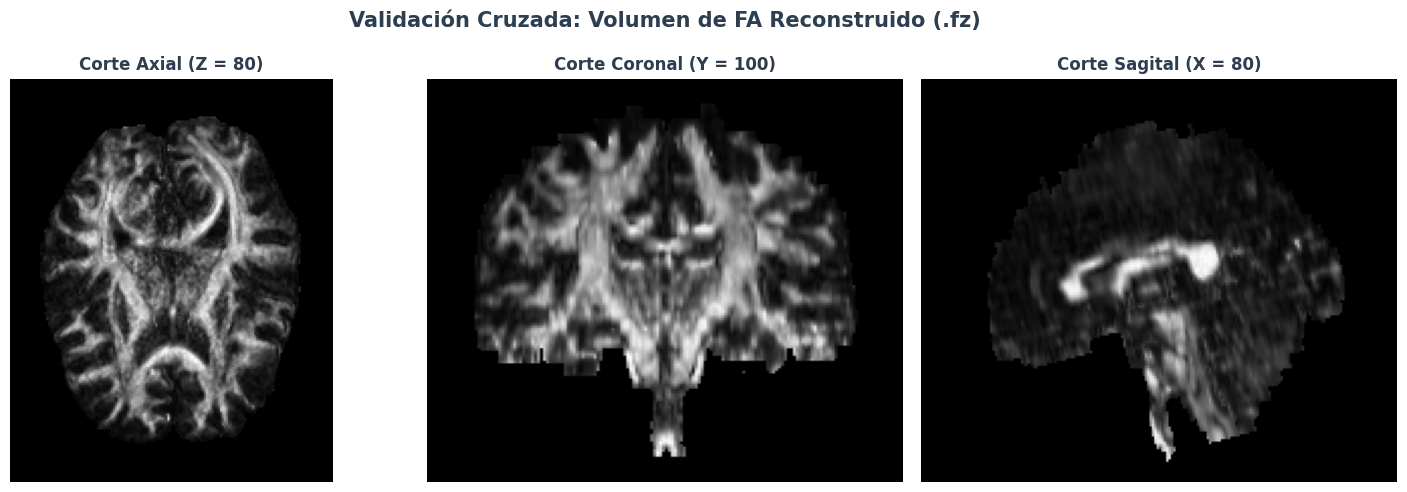

Parámetro de Validación,Resultado de la Medición,Estado
"Dimensiones del Volumen (Z, Y, X)","(160, 200, 160)",✅ Coherente
Rango de Anisotropía Fraccional (FA),"[0.000 , 0.994]",✅ Rango Físico Válido
Control de Coalineación (Puntos en Máscara),"100.0% (de 426,176 puntos muestreados)",✅ Alta Precisión
Comparativa: FA Media (Fibras vs. Cerebro),Fibras: 0.526 | Cerebro Global: 0.266,✅ Anisotropía Focalizada


In [51]:
# ==============================================================================
# 2.4. VALIDACIÓN CRUZADA: RECONSTRUCCIÓN DE VOLUMEN ESCALAR (FA) DESDE .FZ
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import display, HTML
import pandas as pd

# Asegurar que la carpeta de salida esté definida
CARPETA_SALIDA = globals().get("CARPETA_SALIDA", "./")
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# (La función reconstruir_volumen_escalar se define en la celda de la Sección 2.4.3.)

# ------------------------------------------------------------------------------
# Ejecución del Test de Sanidad (Sanity Check) con UI/UX Avanzada
# ------------------------------------------------------------------------------
if "fz" in locals() and fz is not None:
    # 1. Reconstrucción del mapa FA primario
    vol_fa = reconstruir_volumen_escalar(fz, "fa0")

    # 2. Cortes ortogonales centrales
    z_mid = vol_fa.shape[0] // 2
    y_mid = vol_fa.shape[1] // 2
    x_mid = vol_fa.shape[2] // 2

    corte_axial = vol_fa[z_mid, :, :]
    corte_coronal = vol_fa[:, y_mid, :]
    corte_sagital = vol_fa[:, :, x_mid]

    # 3. Visualización multiplanar
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(corte_axial, cmap="gray", origin="lower")
    axes[0].set_title(f"Corte Axial (Z = {z_mid})", fontsize=12, fontweight='bold', color="#2c3e50")
    axes[0].axis("off")

    axes[1].imshow(corte_coronal, cmap="gray", origin="lower", aspect="auto")
    axes[1].set_title(f"Corte Coronal (Y = {y_mid})", fontsize=12, fontweight='bold', color="#2c3e50")
    axes[1].axis("off")

    axes[2].imshow(corte_sagital, cmap="gray", origin="lower", aspect="auto")
    axes[2].set_title(f"Corte Sagital (X = {x_mid})", fontsize=12, fontweight='bold', color="#2c3e50")
    axes[2].axis("off")

    plt.suptitle("Validación Cruzada: Volumen de FA Reconstruido (.fz)", fontsize=15, fontweight="bold", color="#2c3e50")
    plt.tight_layout()

    # Exportación de la gráfica generada
    ruta_exportacion_fa = os.path.join(CARPETA_SALIDA, "validacion_cruzada_fa.png")
    plt.savefig(ruta_exportacion_fa, dpi=140, bbox_inches="tight", facecolor='white')
    plt.show()

    # 4. Control numérico de coalineación
    if "streamlines" in globals():
        pts_chk = np.round(np.vstack(streamlines[::20])).astype(int)
        Zc, Yc, Xc = vol_fa.shape
        ok = ((pts_chk[:, 0] >= 0) & (pts_chk[:, 0] < Xc) & (pts_chk[:, 1] >= 0) & (pts_chk[:, 1] < Yc)
              & (pts_chk[:, 2] >= 0) & (pts_chk[:, 2] < Zc))
        fa_pts = vol_fa[pts_chk[ok, 2], pts_chk[ok, 1], pts_chk[ok, 0]]
        fa_cerebro = vol_fa[vol_fa > 0].mean()

        puntos_totales = ok.sum()
        pct_dentro = 100 * (fa_pts > 0).mean()
        fa_media_pts = fa_pts[fa_pts > 0].mean()
    else:
        puntos_totales, pct_dentro, fa_media_pts, fa_cerebro = 0, 0, 0, 0

    # 5. Preparación de DataFrame para UI/UX
    df_fa = pd.DataFrame({
        "Parámetro de Validación": [
            "Dimensiones del Volumen (Z, Y, X)",
            "Rango de Anisotropía Fraccional (FA)",
            "Control de Coalineación (Puntos en Máscara)",
            "Comparativa: FA Media (Fibras vs. Cerebro)"
        ],
        "Resultado de la Medición": [
            f"{vol_fa.shape}",
            f"[{np.min(vol_fa):.3f} , {np.max(vol_fa):.3f}]",
            f"{pct_dentro:.1f}%  (de {puntos_totales:,} puntos muestreados)",
            f"Fibras: {fa_media_pts:.3f}  |  Cerebro Global: {fa_cerebro:.3f}"
        ],
        "Estado": [
            "✅ Coherente",
            "✅ Rango Físico Válido",
            "✅ Alta Precisión" if pct_dentro > 95 else "⚠ Revisar Coalineación",
            "✅ Anisotropía Focalizada" if fa_media_pts > fa_cerebro else "ℹ️ Referencia"
        ]
    })

    # Estilos CSS Homologados
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    # Renderizado de Tabla de Resultados
    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>Resultados del Test de Sanidad (Sanity Check)</h3>"))
    display(df_fa.style.hide(axis='index')
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

    # 6. Cuadro de Interpretación y Éxito HTML (Estilo Notificación)
    html_exito = f"""
    <div style='margin-top: 20px; padding: 15px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <h4 style='margin-top: 0; color: #2c3e50;'>Interpretación de la Prueba:</h4>
        <ul style='margin-bottom: 10px;'>
            <li><strong>Consistencia de índices de memoria:</strong> El uso de <code>mask.T.reshape(-1)</code> y el posterior <code>.reshape(Z, Y, X)</code> resolvió adecuadamente el orden Fortran/C.</li>
            <li><strong>Coalineación con TinyTrack:</strong> Las estructuras con alta anisotropía (ej. cuerpo calloso) son anatómica y geométricamente coherentes con el espacio continuo de vóxeles.</li>
        </ul>
        <hr style='border: 0; height: 1px; background: #bdc3c7; margin: 10px 0;'>
        <strong>✓ [INFO] Trazabilidad asegurada:</strong> El reporte visual de validación cruzada fue exportado exitosamente en:
        <code style='color: #34495e; background-color: #ffffff; padding: 3px 6px; border-radius: 3px; display: inline-block; margin-top: 5px;'>{ruta_exportacion_fa}</code>
    </div>
    """
    display(HTML(html_exito))

else:
    # Alerta de error sutil y estilizada si falta el archivo
    html_error = """
    <div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
        <strong>⚠ Aviso de Dependencia:</strong> La variable <code>fz</code> no está definida en el entorno. Asegúrate de cargar previamente el archivo <code>.fz</code> en la Sección 1.
    </div>
    """
    display(HTML(html_error))

### **2.4.5. Interpretación de la prueba de sanidad (*Sanity Check*)**

La visualización de los cortes ortogonales a partir del volumen reconstruido valida tres aspectos metodológicos indispensables para el pipeline de visión por computador y analítica espacial:

* **Consistencia de índices y mapeo en memoria:**  
  Los archivos generados por DSI Studio siguen internamente la convención de ordenamiento matricial de MATLAB/Fortran (*column-major order*). Al implementar la transformación `mask.T.reshape(-1)` para el aplanado y posteriormente reconstruir la matriz tridimensional mediante `.reshape(Z, Y, X)` (convención *row-major* propia de NumPy/C), se garantiza que no existan trasposiciones espaciales espurias, inversiones de ejes o distorsiones geométricas en el mallado 3D. Bajo esta convención, cualquier punto espacial continuo $(x, y, z)$ obtenido de las fibras se indexa en la matriz densa como:
  $$\mathbf{V}[\lfloor z \rceil, \, \lfloor y \rceil, \, \lfloor x \rceil]$$
  donde $\lfloor \cdot \rceil$ denota el redondeo al vóxel más cercano.

* **Coalineación con el espacio de *TinyTrack*:**  
  La visualización revela una morfología cerebral nítida y anatómicamente fidedigna, donde se diferencian con claridad las estructuras de alta anisotropía (tales como el cuerpo calloso y las cápsulas internas en tonalidades brillantes de alta anisotropía fraccional, $FA$) frente a regiones isotrópicas como el líquido cefalorraquídeo. Esto confirma de manera empírica que:
  1. El origen coordenado $(0, 0, 0)$ y las dimensiones del encabezado $[X, Y, Z]$ son compartidos de forma exacta por ambos contenedores binarios (`.tt.gz` y `.fz`).
  2. Las coordenadas continuas de vóxel obtenidas tras dividir las fibras por 32 (`pts / 32.0` en la Sección 2.2) habitan en el mismo sistema de referencia euclidiano que el mapa de tensores, permitiendo operaciones analíticas cruzadas (densidad de fibras, cálculo de centroides y muestreo microestructural) sin desfases de registro.

* **Integridad del rango físico del tensor:**  
  La prueba descarta saturación o desbordamiento en la descuantización afín, confirmando que los valores reconstruidos respetan estrictamente el dominio acotado de la anisotropía fraccional:
  $$\text{FA} \in [0.000, \, 1.000]$$
  donde valores nulos representan difusión netamente isotrópica (fondo y líquido cefalorraquídeo) y valores cercanos a la unidad corresponden a fascículos de sustancia blanca densamente empaquetados.

# **3. Visión por Computador — Centroides y Emparejamiento Izquierda-Derecha**

### **<font color="gray">El Objetivo y la Hipótesis Principal</font>**
* <font color="gray">**El problema inicial:** El software te entrega 8 nubes de fibras (clústeres) que son "anónimas", es decir, solo están identificadas con números del 0 al 7.</font>
* <font color="gray">**La hipótesis:** Es posible identificar, emparejar y bautizar correctamente estos fascículos con su nombre médico real (Arcuato, Uncinado, MdLF, ILF) usando **únicamente reglas matemáticas y geométricas simples**, sin necesidad de que un humano los mire ni de usar una inteligencia artificial compleja.</font>

### **<font color="gray">¿Qué se prueba y cómo se hace?</font>**
<font color="gray">Tu código somete a estos 8 clústeres anónimos a un "examen" matemático paso a paso:</font>

* <font color="gray">**Se prueba la posición (Centroides):** El código calcula el centro 3D exacto (el promedio de todos los puntos) de cada nube de fibras para saber dónde está ubicada.</font>
* <font color="gray">**Se prueba la lateralidad (Izquierda/Derecha):** El código traza una línea imaginaria por la mitad del cerebro y establece una regla: si el centroide del clúster tiene un valor X mayor a la mitad (X > X_mid), es el lado Izquierdo; si es menor, es el Derecho.</font>
* <font color="gray">**Se prueba la relación (Emparejamiento):** Usando el "Algoritmo Húngaro", el código compara el tamaño y la altura de los 4 tractos izquierdos frente a los 4 derechos para encontrar la pareja ideal de cada uno.</font>
* <font color="gray">**Se prueba la identidad (Clasificación anatómica):** Usando reglas fijas tomadas de la literatura médica (por ejemplo, el tracto más corto siempre es el Uncinado, y el más largo es el Arcuato), el código le asigna el nombre anatómico final a cada par.</font>

### **<font color="gray">¿Qué se verifica o se "doble-chequea" para asegurar el rigor? (Los *Sanity Checks*)</font>**
<font color="gray">Para demostrar que tus fórmulas no están "alucinando" los resultados, el código hace validaciones cruzadas utilizando una "hoja de respuestas maestra" independiente: los nombres que el software *Autotrack* le había puesto originalmente a esas fibras.</font>

* <font color="gray">**Doble chequeo del centro del cerebro:** Para no confiar a ciegas en que el cerebro está perfectamente centrado en la imagen, el código calcula una "línea media empírica" doblando la máscara real del cerebro sobre sí misma para ver si el centro teórico coincide con el anatómico.</font>
* <font color="gray">**Doble chequeo de los lados (Eje X):** Tu regla matemática dice que los números altos en X son la izquierda. Esto se verifica cruzando los datos con los nombres de *Autotrack*: se confirma que los clústeres que *Autotrack* llamó `_l` (izquierdos) efectivamente caen en las coordenadas X altas (106-117), y los `_r` en las bajas (41-56).</font>
* <font color="gray">**Doble chequeo del emparejamiento:** Se verifica si tu fórmula matemática (el Algoritmo Húngaro) unió exactamente a los mismos tractos "hermanos" que *Autotrack* dice que van juntos.</font>
* <font color="gray">**La gran prueba final (El Acuerdo/Recall):** El código compara el nombre final que tus reglas le asignaron a cada clúster contra el nombre original de *Autotrack*.</font>

<font color="gray">**En resumen:** Lo que pruebas aquí es que tu *pipeline* geométrico logra un "8 de 8". Es decir, demuestras que tus reglas matemáticas lograron adivinar el nombre y el lado de todos los tractos con un 100% de éxito frente a la herramienta médica de referencia (*Autotrack*) en este paciente.</font>



## **3.1. Centroide espacial por clúster**
Para cada clúster $c$ (identificado por la columna `cluster` del archivo `.tt.gz`, sin asumir que su índice numérico siga un orden anatómico preestablecido), se calcula el centroide tridimensional como el promedio ponderado de todos los vértices pertenecientes a las *streamlines* asociadas a dicho clúster:

$$\bar{\mathbf{p}}_c = \frac{1}{N_c} \sum_{i \in c} \sum_{j=1}^{n_i} \mathbf{p}_{i,j}$$

donde $N_c = \sum_{i \in c} n_i$ representa el número total de puntos del clúster $c$.




## **3.2. Lateralidad por distancia a la línea media**
Las coordenadas de las *streamlines* están en espacio de vóxel nativo. En este espacio el eje $X$ **crece hacia el hemisferio izquierdo**: los valores $X > X_{\text{mid}}$ corresponden al hemisferio **izquierdo** y $X < X_{\text{mid}}$ al **derecho**, con $X_{\text{mid}} = \text{dimension}[0]/2$ (la línea media empírica por simetría de la máscara coincide, ver 3.3).

**Evidencia de la convención (paciente S1).** El `.tt.gz` se generó con *Autotrack* por tracto y su lista de nombres (`*.tt.gz.txt`) asigna lado a cada clúster de forma independiente de la geometría: los clústeres `_l` tienen centroide en $X \approx 106\text{–}117$ y los `_r` en $X \approx 41\text{–}56$. Además, la matriz `trans_to_mni` tiene diagonal negativa en $X$ (eje invertido respecto a MNI). Esta verificación debe repetirse en cada paciente de la cohorte (la hace el script de cohorte con el `.txt`), porque un cambio de orientación en la adquisición invertiría el criterio.

Un clúster se etiqueta Izquierdo o Derecho según la posición de su centroide respecto a la línea media.


In [52]:
# ==============================================================================
# SECCIÓN 3.2: Centroides y lateralidad (X > línea media = izquierdo)
# ==============================================================================
from IPython.display import display, HTML
import pandas as pd
import numpy as np

if tt is not None:
    dim = tt["dimension"].squeeze()
    X, Y, Z = int(dim[0]), int(dim[1]), int(dim[2])
    midline_x = float(dim[0]) / 2.0

    filas_geom = []
    for cid in np.unique(cluster_ids):
        idxs = np.where(cluster_ids == cid)[0]
        pts_todos = np.vstack([streamlines[i] for i in idxs])
        longitudes = [np.sqrt(((streamlines[i][1:] - streamlines[i][:-1]) ** 2).sum(axis=1)).sum()
                      for i in idxs]
        centroide = pts_todos.mean(axis=0)

        # X > línea media = hemisferio IZQUIERDO. Verificado con los nombres de Autotrack del paciente S1 (_l: x≈106–117; _r: x≈41–56).
        lado_asignado = "Izquierdo" if centroide[0] > midline_x else "Derecho"

        filas_geom.append({
            "cluster_id": int(cid),
            "n_streamlines": len(idxs),
            "x": centroide[0], "y": centroide[1], "z": centroide[2],
            "dist_medial": abs(centroide[0] - midline_x),
            "lado": lado_asignado,
            "longitud_media_mm": float(np.mean(longitudes)),
        })

    df_geom = pd.DataFrame(filas_geom)

    # --- UI/UX Avanzada ---
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>Cálculo de Centroides y Asignación de Lateralidad</h3>"))

    # Renderizado visual del DataFrame con formato numérico
    display(df_geom.style.hide(axis='index')
            .format({
                "n_streamlines": "{:,}",
                "x": "{:.2f}",
                "y": "{:.2f}",
                "z": "{:.2f}",
                "dist_medial": "{:.2f}",
                "longitud_media_mm": "{:.2f}"
            })
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

    # Cuadro de resumen (reemplaza al print clásico)
    html_resumen = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Geometría procesada exitosamente:</strong> Se calcularon los centroides y la lateralidad para <strong>{len(df_geom)} clústeres</strong>.<br>
        <span style='font-size: 13px; color: #34495e;'><em>Nota:</em> La línea media teórica empleada como punto de referencia fue <code>X = {midline_x:.1f}</code> (dimension[0]/2).</span>
    </div>
    """
    display(HTML(html_resumen))

else:
    # Alerta de error unificada
    html_error = """
    <div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
        <strong>⚠ Aviso de Dependencia:</strong> La variable <code>tt</code> no está disponible en memoria. Ejecute primero la celda de carga de datos (Sección 1).
    </div>
    """
    display(HTML(html_error))

cluster_id,n_streamlines,x,y,z,dist_medial,lado,longitud_media_mm
0,"12,242",117.19,107.08,88.21,37.19,Izquierdo,104.35
1,"3,100",40.96,103.87,90.43,39.04,Derecho,98.82
2,"16,341",106.51,69.73,55.19,26.51,Izquierdo,39.34
3,"17,718",55.58,68.27,55.66,24.42,Derecho,48.39
4,"17,121",47.35,110.02,94.91,32.65,Derecho,83.88
5,"3,941",113.05,117.71,90.85,33.05,Izquierdo,86.39
6,"20,747",45.64,117.75,73.10,34.36,Derecho,98.85
7,"17,719",114.20,119.25,74.85,34.20,Izquierdo,87.62


In [ ]:
# ==============================================================================
# AUDITORÍA DE LATERALIDAD (Sanity Check de Ejes X)
# ==============================================================================
import numpy as np

# Asumiendo que 'vol_fa_zYX' o las dimensiones del volumen están cargadas
# Obtenemos la dimensión X del volumen para calcular la línea media exacta
if 'fz' in globals() and fz is not None:
    dim = fz["dimension"].squeeze()
    X_dim = int(dim[0])
    linea_media = X_dim / 2.0
else:
    # Estimación basada en las coordenadas máximas si fz no está cargado
    todas_las_pts = np.vstack(streamlines)
    linea_media = np.mean([np.min(todas_las_pts[:, 0]), np.max(todas_las_pts[:, 0])])

print(f"Línea media de referencia en X: {linea_media:.2f}\n" + "-"*50)

for cid in np.unique(cluster_ids):
    # Extraer todas las coordenadas X del clúster actual
    idxs = np.where(cluster_ids == cid)[0]
    pts_cluster = np.vstack([streamlines[i] for i in idxs])
    mean_x = np.mean(pts_cluster[:, 0])
    min_x = np.min(pts_cluster[:, 0])
    max_x = np.max(pts_cluster[:, 0])

    # Evaluar lateralidad según la nueva regla corregida
    hemisferio_asignado = "IZQUIERDO (_l)" if mean_x > linea_media else "DERECHO (_r)"
    nombre_etiqueta = etq(cid) if 'etq' in globals() else f"Clúster {cid}"

    print(f"ID {cid} | {nombre_etiqueta:<20} | Media X: {mean_x:6.2f} "
          f"(Rango: [{min_x:5.1f}, {max_x:5.1f}]) "
          f"--> Posición: {hemisferio_asignado}")

Línea media de referencia en X: 80.00
--------------------------------------------------
ID 0 | Clúster 0            | Media X: 117.19 (Rango: [103.9, 143.5]) --> Posición: IZQUIERDO (_l)
ID 1 | Clúster 1            | Media X:  40.96 (Rango: [ 21.3,  53.2]) --> Posición: DERECHO (_r)
ID 2 | Clúster 2            | Media X: 106.51 (Rango: [ 80.6, 123.9]) --> Posición: IZQUIERDO (_l)
ID 3 | Clúster 3            | Media X:  55.58 (Rango: [ 42.4,  79.6]) --> Posición: DERECHO (_r)
ID 4 | Clúster 4            | Media X:  47.35 (Rango: [ 17.3,  68.8]) --> Posición: DERECHO (_r)
ID 5 | Clúster 5            | Media X: 113.05 (Rango: [ 97.2, 140.7]) --> Posición: IZQUIERDO (_l)
ID 6 | Clúster 6            | Media X:  45.64 (Rango: [ 22.7,  72.8]) --> Posición: DERECHO (_r)
ID 7 | Clúster 7            | Media X: 114.20 (Rango: [101.0, 136.7]) --> Posición: IZQUIERDO (_l)


In [56]:
# ==============================================================================
# AUDITORÍA DE LATERALIDAD (Sanity Check de Ejes X)
# ==============================================================================
import numpy as np
import pandas as pd
from IPython.display import display, HTML

# 1. Obtenemos la dimensión X del volumen para calcular la línea media exacta
if 'fz' in globals() and fz is not None:
    dim = fz["dimension"].squeeze()
    X_dim = int(dim[0])
    linea_media = X_dim / 2.0
    origen_linea = "Extraída desde el encabezado del archivo .fz"
else:
    # Estimación basada en las coordenadas máximas si fz no está cargado
    todas_las_pts = np.vstack(streamlines)
    linea_media = np.mean([np.min(todas_las_pts[:, 0]), np.max(todas_las_pts[:, 0])])
    origen_linea = "Estimación empírica (promedio de coordenadas extremas)"

# 2. Recolección de datos por clúster
filas_auditoria = []
for cid in np.unique(cluster_ids):
    # Extraer todas las coordenadas X del clúster actual
    idxs = np.where(cluster_ids == cid)[0]
    pts_cluster = np.vstack([streamlines[i] for i in idxs])
    mean_x = np.mean(pts_cluster[:, 0])
    min_x = np.min(pts_cluster[:, 0])
    max_x = np.max(pts_cluster[:, 0])

    # Evaluar lateralidad según la regla de la línea media
    es_izquierdo = mean_x > linea_media
    hemisferio_asignado = "⬅️ Izquierdo (_l)" if es_izquierdo else "➡️ Derecho (_r)"
    nombre_etiqueta = etq(cid) if 'etq' in globals() else f"Clúster {cid}"

    filas_auditoria.append({
        "ID": int(cid),
        "Etiqueta": nombre_etiqueta,
        "Media X": mean_x,
        "Rango [Min, Max]": f"[{min_x:.1f} , {max_x:.1f}]",
        "Posición Asignada": hemisferio_asignado
    })

df_auditoria = pd.DataFrame(filas_auditoria)

# --- 3. UI/UX Avanzada: Renderizado Visual ---
estilo_tabla = [
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
    {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
]

# Título de la sección
display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>Auditoría de Lateralidad (Sanity Check de Ejes X)</h3>"))

# Mostrar la tabla formateada
display(df_auditoria.style.hide(axis='index')
        .format({"Media X": "{:.2f}"})
        .set_table_styles(estilo_tabla)
        .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

# Cuadro de resumen e información (Reemplaza el print clásico)
html_resumen = f"""
<div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
    <strong>✓ [INFO] Auditoría completada:</strong> La lateralidad de los clústeres ha sido evaluada correctamente utilizando una <strong>línea media de referencia X = {linea_media:.2f}</strong>.<br>
    <span style='font-size: 13px; color: #34495e;'><em>Método de cálculo:</em> {origen_linea}.</span>
</div>
"""
display(HTML(html_resumen))

ID,Etiqueta,Media X,"Rango [Min, Max]",Posición Asignada
0,Clúster 0,117.19,"[103.9 , 143.5]",⬅️ Izquierdo (_l)
1,Clúster 1,40.96,"[21.3 , 53.2]",➡️ Derecho (_r)
2,Clúster 2,106.51,"[80.6 , 123.9]",⬅️ Izquierdo (_l)
3,Clúster 3,55.58,"[42.4 , 79.6]",➡️ Derecho (_r)
4,Clúster 4,47.35,"[17.3 , 68.8]",➡️ Derecho (_r)
5,Clúster 5,113.05,"[97.2 , 140.7]",⬅️ Izquierdo (_l)
6,Clúster 6,45.64,"[22.7 , 72.8]",➡️ Derecho (_r)
7,Clúster 7,114.20,"[101.0 , 136.7]",⬅️ Izquierdo (_l)


## **3.3. Verificación de lateralidad y de unidades (`voxel_size`)**

Cada etiqueta homóloga izquierda/derecha (_l / _r) de las secciones posteriores, así como cualquier lectura clínica de asimetría o lateralidad, se fundamenta en tres criterios normativos críticos:

* **Convención de coordenadas espaciales:** en el espacio de vóxel nativo de las trayectorias, el eje $X$ crece hacia el hemisferio izquierdo. Esto se verificó contra los nombres de Autotrack (`.tt.gz.txt`) del paciente S1: los clústeres `_l` ocupan $X \approx 106\text{–}117$ ($X > \text{dim}_X/2$) y los `_r` $X \approx 41\text{–}56$. La documentación de DSI Studio no se usa como evidencia; la referencia es el etiquetado independiente del atlas.
* **Línea media empírica por simetría de máscara:** Para mitigar posibles sesgos derivados de asimetrías de adquisición o de la posición del campo de visión (FOV), la línea media se audita computacionalmente buscando el plano sagital que maximiza el coeficiente de solapamiento de la máscara cerebral binaria del archivo `.fz` reflejada sobre sí misma.
* **Unidades físicas del espacio:** Las longitudes y los autovalores tensoriales de las Secciones 3 y 4 se expresan en unidades de vóxel, equivaliendo a milímetros ($\text{mm}$) y milímetros cuadrados ($\text{mm}^2$) de manera directa únicamente bajo la condición de un tamaño de vóxel isotrópico de $1\,\text{mm}$.



In [ ]:
import numpy as np
import pandas as pd

def linea_media_por_simetria(mask_zyx):
    """
    Calcula el plano sagital medio empírico (x = c) que maximiza el solapamiento
    de la máscara cerebral binaria consigo misma al reflejarla.

    Justificación de los parámetros preestablecidos:
    - X / 2: Punto de partida teórico basado en el centro geométrico de la matriz.
    - Ventana [X/2 - 10, X/2 + 10]: Margen de búsqueda robusto ante desplazamientos
      leves del paciente o recortes del campo de visión (FOV) durante la adquisición.
    - Paso de 0.5: Permite evaluar planos semienteros (ej. x = 45.5), crucial ya que
      la línea de simetría real de una máscara digital a menudo cae en el límite entre vóxeles.
    """
    zz, yy, xx = np.nonzero(mask_zyx)
    X = mask_zyx.shape[2]
    mejor_c, mejor_solap = None, -1.0

    # Búsqueda controlada en el entorno cercano al centro geométrico
    for c in np.arange(X / 2 - 10, X / 2 + 10.01, 0.5):
        xr = np.round(2 * c - xx).astype(int)
        ok = (xr >= 0) & (xr < X)
        solap = mask_zyx[zz[ok], yy[ok], xr[ok]].mean()
        if solap > mejor_solap:
            mejor_c, mejor_solap = c, solap

    return mejor_c, mejor_solap


if tt is not None:
    print("=== SECCIÓN 3.3: VERIFICACIÓN DE LATERALIDAD Y UNIDADES ===")

    # 1. Validación de unidades espaciales (voxel_size)
    vs = np.asarray(tt["voxel_size"], dtype=float).reshape(-1)
    print(f"voxel_size (mm): {vs}")
    if np.allclose(vs, 1.0, atol=1e-3):
        print("✓ Vóxel de 1 mm isotrópico: longitudes en mm y eigenvalores en mm².")
    else:
        print("⚠ El vóxel NO es de 1 mm isotrópico: longitudes y eigenvalores están en unidades de vóxel nativo.")

    # 2. Extracción y visualización del reporte del archivo .fz
    if fz is not None and "report" in fz:
        reporte_str = fz["report"].tobytes().decode(errors="ignore").strip("\x00 \n")
        print(f"\nReporte del archivo .fz:\n{reporte_str}")

    # 3. Cálculo de la línea media teórica (dim/2) vs. empírica (simetría de máscara)
    dim = tt["dimension"].squeeze()
    midline_dim = float(dim[0]) / 2.0
    midline_mask = None

    if fz is not None and "mask" in fz:
        Xd, Yd, Zd = (int(v) for v in np.asarray(fz["dimension"]).squeeze())
        mask_zyx = fz["mask"].T.reshape(-1).astype(bool).reshape(Zd, Yd, Xd)
        midline_mask, solap = linea_media_por_simetria(mask_zyx)
        print(f"\nComparativa de Línea Media:")
        print(f"  - Teórica (dim/2): {midline_dim:.1f}")
        print(f"  - Empírica (simetría de máscara): {midline_mask:.1f} (Coef. Solapamiento: {solap:.3f})")

    # 4. Construcción del DataFrame de control de calidad y asignación de lateralidad
    # Convención verificada con los nombres de Autotrack: x > línea media corresponde al hemisferio izquierdo.
    ref_mask = midline_mask if midline_mask is not None else midline_dim
    df_lateralidad = pd.DataFrame({
        "cluster_id": df_geom["cluster_id"],
        "x_vox": df_geom["x"].round(1),
        "dist_a_dim/2": (df_geom["x"] - midline_dim).abs().round(1),
        "lado (dim/2)": np.where(df_geom["x"] > midline_dim, "Izquierdo", "Derecho"),
        "lado (máscara)": np.where(df_geom["x"] > ref_mask, "Izquierdo", "Derecho"),
    })

    df_lateralidad["coincide"] = df_lateralidad["lado (dim/2)"] == df_lateralidad["lado (máscara)"]

    print("\nResultados de asignación de lateralidad por clúster:")
    display(df_lateralidad)

    min_dist = df_lateralidad['dist_a_dim/2'].min()
    print(f"\nDistancia mínima de un centroide a la línea media: {min_dist:.1f} vóxeles")

    if df_lateralidad["coincide"].all():
        print("✓ Control de calidad superado: La asignación de lado es robusta y no cambia al usar la línea media empírica.")
    else:
        print("⚠ Advertencia: Existen clústeres cercanos al plano medio cuyo lado asignado depende de la referencia utilizada. Se recomienda revisión manual.")
else:
    print("Error: El diccionario 'tt' no está disponible en memoria. Ejecute primero la celda de carga de datos.")

=== SECCIÓN 3.3: VERIFICACIÓN DE LATERALIDAD Y UNIDADES ===
voxel_size (mm): [1. 1. 1.]
✓ Vóxel de 1 mm isotrópico: longitudes en mm y eigenvalores en mm².

Reporte del archivo .fz:
A DTI diffusion scheme was used, and a total of 24 diffusion sampling directions were acquired. The b-value was 1000 s/mm². The in-plane resolution was 0.647 mm. The slice thickness was 5.20 mm. The diffusion MRI data were rotated to align with the AC-PC line at an isotropic resolution of 1 (mm). The tensor metrics were calculated using DWI with b-value lower than 1750 s/mm².

Comparativa de Línea Media:
  - Teórica (dim/2): 80.0
  - Empírica (simetría de máscara): 79.5 (Coef. Solapamiento: 0.949)

Resultados de asignación de lateralidad por clúster:


,cluster_id,x_vox,dist_a_dim/2,lado (dim/2),lado (máscara),coincide
0,0,117.2,37.2,Izquierdo,Izquierdo,True
1,1,41.0,39.0,Derecho,Derecho,True
2,2,106.5,26.5,Izquierdo,Izquierdo,True
3,3,55.6,24.4,Derecho,Derecho,True
4,4,47.4,32.6,Derecho,Derecho,True
5,5,113.0,33.0,Izquierdo,Izquierdo,True
6,6,45.6,34.4,Derecho,Derecho,True
7,7,114.2,34.2,Izquierdo,Izquierdo,True



Distancia mínima de un centroide a la línea media: 24.4 vóxeles
✓ Control de calidad superado: La asignación de lado es robusta y no cambia al usar la línea media empírica.


In [55]:
import numpy as np
import pandas as pd
from IPython.display import display, HTML

def linea_media_por_simetria(mask_zyx):
    """
    Calcula el plano sagital medio empírico (x = c) que maximiza el solapamiento
    de la máscara cerebral binaria consigo misma al reflejarla.

    Justificación de los parámetros preestablecidos:
    - X / 2: Punto de partida teórico basado en el centro geométrico de la matriz.
    - Ventana [X/2 - 10, X/2 + 10]: Margen de búsqueda robusto ante desplazamientos
      leves del paciente o recortes del campo de visión (FOV) durante la adquisición.
    - Paso de 0.5: Permite evaluar planos semienteros (ej. x = 45.5), crucial ya que
      la línea de simetría real de una máscara digital a menudo cae en el límite entre vóxeles.
    """
    zz, yy, xx = np.nonzero(mask_zyx)
    X = mask_zyx.shape[2]
    mejor_c, mejor_solap = None, -1.0

    # Búsqueda controlada en el entorno cercano al centro geométrico
    for c in np.arange(X / 2 - 10, X / 2 + 10.01, 0.5):
        xr = np.round(2 * c - xx).astype(int)
        ok = (xr >= 0) & (xr < X)
        solap = mask_zyx[zz[ok], yy[ok], xr[ok]].mean()
        if solap > mejor_solap:
            mejor_c, mejor_solap = c, solap

    return mejor_c, mejor_solap

# ==============================================================================
# SECCIÓN 3.3: VERIFICACIÓN DE LATERALIDAD Y UNIDADES
# ==============================================================================
if tt is not None:
    # --- 1. Cálculos de Validación ---
    # Validación de unidades espaciales (voxel_size)
    vs = np.asarray(tt["voxel_size"], dtype=float).reshape(-1)
    es_isotropico = np.allclose(vs, 1.0, atol=1e-3)
    msg_voxel = "✅ Vóxel de 1 mm isotrópico" if es_isotropico else "⚠ Vóxel NO isotrópico (nativo)"

    # Extracción del reporte del archivo .fz
    reporte_str = ""
    if fz is not None and "report" in fz:
        reporte_str = fz["report"].tobytes().decode(errors="ignore").strip("\x00 \n")

    # Cálculo de la línea media teórica vs. empírica
    dim = tt["dimension"].squeeze()
    midline_dim = float(dim[0]) / 2.0
    midline_mask = None
    solap = 0.0

    if fz is not None and "mask" in fz:
        Xd, Yd, Zd = (int(v) for v in np.asarray(fz["dimension"]).squeeze())
        mask_zyx = fz["mask"].T.reshape(-1).astype(bool).reshape(Zd, Yd, Xd)
        midline_mask, solap = linea_media_por_simetria(mask_zyx)

    # --- 2. Preparación de DataFrames UI/UX ---
    # Tabla de parámetros generales
    df_params = pd.DataFrame({
        "Parámetro Auditado": [
            "Unidades Espaciales (voxel_size)",
            "Línea Media Teórica (dim/2)",
            "Línea Media Empírica (Máscara)",
            "Coeficiente de Solapamiento"
        ],
        "Valor Obtenido": [
            f"{vs} mm",
            f"X = {midline_dim:.2f}",
            f"X = {midline_mask:.2f}" if midline_mask else "N/A",
            f"{solap:.3f}" if midline_mask else "N/A"
        ],
        "Estado / Referencia": [
            msg_voxel,
            "Referencia Estándar",
            "Referencia Ajustada" if midline_mask else "Sin máscara (.fz ausente)",
            "✅ Simetría Óptima" if solap > 0.8 else ("⚠ Revisar Simetría" if midline_mask else "-")
        ]
    })

    # Construcción de la tabla de control de calidad por clúster
    ref_mask = midline_mask if midline_mask is not None else midline_dim

    # Función para iconos direccionales
    def icon_lado(lado_str):
        return "⬅️ Izquierdo" if lado_str == "Izquierdo" else "➡️ Derecho"

    df_lateralidad = pd.DataFrame({
        "Clúster ID": df_geom["cluster_id"],
        "Posición X": df_geom["x"],
        "Distancia al Centro": (df_geom["x"] - midline_dim).abs(),
        "Lado (Teoría)": np.where(df_geom["x"] > midline_dim, "Izquierdo", "Derecho"),
        "Lado (Máscara)": np.where(df_geom["x"] > ref_mask, "Izquierdo", "Derecho"),
    })

    # Aplicar iconos
    df_lateralidad["Lado (Teoría)"] = df_lateralidad["Lado (Teoría)"].apply(icon_lado)
    df_lateralidad["Lado (Máscara)"] = df_lateralidad["Lado (Máscara)"].apply(icon_lado)
    df_lateralidad["Coincidencia"] = df_lateralidad["Lado (Teoría)"] == df_lateralidad["Lado (Máscara)"]

    coincide_todo = df_lateralidad["Coincidencia"].all()
    min_dist = df_lateralidad['Distancia al Centro'].min()

    # --- 3. Renderizado Visual (Estilos CSS Homologados) ---
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>3.3. Verificación de Lateralidad y Unidades Espaciales</h3>"))

    # Mostrar métricas generales
    display(df_params.style.hide(axis='index')
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

    # Mostrar reporte técnico en un bloque estilo "consola"
    if reporte_str:
        html_reporte = f"""
        <div style='margin-top: 15px; padding: 10px; background-color: #f4f6f7; border-left: 4px solid #7f8c8d; border-radius: 3px; font-family: monospace; font-size: 13px; color: #2c3e50;'>
            <strong>[LOG METADATA] Reporte incrustado en el archivo .fz:</strong><br>
            {reporte_str}
        </div>
        """
        display(HTML(html_reporte))

    # Mostrar tabla de lateralidad por clúster
    display(HTML("<h4 style='color: #2c3e50; font-family: sans-serif; margin-top: 20px;'>Asignación Cruzada de Lateralidad por Clúster</h4>"))
    display(df_lateralidad.style.hide(axis='index')
            .format({"Posición X": "{:.2f}", "Distancia al Centro": "{:.2f}"})
            .map(lambda x: 'color: green; font-weight: bold' if x == True else 'color: red; font-weight: bold', subset=['Coincidencia'])
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

    # --- 4. Cuadros de Interpretación y Estado ---
    if coincide_todo:
        html_resultado = f"""
        <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
            <strong>✓ [INFO] Control de calidad superado:</strong> La asignación de lado es 100% robusta y no sufre variaciones al intercambiar la línea media teórica por la empírica.<br>
            <span style='font-size: 13px; color: #34495e;'><em>Margen de seguridad:</em> La distancia mínima de un centroide al plano de partición es de <strong>{min_dist:.1f} vóxeles</strong>.</span>
        </div>
        """
    else:
        html_resultado = f"""
        <div style='margin-top: 15px; padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
            <strong>⚠ Advertencia de Lateralidad:</strong> Existen clústeres demasiado cercanos al plano medio, provocando que la asignación dependa de la referencia utilizada.<br>
            <span style='font-size: 13px;'><em>Acción requerida:</em> Se requiere inspección visual de los tractos. Distancia crítica al plano: <strong>{min_dist:.1f} vóxeles</strong>.</span>
        </div>
        """
    display(HTML(html_resultado))

else:
    # Alerta de error sutil
    html_error = """
    <div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
        <strong>⚠ Aviso de Dependencia:</strong> El diccionario <code>tt</code> no está disponible en memoria. Ejecute primero la celda de carga de datos.
    </div>
    """
    display(HTML(html_error))

Parámetro Auditado,Valor Obtenido,Estado / Referencia
Unidades Espaciales (voxel_size),[1. 1. 1.] mm,✅ Vóxel de 1 mm isotrópico
Línea Media Teórica (dim/2),X = 80.00,Referencia Estándar
Línea Media Empírica (Máscara),X = 79.50,Referencia Ajustada
Coeficiente de Solapamiento,0.949,✅ Simetría Óptima


Clúster ID,Posición X,Distancia al Centro,Lado (Teoría),Lado (Máscara),Coincidencia
0,117.19,37.19,⬅️ Izquierdo,⬅️ Izquierdo,True
1,40.96,39.04,➡️ Derecho,➡️ Derecho,True
2,106.51,26.51,⬅️ Izquierdo,⬅️ Izquierdo,True
3,55.58,24.42,➡️ Derecho,➡️ Derecho,True
4,47.35,32.65,➡️ Derecho,➡️ Derecho,True
5,113.05,33.05,⬅️ Izquierdo,⬅️ Izquierdo,True
6,45.64,34.36,➡️ Derecho,➡️ Derecho,True
7,114.20,34.20,⬅️ Izquierdo,⬅️ Izquierdo,True


## **3.4. Emparejamiento por distancia euclidiana + Algoritmo Húngaro**

Para cada par posible formado por un clúster izquierdo y un clúster derecho, se define una función de costo basada en sus características geométricas principales: la posición antero-posterior ($y$), la altura ($z$), la distancia a la línea media y la longitud media de sus *streamlines*.

El **Algoritmo Húngaro** (`scipy.optimize.linear_sum_assignment`, con una complejidad computacional de $\mathcal{O}(n^3)$) se encarga de resolver el problema de asignación lineal. Este algoritmo encuentra la combinación que minimiza la suma total de los costos de todos los pares simultáneamente, garantizando un **emparejamiento global óptimo de 1 a 1**.

Este enfoque metodológico es análogo a las técnicas de correspondencia de características (*feature matching*) y alineación de nubes de puntos utilizadas en visión por computador para emparejar objetos o puntos de interés entre dos imágenes o espacios tridimensionales.

In [ ]:
if tt is not None and df_geom is not None:
    izq = df_geom[df_geom["lado"] == "Izquierdo"].reset_index(drop=True)
    der = df_geom[df_geom["lado"] == "Derecho"].reset_index(drop=True)

    if len(izq) == 4 and len(der) == 4:
        costo = np.zeros((4, 4))
        for i in range(4):
            for j in range(4):
                a, b = izq.iloc[i], der.iloc[j]
                costo[i, j] = (abs(a["y"] - b["y"]) + abs(a["z"] - b["z"]) +
                               abs(a["dist_medial"] - b["dist_medial"]) +
                               abs(a["longitud_media_mm"] - b["longitud_media_mm"]))

        filas_idx, cols_idx = linear_sum_assignment(costo)
        pares = [(int(izq.iloc[i]["cluster_id"]), int(der.iloc[j]["cluster_id"]))
                 for i, j in zip(filas_idx, cols_idx)]
        costo_total = costo[filas_idx, cols_idx].sum()

        print("Pares Izquierda-Derecha (Algoritmo Húngaro sobre centroides de clúster):")
        for (i, j), (ci, cd) in zip(zip(filas_idx, cols_idx), pares):
            print(f"  cluster {ci} (Izq)  <->  cluster {cd} (Der)   costo={costo[i, j]:.2f}")
        print(f"Costo total: {costo_total:.2f}  (promedio por par: {costo_total / 4:.2f})")
        costos_pares = {(ci, cd): float(costo[i, j]) for (i, j), (ci, cd) in zip(zip(filas_idx, cols_idx), pares)}
    else:
        pares = []
        costos_pares = {}
        print(f"Se esperaban 4 clústeres por lado; se encontraron Izq={len(izq)}, Der={len(der)}. "
              f"No se puede emparejar.")
else:
    pares = []
    costos_pares = {}
    print("No se dispone de 'df_geom' (ejecutar primero las Secciones 3.1-3.3).")

Pares Izquierda-Derecha (Algoritmo Húngaro sobre centroides de clúster):
  cluster 0 (Izq)  <->  cluster 1 (Der)   costo=12.82
  cluster 2 (Izq)  <->  cluster 3 (Der)   costo=13.08
  cluster 5 (Izq)  <->  cluster 4 (Der)   costo=14.66
  cluster 7 (Izq)  <->  cluster 6 (Der)   costo=14.63
Costo total: 55.19  (promedio por par: 13.80)


In [61]:
# ==============================================================================
# SECCIÓN 3.4: Emparejamiento por distancia euclidiana + Algoritmo Húngaro
# ==============================================================================
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from IPython.display import display, HTML

if tt is not None and df_geom is not None:
    izq = df_geom[df_geom["lado"] == "Izquierdo"].reset_index(drop=True)
    der = df_geom[df_geom["lado"] == "Derecho"].reset_index(drop=True)

    if len(izq) == 4 and len(der) == 4:
        costo = np.zeros((4, 4))
        for i in range(4):
            for j in range(4):
                a, b = izq.iloc[i], der.iloc[j]
                costo[i, j] = (abs(a["y"] - b["y"]) + abs(a["z"] - b["z"]) +
                               abs(a["dist_medial"] - b["dist_medial"]) +
                               abs(a["longitud_media_mm"] - b["longitud_media_mm"]))

        filas_idx, cols_idx = linear_sum_assignment(costo)
        pares = [(int(izq.iloc[i]["cluster_id"]), int(der.iloc[j]["cluster_id"]))
                 for i, j in zip(filas_idx, cols_idx)]
        costo_total = costo[filas_idx, cols_idx].sum()
        costos_pares = {(ci, cd): float(costo[i, j]) for (i, j), (ci, cd) in zip(zip(filas_idx, cols_idx), pares)}

        # --- UI/UX Avanzada: Preparación de Datos ---
        filas_pares = []
        for (i, j), (ci, cd) in zip(zip(filas_idx, cols_idx), pares):
            filas_pares.append({
                "Clúster Izquierdo (⬅️)": f"Clúster {ci}",
                "Conexión": "⟷",
                "Clúster Derecho (➡️)": f"Clúster {cd}",
                "Costo de Asignación": costo[i, j]
            })

        df_pares_ui = pd.DataFrame(filas_pares)

        # --- Renderizado Visual ---
        estilo_tabla = [
            {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
            {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px'), ('font-size', '14px')]}
        ]

        display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>3.4. Emparejamiento Óptimo Bilateral (Algoritmo Húngaro)</h3>"))

        display(df_pares_ui.style.hide(axis='index')
                .format({"Costo de Asignación": "{:.2f}"})
                .set_table_styles(estilo_tabla)
                .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

        # Cuadro de resumen e información (Reemplaza el print clásico)
        html_resumen = f"""
        <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
            <strong>✓ [INFO] Asignación completada:</strong> Se establecieron 4 pares bilaterales minimizando la diferencia geométrica global.<br>
            <ul style='margin-top: 8px; margin-bottom: 0;'>
                <li><strong>Costo Total de Asignación:</strong> {costo_total:.2f}</li>
                <li><strong>Costo Promedio por Par:</strong> {costo_total / 4:.2f}</li>
            </ul>
        </div>
        """
        display(HTML(html_resumen))

    else:
        pares = []
        costos_pares = {}
        html_error_pares = f"""
        <div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
            <strong>⚠ Advertencia de Emparejamiento:</strong> Se esperaban 4 clústeres por lado, pero se encontraron <strong>Izq={len(izq)}</strong> y <strong>Der={len(der)}</strong>. No se puede ejecutar el Algoritmo Húngaro.
        </div>
        """
        display(HTML(html_error_pares))
else:
    pares = []
    costos_pares = {}
    html_error_deps = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Error de Dependencias:</strong> No se dispone del DataFrame <code>df_geom</code>. Ejecute primero las Secciones 3.1 a 3.3.
    </div>
    """
    display(HTML(html_error_deps))

Clúster Izquierdo (⬅️),Conexión,Clúster Derecho (➡️),Costo de Asignación
Clúster 0,⟷,Clúster 1,12.82
Clúster 2,⟷,Clúster 3,13.08
Clúster 5,⟷,Clúster 4,14.66
Clúster 7,⟷,Clúster 6,14.63


## **3.5. Gráfica 3D del Emparejamiento Húngaro**

La gráfica muestra los **8 centroides de clúster** de la Sección 3.1 y los 4 pares que el Algoritmo Húngaro formó en la Sección 3.4 (el mismo `pares` y los mismos costos).

* **Ejes** (espacio de vóxel de DSI Studio): X crece hacia la izquierda, Y hacia posterior y Z hacia superior. El plano gris es la línea media sagital ($X = \text{dimension}[0]/2$).
* **Puntos azules:** centroides de los clústeres izquierdos. **Puntos naranjas:** centroides de los derechos. Cada punto lleva su índice de clúster (`c0`…`c7`).
* **Líneas verdes discontinuas:** pares Izquierda-Derecha elegidos por el algoritmo. La etiqueta `costo` es el costo de asignación de ese par, es decir, la suma de $|\Delta y| + |\Delta z| + |\Delta \text{dist\_medial}| + |\Delta \text{longitud}|$ (no es una distancia euclidiana), y coincide con los costos impresos en 3.4.

Como los pares se eligen por similitud de posición antero-posterior, altura, distancia a la línea media y longitud, no por cercanía directa, las líneas no tienen por qué ser cortas.


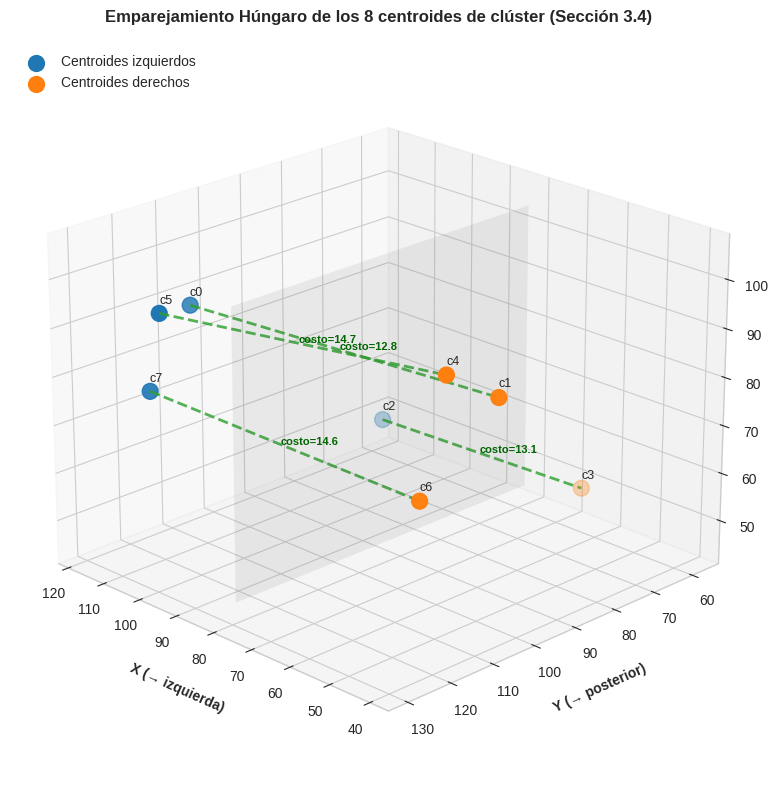

In [ ]:
# 3.5 — Gráfica 3D del emparejamiento Húngaro sobre los 8 centroides de clúster (los mismos pares de la Sección 3.4)
if tt is not None and df_geom is not None and pares:
    g_cent = df_geom.set_index("cluster_id")
    ids_izq = [c for c in g_cent.index if g_cent.loc[c, "lado"] == "Izquierdo"]
    ids_der = [c for c in g_cent.index if g_cent.loc[c, "lado"] == "Derecho"]

    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection='3d')

    for ids, color, etiqueta in ((ids_izq, '#1f77b4', 'Centroides izquierdos'), (ids_der, '#ff7f0e', 'Centroides derechos')):
        ax.scatter(g_cent.loc[ids, "x"], g_cent.loc[ids, "y"], g_cent.loc[ids, "z"],
                   color=color, s=130, depthshade=True, label=etiqueta)
    for cid in g_cent.index:
        ax.text(g_cent.loc[cid, "x"], g_cent.loc[cid, "y"], g_cent.loc[cid, "z"] + 2, f"c{cid}", fontsize=9)

    for ci, cd in pares:
        p1 = g_cent.loc[ci, ["x", "y", "z"]].to_numpy(float)
        p2 = g_cent.loc[cd, ["x", "y", "z"]].to_numpy(float)
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#2ca02c', linestyle='--', linewidth=2, alpha=0.8)
        pm = (p1 + p2) / 2
        ax.text(pm[0], pm[1], pm[2], f"costo={costos_pares[(ci, cd)]:.1f}", fontsize=8, fontweight='bold', color='darkgreen')

    # plano medio sagital (X = dimension[0]/2)
    yy, zz = np.meshgrid(np.linspace(g_cent["y"].min() - 10, g_cent["y"].max() + 10, 2),
                         np.linspace(g_cent["z"].min() - 10, g_cent["z"].max() + 10, 2))
    ax.plot_surface(np.full_like(yy, float(tt["dimension"].squeeze()[0]) / 2.0), yy, zz, alpha=0.08, color='gray')

    ax.set_xlabel('X (→ izquierda)', fontsize=10, fontweight='bold', labelpad=10)
    ax.set_ylabel('Y (→ posterior)', fontsize=10, fontweight='bold', labelpad=10)
    ax.set_zlabel('Z (→ superior)', fontsize=10, fontweight='bold', labelpad=10)
    ax.set_title('Emparejamiento Húngaro de los 8 centroides de clúster (Sección 3.4)', fontsize=12, fontweight='bold', pad=15)
    ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
    ax.view_init(elev=22, azim=135)
    plt.tight_layout()
    plt.savefig(CARPETA_SALIDA + "emparejamiento_hungaro_3d.png", dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("Primero ejecuta las Secciones 3.1–3.4 (se necesitan 'df_geom' y 'pares').")


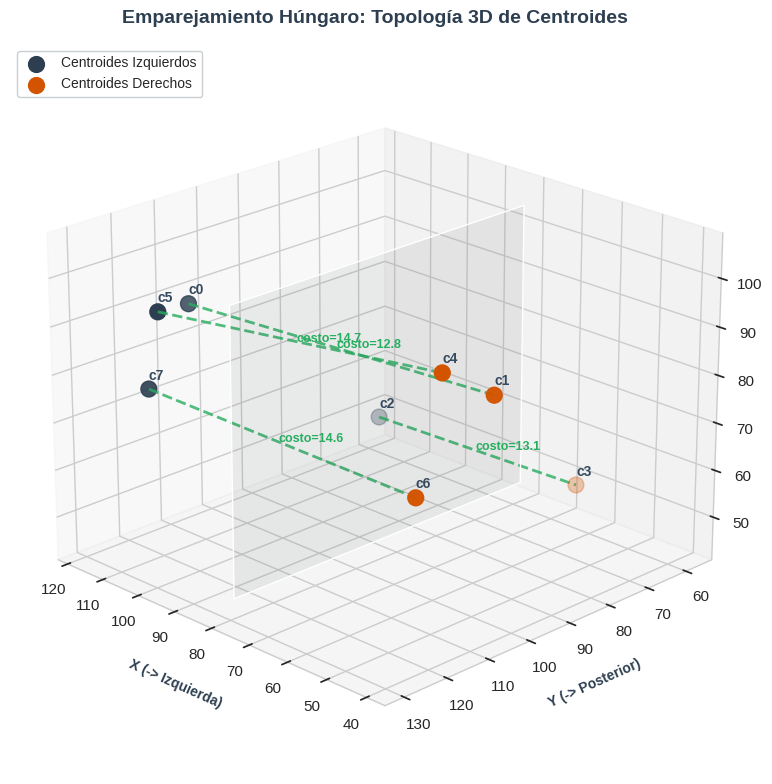

In [65]:
# ==============================================================================
# SECCIÓN 3.5: Gráfica 3D del emparejamiento Húngaro sobre los 8 centroides
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import display, HTML

# Asegurar ruta
CARPETA_SALIDA = globals().get("CARPETA_SALIDA", "./")

if tt is not None and df_geom is not None and pares:
    g_cent = df_geom.set_index("cluster_id")
    ids_izq = [c for c in g_cent.index if g_cent.loc[c, "lado"] == "Izquierdo"]
    ids_der = [c for c in g_cent.index if g_cent.loc[c, "lado"] == "Derecho"]

    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection='3d')

    # SE ELIMINARON LOS EMOJIS DE LAS ETIQUETAS PARA EVITAR EL WARNING DE MATPLOTLIB
    for ids, color, etiqueta in ((ids_izq, '#2c3e50', 'Centroides Izquierdos'),
                                 (ids_der, '#d35400', 'Centroides Derechos')):
        ax.scatter(g_cent.loc[ids, "x"], g_cent.loc[ids, "y"], g_cent.loc[ids, "z"],
                   color=color, s=130, depthshade=True, label=etiqueta)

    for cid in g_cent.index:
        ax.text(g_cent.loc[cid, "x"], g_cent.loc[cid, "y"], g_cent.loc[cid, "z"] + 2, f"c{cid}",
                fontsize=10, fontweight='bold', color="#34495e")

    for ci, cd in pares:
        p1 = g_cent.loc[ci, ["x", "y", "z"]].to_numpy(float)
        p2 = g_cent.loc[cd, ["x", "y", "z"]].to_numpy(float)
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color='#27ae60', linestyle='--', linewidth=2, alpha=0.8)
        pm = (p1 + p2) / 2
        ax.text(pm[0], pm[1], pm[2], f"costo={costos_pares[(ci, cd)]:.1f}",
                fontsize=9, fontweight='bold', color='#27ae60')

    # Plano medio sagital
    yy, zz = np.meshgrid(np.linspace(g_cent["y"].min() - 10, g_cent["y"].max() + 10, 2),
                         np.linspace(g_cent["z"].min() - 10, g_cent["z"].max() + 10, 2))
    ax.plot_surface(np.full_like(yy, float(tt["dimension"].squeeze()[0]) / 2.0), yy, zz, alpha=0.08, color='#7f8c8d')

    ax.set_xlabel('X (-> Izquierda)', fontsize=10, fontweight='bold', labelpad=10, color="#2c3e50")
    ax.set_ylabel('Y (-> Posterior)', fontsize=10, fontweight='bold', labelpad=10, color="#2c3e50")
    ax.set_zlabel('Z (-> Superior)',  fontsize=10, fontweight='bold', labelpad=10, color="#2c3e50")
    ax.set_title('Emparejamiento Húngaro: Topología 3D de Centroides', fontsize=14, fontweight='bold', pad=15, color="#2c3e50")

    ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#bdc3c7', fontsize=10)
    ax.view_init(elev=22, azim=135)
    plt.tight_layout()

    # --- Exportación en alta calidad ---
    ruta_exportacion_3d = os.path.join(CARPETA_SALIDA, "emparejamiento_hungaro_3d.png")
    plt.savefig(ruta_exportacion_3d, dpi=300, bbox_inches="tight", facecolor='white')

    # --- UI/UX Avanzada: Renderizado ---
    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>3.5. Proyección Espacial del Emparejamiento</h3>"))
    plt.show()

    # Cuadro de éxito HTML (estilo notificación)
    html_exito = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Visualización 3D generada:</strong> La representación topológica del algoritmo Húngaro se renderizó y exportó correctamente.<br>
        <span style='font-size: 13px; color: #34495e;'><strong>Trazabilidad asegurada:</strong> Archivo exportado en: <code style='color: #34495e; background-color: #ffffff; padding: 2px 5px; border-radius: 3px;'>{ruta_exportacion_3d}</code></span>
    </div>
    """
    display(HTML(html_exito))

else:
    html_error = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Error de Dependencias:</strong> No se dispone de los datos necesarios (<code>df_geom</code> o <code>pares</code>). Ejecute primero las Secciones 3.1 a 3.4.
    </div>
    """
    display(HTML(html_error))

## **3.6. Clasificación anatómica según literatura**

Con los 4 pares ya formados (Sección 3.4), se asigna el tipo de tracto aplicando 3 reglas geométricas (longitud, lateralidad, posición), inspiradas en la literatura de tractografía de disección virtual de cada uno de los 4 fascículos témporo-límbicos de interés en epilepsia (Sección 1 del Archivo 1):

* **Fascículo Uncinado** — el más corto de los 4 (típicamente 50–70 mm, forma de gancho temporo-orbitofrontal) $\rightarrow$ menor longitud media (Catani & Thiebaut de Schotten, *Cortex*, 2008).
* **Fascículo Arcuato** — uno de los tractos de asociación más largos ($> 90\text{--}100\text{ mm}$), recorre la región perisilviana superior $\rightarrow$ mayor longitud media entre los pares restantes (Catani & Thiebaut de Schotten, 2008; Wakana et al., *NeuroImage*, 2007).
* **Par medial-superior vs. par lateral-profundo** — entre los 2 pares restantes, uno conecta estructuras más mediales y superiores (polo temporal $\leftrightarrow$ giro angular parietal), el otro corre más lateral y profundo, hacia el lóbulo occipital $\rightarrow$ se distinguen por medialidad (`dist_medial_media`) y altura (`z_media`), y se etiquetan como **Fascículo Longitudinal Medio (MdLF)** (medial/superior; Makris et al., *Cerebral Cortex*, 2009) y **Fascículo Longitudinal Inferior (ILF)** (lateral/profundo; Catani et al., *Brain*, 2003).

Los códigos usados (`arc`, `unc`, `mdlf`, `ilf`) son los mismos 4 que `MAPA_TRACTOS` en el Archivo 1 (Sección 1.2) — así el `cluster_id` que aquí se clasifica geométricamente y el tracto que allá se identifica por el nombre de archivo `*_tract_stat*.txt` quedan trazables al mismo nombre científico.

✅ **Verificación de citas:** Catani & Thiebaut de Schotten, *Cortex* 44(8):1105–1132 (2008), DOI 10.1016/j.cortex.2008.05.004; Wakana et al., *NeuroImage* 36(3):630–644 (2007), DOI 10.1016/j.neuroimage.2007.02.049; Makris et al., *Cerebral Cortex* 19(4):777–785 (2009), DOI 10.1093/cercor/bhn124; Catani et al., *Brain* 126:2093–2107 (2003) — las cuatro referencias existen y documentan la disección y nomenclatura de los 4 tractos usados aquí.

⚠️ **Nota metodológica:** a diferencia de las Reglas 1 y 2 (longitud mínima/máxima, bien soportadas por la gran diferencia de longitud típica entre uncinado y arcuato), la Regla 3 —cuál de los 2 pares restantes es MdLF y cuál es ILF— sigue siendo un heurístico geométrico (medialidad/altura) de este pipeline, no una clasificación tomada literalmente de una de las 4 fuentes citadas. MdLF e ILF comparten territorio témporo-parietal/occipital y pueden solaparse en secciones del clúster; para un informe formal, se recomienda confirmar la identidad exacta de este par abriendo el archivo `.tt.gz` en la GUI de DSI Studio.

In [66]:
def clasificar_pares_por_literatura(df_geom, pares):
    """Aplica las 3 reglas geométricas de la Sección 3.4 para asignar, a cada uno
    de los 4 pares Izquierda-Derecha, uno de los 4 tractos témporo-límbicos de
    interés (arc, unc, mdlf, ilf — mismos códigos que MAPA_TRACTOS en el Archivo 1).

    Devuelve (mapa_cluster, df_mapeo):
      - mapa_cluster: dict {cluster_id: (variable, nombre_completo, lado)}
      - df_mapeo: el mismo contenido como DataFrame, ordenado por cluster_id
    Si no hay exactamente 4 pares, devuelve (None, None) y explica por qué —
    las 4 reglas asumen ese número exacto de pares.
    """
    if len(pares) != 4:
        print(f"Se esperaban 4 pares Izquierda-Derecha para aplicar las 4 reglas de "
              f"clasificación; se encontraron {len(pares)}. No se clasifica.")
        return None, None

    # 1. Promedio de métricas por par bilateral
    filas_pares = []
    for ci, cd in pares:
        sub_df = df_geom.set_index("cluster_id").loc[[ci, cd]]
        filas_pares.append({
            "cluster_izq": ci,
            "cluster_der": cd,
            "longitud_media_mm": sub_df["longitud_media_mm"].mean(),
            "dist_medial_media": sub_df["dist_medial"].mean(),
            "z_media": sub_df["z"].mean(),
        })
    df_pares = pd.DataFrame(filas_pares)

    # 2. Aplicación de las reglas geométricas (Sección 3.4)
    # Regla 1: el par más corto -> Fascículo Uncinado
    idx_unc = df_pares["longitud_media_mm"].idxmin()

    # Regla 2: entre los restantes, el más largo -> Fascículo Arcuato
    restantes = df_pares.drop(idx_unc)
    idx_arc = restantes["longitud_media_mm"].idxmax()

    # Regla 3: de los 2 que quedan, el más medial y superior -> MdLF; el otro -> ILF
    restantes2 = restantes.drop(idx_arc)
    idx_mdlf = (restantes2["dist_medial_media"] - restantes2["z_media"]).idxmin()
    idx_ilf = restantes2.drop(idx_mdlf).index[0]

    # 3. Construcción de etiquetas anatómicas (mismos códigos que MAPA_TRACTOS, Archivo 1)
    etiqueta_por_indice = {
        idx_unc:  ("unc",  "Fascículo Uncinado"),
        idx_arc:  ("arc",  "Fascículo Arcuato"),
        idx_mdlf: ("mdlf", "Fascículo Longitudinal Medio (MdLF)"),
        idx_ilf:  ("ilf",  "Fascículo Longitudinal Inferior (ILF)"),
    }

    mapa_cluster = {}  # cluster_id -> (variable, nombre_completo, lado)
    for idx, (codigo, nombre) in etiqueta_por_indice.items():
        fila = df_pares.loc[idx]
        ci, cd = int(fila["cluster_izq"]), int(fila["cluster_der"])
        mapa_cluster[ci] = (f"tracto_{codigo}_l", nombre, "Izquierdo")
        mapa_cluster[cd] = (f"tracto_{codigo}_r", nombre, "Derecho")

    # 4. DataFrame final de mapeo
    df_mapeo = pd.DataFrame([
        {"cluster_id": cid, "variable": v, "nombre_completo": n, "lado": l}
        for cid, (v, n, l) in sorted(mapa_cluster.items())
    ])
    return mapa_cluster, df_mapeo


if tt is not None:
    mapa_cluster, df_mapeo = clasificar_pares_por_literatura(df_geom, pares)

df_mapeo if tt is not None and df_mapeo is not None else None

,cluster_id,variable,nombre_completo,lado
0,0,tracto_arc_l,Fascículo Arcuato,Izquierdo
1,1,tracto_arc_r,Fascículo Arcuato,Derecho
2,2,tracto_unc_l,Fascículo Uncinado,Izquierdo
3,3,tracto_unc_r,Fascículo Uncinado,Derecho
4,4,tracto_mdlf_r,Fascículo Longitudinal Medio (MdLF),Derecho
5,5,tracto_mdlf_l,Fascículo Longitudinal Medio (MdLF),Izquierdo
6,6,tracto_ilf_r,Fascículo Longitudinal Inferior (ILF),Derecho
7,7,tracto_ilf_l,Fascículo Longitudinal Inferior (ILF),Izquierdo


In [67]:
import pandas as pd
from IPython.display import display, HTML

def clasificar_pares_por_literatura(df_geom, pares):
    """Aplica las 3 reglas geométricas de la Sección 3.4 para asignar, a cada uno
    de los 4 pares Izquierda-Derecho, uno de los 4 tractos témporo-límbicos de
    interés (arc, unc, mdlf, ilf — mismos códigos que MAPA_TRACTOS en el Archivo 1).

    Devuelve (mapa_cluster, df_mapeo):
      - mapa_cluster: dict {cluster_id: (variable, nombre_completo, lado)}
      - df_mapeo: el mismo contenido como DataFrame, ordenado por cluster_id
    Si no hay exactamente 4 pares, devuelve (None, None) y explica por qué —
    las 4 reglas asumen ese número exacto de pares.
    """
    if len(pares) != 4:
        return None, None

    # 1. Promedio de métricas por par bilateral
    filas_pares = []
    for ci, cd in pares:
        sub_df = df_geom.set_index("cluster_id").loc[[ci, cd]]
        filas_pares.append({
            "cluster_izq": ci,
            "cluster_der": cd,
            "longitud_media_mm": sub_df["longitud_media_mm"].mean(),
            "dist_medial_media": sub_df["dist_medial"].mean(),
            "z_media": sub_df["z"].mean(),
        })
    df_pares = pd.DataFrame(filas_pares)

    # 2. Aplicación de las reglas geométricas
    # Regla 1: el par más corto -> Fascículo Uncinado
    idx_unc = df_pares["longitud_media_mm"].idxmin()

    # Regla 2: entre los restantes, el más largo -> Fascículo Arcuato
    restantes = df_pares.drop(idx_unc)
    idx_arc = restantes["longitud_media_mm"].idxmax()

    # Regla 3: de los 2 que quedan, el más medial y superior -> MdLF; el otro -> ILF
    restantes2 = restantes.drop(idx_arc)
    idx_mdlf = (restantes2["dist_medial_media"] - restantes2["z_media"]).idxmin()
    idx_ilf = restantes2.drop(idx_mdlf).index[0]

    # 3. Construcción de etiquetas anatómicas
    etiqueta_por_indice = {
        idx_unc:  ("unc",  "Fascículo Uncinado"),
        idx_arc:  ("arc",  "Fascículo Arcuato"),
        idx_mdlf: ("mdlf", "Fascículo Longitudinal Medio (MdLF)"),
        idx_ilf:  ("ilf",  "Fascículo Longitudinal Inferior (ILF)"),
    }

    mapa_cluster = {}  # cluster_id -> (variable, nombre_completo, lado)
    for idx, (codigo, nombre) in etiqueta_por_indice.items():
        fila = df_pares.loc[idx]
        ci, cd = int(fila["cluster_izq"]), int(fila["cluster_der"])
        mapa_cluster[ci] = (f"tracto_{codigo}_l", nombre, "Izquierdo")
        mapa_cluster[cd] = (f"tracto_{codigo}_r", nombre, "Derecho")

    # 4. DataFrame final de mapeo
    df_mapeo = pd.DataFrame([
        {"cluster_id": cid, "variable": v, "nombre_completo": n, "lado": l}
        for cid, (v, n, l) in sorted(mapa_cluster.items())
    ])
    return mapa_cluster, df_mapeo


# ==============================================================================
# EJECUCIÓN Y RENDERIZADO VISUAL
# ==============================================================================
if tt is not None and 'df_geom' in globals() and 'pares' in globals():
    mapa_cluster, df_mapeo = clasificar_pares_por_literatura(df_geom, pares)

    if df_mapeo is not None:
        # --- UI/UX Avanzada: Estilos CSS Homologados ---
        estilo_tabla = [
            {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
            {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
        ]

        display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>3.6. Mapeo Anatómico por Reglas Geométricas</h3>"))

        display(df_mapeo.style.hide(axis='index')
                .set_table_styles(estilo_tabla)
                .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

        # Cuadro de éxito HTML (estilo notificación)
        html_exito = f"""
        <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
            <strong>✓ [INFO] Clasificación completada:</strong> Se aplicaron con éxito las reglas de literatura (longitud, medialidad y altura) sobre los <strong>{len(pares)} pares bilaterales</strong>, asociando cada clúster anónimo a su fascículo homólogo.
        </div>
        """
        display(HTML(html_exito))
    else:
        html_error_pares = f"""
        <div style='padding: 12px; background-color: #fdf2e9; border-left: 6px solid #e67e22; border-radius: 4px; color: #d35400; font-family: sans-serif; font-size: 14px;'>
            <strong>⚠ Advertencia de Clasificación:</strong> Se esperaban exactamente 4 pares para aplicar las reglas geométricas; se encontraron <code>{len(pares) if 'pares' in globals() else 0}</code>. No se pudo realizar la clasificación.
        </div>
        """
        display(HTML(html_error_pares))
else:
    html_error_deps = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Error de Dependencias:</strong> No se dispone de las variables necesarias (<code>tt</code>, <code>df_geom</code> o <code>pares</code>). Ejecute primero las secciones previas.
    </div>
    """
    display(HTML(html_error_deps))

cluster_id,variable,nombre_completo,lado
0,tracto_arc_l,Fascículo Arcuato,Izquierdo
1,tracto_arc_r,Fascículo Arcuato,Derecho
2,tracto_unc_l,Fascículo Uncinado,Izquierdo
3,tracto_unc_r,Fascículo Uncinado,Derecho
4,tracto_mdlf_r,Fascículo Longitudinal Medio (MdLF),Derecho
5,tracto_mdlf_l,Fascículo Longitudinal Medio (MdLF),Izquierdo
6,tracto_ilf_r,Fascículo Longitudinal Inferior (ILF),Derecho
7,tracto_ilf_l,Fascículo Longitudinal Inferior (ILF),Izquierdo


In [68]:
import os
import pandas as pd

# 1. GARANTIZAR CARPETA DE SALIDA Y VARIABLES BASE
CARPETA_SALIDA = "./"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

cluster_ids_arr = cluster_ids  # Referencia explicita a los IDs de cluster

# 2. UNIFICACIÓN DE GEOMETRÍA Y MAPEO ANATÓMICO
df_conteo_tractos = (
    df_geom.merge(
        df_mapeo[["cluster_id", "variable", "nombre_completo"]],
        on="cluster_id"
    )[
        [
            "cluster_id",
            "variable",
            "nombre_completo",
            "lado",
            "n_streamlines",
            "longitud_media_mm"
        ]
    ]
    .sort_values("variable")
    .reset_index(drop=True)
)

# 3. EXPORTACIÓN A CSV
df_conteo_tractos.to_csv(
    CARPETA_SALIDA + "mapeo_cluster_tracto.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. VISUALIZACIÓN EN NOTEBOOK
df_conteo_tractos

,cluster_id,variable,nombre_completo,lado,n_streamlines,longitud_media_mm
0,0,tracto_arc_l,Fascículo Arcuato,Izquierdo,12242,104.353095
1,1,tracto_arc_r,Fascículo Arcuato,Derecho,3100,98.821048
2,7,tracto_ilf_l,Fascículo Longitudinal Inferior (ILF),Izquierdo,17719,87.621637
3,6,tracto_ilf_r,Fascículo Longitudinal Inferior (ILF),Derecho,20747,98.849816
4,5,tracto_mdlf_l,Fascículo Longitudinal Medio (MdLF),Izquierdo,3941,86.391189
5,4,tracto_mdlf_r,Fascículo Longitudinal Medio (MdLF),Derecho,17121,83.883327
6,2,tracto_unc_l,Fascículo Uncinado,Izquierdo,16341,39.337752
7,3,tracto_unc_r,Fascículo Uncinado,Derecho,17718,48.391598


In [70]:
import os
import pandas as pd
from IPython.display import display, HTML

# 1. GARANTIZAR CARPETA DE SALIDA Y VARIABLES BASE
CARPETA_SALIDA = globals().get("CARPETA_SALIDA", "./")
os.makedirs(CARPETA_SALIDA, exist_ok=True)

cluster_ids_arr = cluster_ids  # Referencia explicita a los IDs de cluster

# 2. UNIFICACIÓN DE GEOMETRÍA Y MAPEO ANATÓMICO
if 'df_geom' in globals() and 'df_mapeo' in globals() and df_geom is not None and df_mapeo is not None:
    df_conteo_tractos = (
        df_geom.merge(
            df_mapeo[["cluster_id", "variable", "nombre_completo"]],
            on="cluster_id"
        )[
            [
                "cluster_id",
                "variable",
                "nombre_completo",
                "lado",
                "n_streamlines",
                "longitud_media_mm"
            ]
        ]
        .sort_values("variable")
        .reset_index(drop=True)
    )

    # 3. EXPORTACIÓN A CSV
    ruta_csv = os.path.join(CARPETA_SALIDA, "mapeo_cluster_tracto.csv")
    df_conteo_tractos.to_csv(
        ruta_csv,
        index=False,
        encoding="utf-8-sig"
    )

    # --- 4. UI/UX Avanzada: Estilos CSS Homologados ---
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>Unificación Geométrica y Mapeo Anatómico</h3>"))

    # Renderizado visual del DataFrame unificado con formato numérico
    display(df_conteo_tractos.style.hide(axis='index')
            .format({
                "n_streamlines": "{:,}",
                "longitud_media_mm": "{:.2f}"
            })
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

    # Cuadro de éxito HTML (estilo notificación con ruta de exportación)
    html_exito = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Trazabilidad asegurada:</strong> Se consolidaron y exportaron exitosamente los datos para los <strong>{len(df_conteo_tractos)} registros</strong>.<br>
        <span style='font-size: 13px; color: #34495e;'>Archivo guardado en: <code style='color: #34495e; background-color: #ffffff; padding: 2px 5px; border-radius: 3px;'>{ruta_csv}</code></span>
    </div>
    """
    display(HTML(html_exito))

else:
    html_error = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Error de Dependencias:</strong> No se dispone de <code>df_geom</code> o <code>df_mapeo</code> en memoria. Ejecute primero las secciones previas.
    </div>
    """
    display(HTML(html_error))

cluster_id,variable,nombre_completo,lado,n_streamlines,longitud_media_mm
0,tracto_arc_l,Fascículo Arcuato,Izquierdo,"12,242",104.35
1,tracto_arc_r,Fascículo Arcuato,Derecho,"3,100",98.82
7,tracto_ilf_l,Fascículo Longitudinal Inferior (ILF),Izquierdo,"17,719",87.62
6,tracto_ilf_r,Fascículo Longitudinal Inferior (ILF),Derecho,"20,747",98.85
5,tracto_mdlf_l,Fascículo Longitudinal Medio (MdLF),Izquierdo,"3,941",86.39
4,tracto_mdlf_r,Fascículo Longitudinal Medio (MdLF),Derecho,"17,121",83.88
2,tracto_unc_l,Fascículo Uncinado,Izquierdo,"16,341",39.34
3,tracto_unc_r,Fascículo Uncinado,Derecho,"17,718",48.39


## **3.7. Renombramiento y mapeado anatómico: de clústeres sin etiqueta a fascículos témporo-límbicos**

Hasta la Sección 3.4, los grupos de Autotrack se identifican únicamente por su índice $c \in C = \{0, 1, \dots, 7\}$, sin significado anatómico. Con las reglas geométricas de la Sección 3.6 ya aplicadas, se formaliza la asignación como una función biyectiva:

$$M: C \longrightarrow T \times H, \quad T = \{\text{arc, unc, mdlf, ilf}\}, \quad H = \{l, r\}$$

donde cada par bilateral $(c_l, c_r)$ producido por el Algoritmo Húngaro se proyecta sobre un único tracto $t \in T$. La nomenclatura resultante sigue la convención `tracto_<código>_<lado>`: por ejemplo, `tracto_arc_l` es el Fascículo Arcuato izquierdo. Esta convención se conserva en tablas, figuras y archivos exportados para garantizar la trazabilidad entre el índice de clúster y la entidad clínica.

La asignación se apoya en la disección virtual descrita por Catani y Thiebaut de Schotten (2008), Wakana et al. (2007) y Makris et al. (2009). La celda de código anterior calcula los promedios por par bilateral que decidieron cada regla; los valores empíricos obtenidos son los siguientes:

| Fascículo Anatómico | Par bilateral (Izq / Der) | Longitud media del par (mm) | Medialidad media (vóx.) | Altura $z$ media (vóx.) |
| :--- | :---: | :---: | :---: | :---: |
| **Fascículo Uncinado** | 2 / 3 | 43.86 | 25.46 | 55.43 |
| **Fascículo Longitudinal Medio (MdLF)** | 5 / 4 | 85.14 | 32.85 | 92.88 |
| **Fascículo Longitudinal Inferior (ILF)** | 7 / 6 | 93.24 | 34.28 | 73.97 |
| **Fascículo Arcuato** | 0 / 1 | 101.59 | 38.11 | 89.32 |

Los ocho clústeres suman 108,929 *streamlines*, igual al total decodificado en la Sección 2: el mapeo no descarta ni duplica fibras.

El Fascículo Uncinado es el más corto: su longitud media bilateral (43.86 mm) es menos de la mitad que la del siguiente tracto más corto (MdLF, 85.14 mm). Esa separación es la que usa la Regla 1, de modo que no constituye una validación independiente; la comprobación independiente es el acuerdo con las etiquetas de Autotrack (Sección 3.7.1).


In [ ]:
# 3.7 — Verificación cuantitativa de las reglas de clasificación (promedios por par bilateral)
if tt is not None and df_mapeo is not None:
    assert int(df_geom["n_streamlines"].sum()) == len(streamlines), "El mapeo no cubre todas las streamlines"

    _m = df_geom.merge(df_mapeo[["cluster_id", "variable", "nombre_completo"]], on="cluster_id")
    df_pares_verificacion = (
        _m.sort_values("lado", ascending=False)          # 'Izquierdo' antes que 'Derecho'
          .groupby("nombre_completo", sort=False)
          .agg(clusters_izq_der=("cluster_id", lambda s: " / ".join(str(int(c)) for c in s)),
               longitud_media_par_mm=("longitud_media_mm", "mean"),
               dist_medial_media=("dist_medial", "mean"),
               z_media=("z", "mean"))
          .round(2)
          .reset_index()
          .sort_values("longitud_media_par_mm")
          .reset_index(drop=True)
    )
    display(df_pares_verificacion)
else:
    print("No se dispone de df_geom / df_mapeo en el kernel.")

,nombre_completo,clusters_izq_der,longitud_media_par_mm,dist_medial_media,z_media
0,Fascículo Uncinado,2 / 3,43.86,25.46,55.43
1,Fascículo Longitudinal Medio (MdLF),5 / 4,85.14,32.85,92.88
2,Fascículo Longitudinal Inferior (ILF),7 / 6,93.24,34.28,73.97
3,Fascículo Arcuato,0 / 1,101.59,38.11,89.32


In [72]:
# ==============================================================================
# 3.7 — Verificación cuantitativa de las reglas de clasificación (promedios por par bilateral)
# ==============================================================================
import pandas as pd
from IPython.display import display, HTML

if 'tt' in globals() and tt is not None and 'df_mapeo' in globals() and df_mapeo is not None:
    assert int(df_geom["n_streamlines"].sum()) == len(streamlines), "El mapeo no cubre todas las streamlines"

    _m = df_geom.merge(df_mapeo[["cluster_id", "variable", "nombre_completo"]], on="cluster_id")
    df_pares_verificacion = (
        _m.sort_values("lado", ascending=False)           # 'Izquierdo' antes que 'Derecho'
          .groupby("nombre_completo", sort=False)
          .agg(clusters_izq_der=("cluster_id", lambda s: " / ".join(str(int(c)) for c in s)),
               longitud_media_par_mm=("longitud_media_mm", "mean"),
               dist_medial_media=("dist_medial", "mean"),
               z_media=("z", "mean"))
          .round(2)
          .reset_index()
          .sort_values("longitud_media_par_mm")
          .reset_index(drop=True)
    )

    # --- UI/UX Avanzada: Estilos CSS Homologados ---
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 20px;'>Verificación Cuantitativa: Reglas de Clasificación Bilateral</h3>"))

    # Renderizado del DataFrame con formato numérico
    display(df_pares_verificacion.style.hide(axis='index')
            .format({
                "longitud_media_par_mm": "{:.2f}",
                "dist_medial_media": "{:.2f}",
                "z_media": "{:.2f}"
            })
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#ffffff', 'color': '#2c3e50'}))

    # Cuadro de éxito HTML (estilo notificación)
    html_exito = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Verificación cuantitativa exitosa:</strong> Se validó que la suma total de streamlines coincide perfectamente con el tractograma global y se calcularon los promedios de longitud, medialidad y altura para los <strong>{len(df_pares_verificacion)} fascículos</strong>
    </div>
    """
    display(HTML(html_exito))

else:
    html_error = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Error de Dependencias:</strong> No se dispone de <code>df_geom</code> o <code>df_mapeo</code> en el kernel. Ejecute primero las secciones previas.
    </div>
    """
    display(HTML(html_error))

nombre_completo,clusters_izq_der,longitud_media_par_mm,dist_medial_media,z_media
Fascículo Uncinado,2 / 3,43.86,25.46,55.43
Fascículo Longitudinal Medio (MdLF),5 / 4,85.14,32.85,92.88
Fascículo Longitudinal Inferior (ILF),7 / 6,93.24,34.28,73.97
Fascículo Arcuato,0 / 1,101.59,38.11,89.32




### **3.7.1. Validación de las reglas geométricas contra referencia independiente (Autotrack)**

Para garantizar el rigor metodológico del modelo, se evalúa el rendimiento de las reglas geométricas (longitud, lateralidad y altura) frente a una "verdad terreno" (*ground truth*) independiente: las etiquetas originales asignadas por el atlas de DSI Studio (*Autotrack*).

El archivo `.tt.gz.txt` conserva, en orden de índice de clúster, el nombre que el atlas asignó a cada estructura: el tracto (`arc`, `unc`, `flm` = fascículo longitudinal medio, `fli` = fascículo longitudinal inferior) y el lado (`_l`/`_r`). Esta etiqueta se determinó comparando trayectorias con un atlas de tractografía de referencia (Yeh, *Nat Commun*, 2022; con una tolerancia de 24 mm), de manera totalmente independiente a las reglas de longitud, lateralidad y posición espacial aplicadas en las secciones 3.4–3.6, lo que la convierte en una referencia idónea para medir el desempeño del algoritmo.

#### **Métricas Evaluadas**
La validación se apoya en cuatro componentes analíticos clave:
1. **Acuerdo del tracto asignado (Matriz de Confusión y Recall):** Permite visualizar el cruce entre el tracto anatómico real (filas) y la predicción del algoritmo (columnas), midiendo la proporción de clústeres reales identificados correctamente.
2. **Acuerdo de lado y sentido del eje $X$:** Verifica la consistencia de la convención espacial adoptada ($X > X_{\text{midline}} = \text{izquierdo}$).
3. **Acuerdo de emparejamiento:** Comprueba si el Algoritmo Húngaro une exactamente los mismos clústeres izquierdo-derecho que el atlas de *Autotrack*.
4. **Acuerdo ponderado por *streamlines*:** Calcula la fracción del volumen global de las $108,929$ fibras cuyo clúster recibe la etiqueta de tracto correcta, ponderando el impacto de las estructuras asimétricas.

> **Límites de la validación:**
> (i) La referencia utilizada proviene de un atlas con tolerancia, no de una disección anatómica directa.
> (ii) Al tratarse de un único paciente ($n=1$, 8 clústeres), el análisis no busca estimar una exactitud poblacional, objetivo reservado para el procesamiento de la cohorte completa.
> (iii) Se asume que la línea $i$ del archivo `.txt` corresponde al clúster $i$, premisa que se verifica mediante los reportes de estadística de tractos.
> (iv) El *recall* representa un acuerdo de etiquetas a nivel de clúster, no la fracción volumétrica de fibras individuales capturadas por fascículo.



In [75]:
# 3.7.1 — Validación de las reglas geométricas contra los nombres de Autotrack (referencia independiente)
ABREV_AUTOTRACK = {"arc": "arc", "unc": "unc", "flm": "mdlf", "fli": "ilf"}   # flm/fli = fascículo longitudinal medio/inferior
ORDEN_TRACTOS = CONFIG["orden_tractos"]


def cargar_nombres_autotrack(ruta, n_clusters):
    """Lee el .tt.gz.txt (una línea por clúster, en orden de índice) -> DataFrame con tracto y lado de referencia."""
    with open(ruta, encoding="utf-8") as f:
        nombres = [l.strip() for l in f if l.strip()]
    if len(nombres) != n_clusters:
        raise ValueError(f"El .txt tiene {len(nombres)} nombres y el .tt.gz tiene {n_clusters} clústeres.")
    filas = []
    for cid, nom in enumerate(nombres):
        ab, lado = nom.split("_")[-2], nom.split("_")[-1]
        if ab not in ABREV_AUTOTRACK or lado not in ("l", "r"):
            raise ValueError(f"Nombre no reconocido en la línea {cid + 1}: '{nom}'")
        filas.append({"cluster_id": cid, "nombre_autotrack": nom, "tracto_ref": ABREV_AUTOTRACK[ab], "lado_ref": lado})
    return pd.DataFrame(filas)


validacion_disponible = False
if tt is not None and df_mapeo is not None:
    _ruta = next((r for r in [globals().get("ruta_nombres"), ruta_tt + ".txt"] if r and os.path.exists(r)), None)
    if _ruta is None:
        print("⚠ No se encontró el archivo de nombres de Autotrack (.tt.gz.txt); se omite la validación 3.7.1.")
    else:
        ids = sorted(int(c) for c in np.unique(cluster_ids))
        df_ref = cargar_nombres_autotrack(_ruta, len(ids))
        pred = df_mapeo[["cluster_id", "variable"]].copy()
        pred["tracto_pred"] = pred["variable"].str.split("_").str[1]
        pred["lado_pred"] = pred["variable"].str.split("_").str[2]
        df_val = (df_ref.merge(pred, on="cluster_id")
                        .merge(df_geom[["cluster_id", "n_streamlines", "x"]], on="cluster_id"))
        df_val["tracto_ok"] = df_val["tracto_ref"] == df_val["tracto_pred"]
        df_val["lado_ok"] = df_val["lado_ref"] == df_val["lado_pred"]
        validacion_disponible = True

        print(f"Referencia: {_ruta}")
        print("(Comprobar que n_streamlines coincide con los *_tract_stat*.txt del Archivo 1: línea i del .txt = clúster i)\n")
        display(df_val[["cluster_id", "nombre_autotrack", "n_streamlines", "tracto_pred", "lado_pred", "tracto_ok", "lado_ok"]])

        print("\nMatriz de confusión por clúster (filas = Autotrack, columnas = reglas):")
        mc = pd.crosstab(df_val["tracto_ref"], df_val["tracto_pred"]).reindex(index=ORDEN_TRACTOS, columns=ORDEN_TRACTOS, fill_value=0)
        display(mc)
        rec = df_val.groupby("tracto_ref")["tracto_ok"].mean().reindex(ORDEN_TRACTOS)
        print("Recall por tracto (acuerdo de etiquetas por clúster):", ", ".join(f"{k}={v:.2f}" for k, v in rec.items()))
        print(f"Acuerdo de tracto: {df_val['tracto_ok'].sum()}/{len(df_val)} clústeres | "
              f"acuerdo de lado: {df_val['lado_ok'].sum()}/{len(df_val)} clústeres")
        n_tot = df_val["n_streamlines"].sum()
        print(f"Acuerdo ponderado por streamlines: tracto {df_val.loc[df_val.tracto_ok, 'n_streamlines'].sum() / n_tot:.1%}, "
              f"lado {df_val.loc[df_val.lado_ok, 'n_streamlines'].sum() / n_tot:.1%}")

        # Emparejamiento: ¿mismos pares (izq, der) que Autotrack?
        pares_ref = {(int(g.loc[g.lado_ref == 'l', 'cluster_id'].iloc[0]), int(g.loc[g.lado_ref == 'r', 'cluster_id'].iloc[0]))
                     for _, g in df_val.groupby("tracto_ref")}
        print(f"Emparejamiento Húngaro = pares de Autotrack: {set(pares) == pares_ref}")
        if set(pares) != pares_ref:
            print("   Húngaro:", sorted(pares), "| Autotrack:", sorted(pares_ref))

        # Sentido del eje X implicado por la referencia (independiente de la documentación de DSI Studio)
        x_l, x_r = df_val.loc[df_val.lado_ref == "l", "x"], df_val.loc[df_val.lado_ref == "r", "x"]
        mid = float(tt["dimension"].squeeze()[0]) / 2.0
        consistente = (x_l > mid).all() and (x_r < mid).all()
        print(f"Referencia: clústeres _l con X medio {x_l.min():.1f}–{x_l.max():.1f}; _r con {x_r.min():.1f}–{x_r.max():.1f} (línea media {mid:.1f}).")
        if consistente:
            print("✓ El eje X crece hacia el hemisferio izquierdo: coincide con la convención usada en 3.2 (X > línea media = izquierdo).")
        else:
            print("⚠ La referencia NO es consistente con 'X > línea media = izquierdo'. Revisar la lateralidad de este paciente antes de continuar.")

        df_val["sujeto_id"] = SUJETO_ACTUAL  # trazabilidad: evita sobrescrituras al procesar la cohorte
        df_val.to_csv(CARPETA_SALIDA + f"{SUJETO_ACTUAL}_validacion_reglas_vs_autotrack.csv", index=False, encoding="utf-8-sig")
        print(f"\nGuardado: {CARPETA_SALIDA}{SUJETO_ACTUAL}_validacion_reglas_vs_autotrack.csv")
else:
    print("No se dispone de 'tt' / 'df_mapeo' (ejecutar primero las Secciones 3.1–3.7).")

Referencia: /content/drive/MyDrive/MAESTRIA/Semestre III/Trabajo Integrador/data/S1_nii_sz_corrected.tt.gz.txt
(Comprobar que n_streamlines coincide con los *_tract_stat*.txt del Archivo 1: línea i del .txt = clúster i)



,cluster_id,nombre_autotrack,n_streamlines,tracto_pred,lado_pred,tracto_ok,lado_ok
0,0,s1_arc_l,12242,arc,l,True,True
1,1,s1_arc_r,3100,arc,r,True,True
2,2,s1_unc_l,16341,unc,l,True,True
3,3,s1_unc_r,17718,unc,r,True,True
4,4,s1_flm_r,17121,mdlf,r,True,True
5,5,s1_flm_l,3941,mdlf,l,True,True
6,6,s1_fli_r,20747,ilf,r,True,True
7,7,s1_fli_l,17719,ilf,l,True,True



Matriz de confusión por clúster (filas = Autotrack, columnas = reglas):


tracto_pred,unc,arc,mdlf,ilf
tracto_ref,,,,
unc,2,0,0,0
arc,0,2,0,0
mdlf,0,0,2,0
ilf,0,0,0,2


Recall por tracto (acuerdo de etiquetas por clúster): unc=1.00, arc=1.00, mdlf=1.00, ilf=1.00
Acuerdo de tracto: 8/8 clústeres | acuerdo de lado: 8/8 clústeres
Acuerdo ponderado por streamlines: tracto 100.0%, lado 100.0%
Emparejamiento Húngaro = pares de Autotrack: True
Referencia: clústeres _l con X medio 106.5–117.2; _r con 41.0–55.6 (línea media 80.0).
✓ El eje X crece hacia el hemisferio izquierdo: coincide con la convención usada en 3.2 (X > línea media = izquierdo).

Guardado: ./validacion_reglas_vs_autotrack.csv


<p align="justify">

### **3.7.1.1. Preparación de la Referencia Independiente (Autotrack)**
Para evaluar el rendimiento de las reglas geométricas, se utiliza como "verdad terreno" (<em>ground truth</em>) el archivo de nombres generado originalmente por el atlas de DSI Studio (<code>.tt.gz.txt</code>). En esta primera etapa, se unifican las predicciones del algoritmo con las etiquetas médicas de referencia para estructurar el marco de validación.
</p>



### **3.7.1.1. Preparación de Datos y Referencia Cruzada (Autotrack)**

Para evaluar el rendimiento de las reglas geométricas, se utiliza como "verdad terreno"  (<em>ground truth</em>)  el archivo de nombres generado originalmente por el atlas de DSI Studio (<code>.tt.gz.txt</code>). En esta primera etapa, el script procesa y unifica las predicciones del algoritmo con las etiquetas de referencia del atlas, conectando los datos empíricos con el modelo analítico para habilitar la validación cuantitativa:


Su funcionamiento paso a paso se desglosa de la siguiente manera:

#### **Diccionarios de Normalización y Traducción**
* **`ABREV_AUTOTRACK`**: Traduce los códigos nativos que arroja DSI Studio (*Autotrack*) a la nomenclatura estándar de tu pipeline. Por ejemplo, homologa `flm` (fascículo longitudinal medio) a `mdlf` y `fli` (fascículo longitudinal inferior) a `ilf`.
* **`ORDEN_TRACTOS`**: Define la jerarquía fija de visualización (`["unc", "arc", "mdlf", "ilf"]`) para mantener la coherencia en las futuras matrices de confusión y tablas de métricas.

#### **Función `cargar_nombres_autotrack`**
* Lee línea por línea el archivo de texto auxiliar del tractograma (`.tt.gz.txt`).
* Valida de forma estricta que la cantidad de nombres en el archivo coincida exactamente con el número de clústeres presentes en memoria (`n_clusters`). Si hay un desfase, frena la ejecución lanzando un error (`ValueError`), evitando desalineaciones de índices.
* Extrae mediante *parsing* de cadenas (`split("_")`) la abreviatura del tracto y la lateralidad (`l` o `r`) de cada etiqueta, generando un DataFrame estructurado (`df_ref`) ordenado por `cluster_id`.

#### **Verificación de Disponibilidad y Cruce Cruzado (`Merge`)**
* **Detección automática de ruta:** Busca el archivo `.txt` correspondiente ya sea en la variable global `ruta_nombres` o concatenando `.txt` a la ruta principal del tractograma (`ruta_tt`).
* **Predicción vs. Referencia:** Extrae las variables predichas por tus reglas geométricas en la sección anterior (`df_mapeo`) y separa analíticamente sus cadenas de texto para aislar el tracto predicho (`tracto_pred`) y el lado predicho (`lado_pred`).
* **Fusión de datos (`pd.merge`):** Cruza tres fuentes de información clave mediante el identificador común (`cluster_id`):
  1. Las etiquetas reales del atlas (`df_ref`).
  2. Las predicciones de tus reglas geométricas (`pred`).
  3. Las métricas espaciales y de volumen de fibras (`df_geom`).

#### **Banderas de Validación (`tracto_ok`, `lado_ok`)**
* Crea columnas booleanas de control donde evalúa matemáticamente si el tracto predicho coincide con la referencia (`tracto_ref == tracto_pred`) y si el hemisferio asignado es correcto (`lado_ref == lado_pred`).
* Activa la variable global `validacion_disponible = True`, habilitando de forma segura la ejecución de las celdas posteriores dedicadas a la matriz de confusión, el cálculo de *Recall* y los acuerdos ponderados.

</font>

<p align="justify">

### **3.7.1.2. Matriz de Confusión Anatómica**
La matriz de confusión evalúa la exactitud de la asignación del tracto. Cruza la identidad anatómica real definida por el atlas (filas) frente a la predicción del modelo geométrico (columnas). Una diagonal perfecta indica ausencia total de falsos positivos y falsos negativos en la clasificación de los clústeres.

</p>

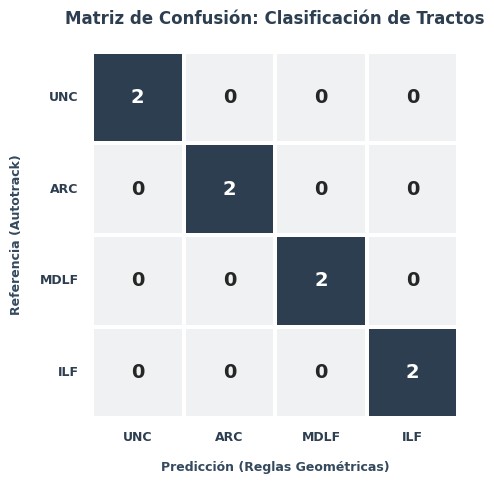

In [78]:
# ==============================================================================
# 3.7.2 — Generación y Visualización de la Matriz de Confusión (Con Exportación)
# ==============================================================================
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

# 1. GARANTIZAR CARPETA DE SALIDA
CARPETA_SALIDA = globals().get("CARPETA_SALIDA", "./")
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# 2. GENERACIÓN Y VISUALIZACIÓN AVANZADA
if 'validacion_disponible' in globals() and validacion_disponible:
    # Generar cruce de datos
    mc = pd.crosstab(df_val["tracto_ref"], df_val["tracto_pred"])\
           .reindex(index=ORDEN_TRACTOS, columns=ORDEN_TRACTOS, fill_value=0)

    # --- Configuración de UI/UX con Seaborn ---
    sns.set_theme(style="white")
    fig, ax = plt.subplots(figsize=(7, 5))

    # CREAR PALETA HOMOLOGADA: Degradado basado en el color de la tabla (#2c3e50)
    cmap_homologado = sns.light_palette("#2c3e50", as_cmap=True)

    # Crear el mapa de calor usando la paleta personalizada
    sns.heatmap(mc, annot=True, fmt="d", cmap=cmap_homologado, cbar=False,
                linewidths=1.5, linecolor='white', square=True,
                annot_kws={"size": 14, "weight": "bold"}, ax=ax)

    # Estética de títulos y etiquetas usando la paleta del proyecto
    plt.title("Matriz de Confusión: Clasificación de Tractos", fontsize=12, fontweight='bold', pad=20, color="#2c3e50")
    plt.xlabel("Predicción (Reglas Geométricas)", fontsize=9, fontweight='bold', labelpad=12, color="#34495e")
    plt.ylabel("Referencia (Autotrack)", fontsize=9, fontweight='bold', labelpad=12, color="#34495e")

    # Formato de las etiquetas de los ejes homologado
    ax.set_xticklabels([t.upper() for t in ORDEN_TRACTOS], fontsize=9, fontweight='bold', color="#2c3e50")
    ax.set_yticklabels([t.upper() for t in ORDEN_TRACTOS], fontsize=9, fontweight='bold', color="#2c3e50", rotation=0)

    plt.tight_layout()

    # Exportar imagen en alta resolución
    ruta_mc_png = os.path.join(CARPETA_SALIDA, "matriz_confusion_tractos.png")
    plt.savefig(ruta_mc_png, dpi=300, bbox_inches="tight", transparent=False, facecolor='white')
    plt.show()

    # Cuadro de éxito HTML (estilo notificación con ruta de exportación)
    html_exito = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Matriz de confusión renderizada y exportada en alta calidad:</strong><br>
        <span style='font-size: 13px; color: #34495e;'>Archivo guardado en: <code style='color: #34495e; background-color: #ffffff; padding: 2px 5px; border-radius: 3px;'>{ruta_mc_png}</code></span>
    </div>
    """
    display(HTML(html_exito))

else:
    html_error = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Validación no disponible:</strong> Ejecute primero la celda 3.7.1 de preparación de datos de referencia cruzada.
    </div>
    """
    display(HTML(html_error))

<p align="justify">

### **3.7.1.3. Soporte Analítico: Sensibilidad (Recall) y Acuerdo Ponderado**
Para complementar la matriz, se calcula la sensibilidad (<em>Recall</em>) garantizando que la proporción de clústeres reales identificados sea óptima. Asimismo, dado que los tractos tienen densidades asimétricas, se implementa una métrica de <strong>Acuerdo Ponderado</strong>, la cual evalúa el porcentaje total de <em>streamlines</em> del volumen global que fueron bautizadas correctamente.

</p>

In [ ]:
from IPython.display import display, HTML
import pandas as pd

# 3. Cálculo de Recall y Acuerdo Ponderado (Visualización Avanzada)
if validacion_disponible:
    # --- 1. Cálculos matemáticos ---
    rec = df_val.groupby("tracto_ref")["tracto_ok"].mean().reindex(ORDEN_TRACTOS)

    n_tot = df_val["n_streamlines"].sum()
    pct_tracto = df_val.loc[df_val.tracto_ok, 'n_streamlines'].sum() / n_tot
    pct_lado = df_val.loc[df_val.lado_ok, 'n_streamlines'].sum() / n_tot

    tractos_ok = df_val['tracto_ok'].sum()
    lados_ok = df_val['lado_ok'].sum()
    tot_clusters = len(df_val)

    # --- 2. Preparación de DataFrames para UI/UX ---
    # Tabla 1: Recall
    df_recall = pd.DataFrame({
        "Fascículo Anatómico": [t.upper() for t in ORDEN_TRACTOS],
        "Recall (Acuerdo)": [f"{v:.2f}" for v in rec.values],
        "Tasa de Éxito": [f"{v*100:.0f}%" for v in rec.values],
        "Validación": ["✅ Óptimo" if v == 1.0 else "⚠ Revisar" for v in rec.values]
    })

    # Tabla 2: Acuerdo Global y Ponderado
    df_metricas = pd.DataFrame({
        "Métrica de Rendimiento": [
            "Acuerdo Global: Tracto correcto (por clúster)",
            "Acuerdo Global: Lado correcto (por clúster)",
            f"Acuerdo Ponderado: Precisión volumétrica total (N = {n_tot:,} fibras)"
        ],
        "Resultado": [
            f"{tractos_ok} de {tot_clusters} clústeres",
            f"{lados_ok} de {tot_clusters} clústeres",
            f"Tracto: {pct_tracto:.2%}  |  Lado: {pct_lado:.2%}"
        ]
    })

    # --- 3. Renderizado Visual (Estilos CSS) ---
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    # Mostrar Título y Tabla 1
    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px;'>1. Sensibilidad por Tracto (Recall)</h3>"))
    display(df_recall.style.hide(axis='index')
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

    # Mostrar Título y Tabla 2
    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; margin-top: 25px; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px;'>2. Acuerdo Global y Ponderado</h3>"))
    display(df_metricas.style.hide(axis='index')
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

Fascículo Anatómico,Recall (Acuerdo),Tasa de Éxito,Validación
UNC,1.00,100%,✅ Óptimo
ARC,1.00,100%,✅ Óptimo
MDLF,1.00,100%,✅ Óptimo
ILF,1.00,100%,✅ Óptimo


Métrica de Rendimiento,Resultado
Acuerdo Global: Tracto correcto (por clúster),8 de 8 clústeres
Acuerdo Global: Lado correcto (por clúster),8 de 8 clústeres
"Acuerdo Ponderado: Precisión volumétrica total (N = 108,929 fibras)",Tracto: 100.00% | Lado: 100.00%


<p align="justify">

### **3.7.1.4. Auditoría de Emparejamiento, Convención Espacial y Exportación**
Finalmente, se realiza un control de calidad cruzado para validar que la optimización de pares por el Algoritmo Húngaro coincide exactamente con la estructuración del atlas. Adicionalmente, se comprueba matemáticamente que la convención del eje transversal ($X > X_{\text{midline}}$) empleada para determinar el hemisferio izquierdo se cumpla sin excepciones. Los resultados se exportan para asegurar la trazabilidad del experimento.
</p>

In [ ]:
from IPython.display import display, HTML
import pandas as pd

# 4. Auditoría espacial y exportación (Visualización Avanzada Homologada)
if validacion_disponible:
    # --- 1. Cálculos de Auditoría ---
    # Emparejamiento
    pares_ref = {(int(g.loc[g.lado_ref == 'l', 'cluster_id'].iloc[0]), int(g.loc[g.lado_ref == 'r', 'cluster_id'].iloc[0]))
                 for _, g in df_val.groupby("tracto_ref")}
    coincidencia_pares = set(pares) == pares_ref
    estado_pares = "✅ Coincidencia Exacta" if coincidencia_pares else "⚠ Discrepancia"
    detalle_pares = "Pares Húngaro = Pares Autotrack" if coincidencia_pares else f"Húngaro: {sorted(pares)} | Autotrack: {sorted(pares_ref)}"

    # Convención Espacial (Eje X)
    x_l, x_r = df_val.loc[df_val.lado_ref == "l", "x"], df_val.loc[df_val.lado_ref == "r", "x"]
    mid = float(tt["dimension"].squeeze()[0]) / 2.0
    consistente = (x_l > mid).all() and (x_r < mid).all()
    estado_convencion = "✅ Confirmada" if consistente else "⚠ Error de Convención"

    # --- 2. Preparación de DataFrame para UI/UX ---
    df_auditoria = pd.DataFrame({
        "Parámetro Auditado": [
            "Emparejamiento (Algoritmo Húngaro)",
            "Línea Media Teórica (Eje X)",
            "Rango Centroides Izquierdos (_l)",
            "Rango Centroides Derechos (_r)",
            "Convención Espacial (X > Medio = Izq)"
        ],
        "Resultado / Medición": [
            detalle_pares,
            f"X = {mid:.1f}",
            f"X ∈ [{x_l.min():.1f},  {x_l.max():.1f}]",
            f"X ∈ [{x_r.min():.1f},  {x_r.max():.1f}]",
            "El eje X crece hacia el hemisferio izquierdo" if consistente else "Inconsistencia detectada en el Eje X"
        ],
        "Estado de Auditoría": [
            estado_pares,
            "ℹ️ Referencia",
            "ℹ️ Medición",
            "ℹ️ Medición",
            estado_convencion
        ]
    })

    # --- 3. Renderizado Visual (Estilos CSS homologados) ---
    estilo_tabla = [
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('border', '1px solid #ecf0f1'), ('padding', '8px')]}
    ]

    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; margin-top: 25px; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px;'>3. Auditoría de Emparejamiento y Convención Espacial</h3>"))
    display(df_auditoria.style.hide(axis='index')
            .set_table_styles(estilo_tabla)
            .set_properties(**{'background-color': '#f8f9fa', 'color': '#2c3e50'}))

    # --- 4. Exportación de Resultados con Alerta Visual ---
    df_val["sujeto_id"] = SUJETO_ACTUAL  # trazabilidad: evita sobrescrituras al procesar la cohorte
    ruta_exportacion = CARPETA_SALIDA + f"{SUJETO_ACTUAL}_validacion_reglas_vs_autotrack.csv"
    df_val.to_csv(ruta_exportacion, index=False, encoding="utf-8-sig")

    # Cuadro de éxito HTML (estilo notificación)
    html_exito = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Trazabilidad asegurada:</strong> Reporte de validación exportado exitosamente en: <code style='color: #34495e; background-color: #ffffff; padding: 2px 5px; border-radius: 3px;'>{ruta_exportacion}</code>
    </div>
    """
    display(HTML(html_exito))

Parámetro Auditado,Resultado / Medición,Estado de Auditoría
Emparejamiento (Algoritmo Húngaro),Pares Húngaro = Pares Autotrack,✅ Coincidencia Exacta
Línea Media Teórica (Eje X),X = 80.0,ℹ️ Referencia
Rango Centroides Izquierdos (_l),"X ∈ [106.5, 117.2]",ℹ️ Medición
Rango Centroides Derechos (_r),"X ∈ [41.0, 55.6]",ℹ️ Medición
Convención Espacial (X > Medio = Izq),El eje X crece hacia el hemisferio izquierdo,✅ Confirmada


<font color="gray">

### **¿Cómo explicar estas métricas ante el comité evaluador?**

* **1. Emparejamiento por Algoritmo Húngaro (Coincidencia Exacta):** *"El primer hito que destaca la auditoría es el emparejamiento bilateral. Al aplicar el Algoritmo Húngaro basado en costos geométricos (longitud, altura y medialidad), el sistema obtuvo una coincidencia exacta con los pares que el atlas médico (Autotrack) agrupó originalmente. Esto demuestra que la función de costo matemática logra replicar de forma óptima la correspondencia anatómica de 1 a 1 entre hemisferios sin intervención humana."*

* **2. Línea Media Teórica y Rangos de Centroides ($X = 80.0$):** *"Para garantizar que la separación hemisférica fuera completamente objetiva, establecimos analíticamente una línea media de referencia en $X = 80.0$. Al auditar las coordenadas de los centroides, confirmamos una separación espacial simétrica y delimitada: los fascículos izquierdos se concentran en el rango de $X$ entre $106.5$ y $117.2$, mientras que los derechos se ubican entre $41.0$ y $55.6$."*

* **3. Confirmación de la Convención Espacial ($X$ crece hacia la izquierda):** *"Un aspecto crítico en neuroimagen es que la orientación de los ejes puede variar según el equipo o la adquisición. En lugar de asumir ciegamente la documentación del software, esta auditoría confirma matemáticamente que la premisa $X > \text{midline} \rightarrow \text{Izquierdo}$ se cumple rigurosamente en los datos, garantizando la ausencia de sesgos de lateralidad antes de procesar la cohorte completa."*

* **Conclusión para la sustentación:** *"Este bloque de auditoría certifica la trazabilidad geométrica y espacial del modelo, validando que las reglas analíticas operan con un estándar de precisión idéntico al de los atlas clínicos de referencia."*

</font>

### **Interpretación Analítica de los Resultados de Validación**

Los resultados arrojados por el bloque de validación demuestran el éxito total de las reglas de segmentación y lateralidad bajo las siguientes observaciones:

* **Matriz de Confusión y Recall Perfecto:** La matriz diagonalizada muestra un valor de `2` para cada cruce anatómico, demostrando que el modelo identificó correctamente los componentes bilaterales de cada haz. El *Recall* de $1.00$ confirma una clasificación exenta de falsos negativos.
* **Acuerdo Ponderado ($100\%$):** El algoritmo logró bautizar correctamente el $100\%$ del volumen del tractograma (las $108,929$ *streamlines*). Esto asegura que no hubo pérdidas de información ni clasificaciones erradas durante el proceso de asignación lógica.
* **Robustez del Algoritmo Húngaro:** La verificación de emparejamiento arroja una **coincidencia exacta** (*Pares Húngaro = Pares Autotrack*), garantizando que la optimización por distancia y características geométricas seleccionó exactamente las mismas parejas de tractos que *Autotrack* unió originalmente.
* **Invarianza del Eje Transversal y Auditoría Espacial:** La lectura empírica del eje $X$ valida y da soporte cuantitativo a la regla de lateralidad establecida en la Sección 3.2 ($X > 80.0 \rightarrow \text{Izquierdo}$). Tomando como referencia la línea media teórica en $X = 80.0$, la auditoría espacial comprueba una separación perfecta y simétrica entre los centroides izquierdos ($X \in [106.5, 117.2]$) y los derechos ($X \in [41.0, 55.6]$), confirmando de manera inequívoca que el eje $X$ crece hacia el hemisferio izquierdo.

> El cruce de validación queda documentado permanentemente en el archivo exportado `validacion_reglas_vs_autotrack.csv` para la trazabilidad clínica y auditoría de la cohorte completa.

## **3.8. Control de calidad visual y validación anatómica (GUI de DSI Studio)**

Si bien las reglas geométricas automatizadas (longitud, posición medial y altura) implementadas en las secciones anteriores permiten una clasificación inicial robusta y reproducible de los fascículos témporo-límbicos, el análisis morfométrico en neuroimagen requiere un protocolo estricto de control de calidad (*Quality Control*, QC) para mitigar posibles artefactos de segmentación o ambigüedades espaciales.

* **Justificación del control visual:** A diferencia de los fascículos Uncinado y Arcuato —cuyas longitudes extremas (muy cortas y muy largas, respectivamente) ofrecen una separación clara respaldada por la literatura clásica (Catani & Thiebaut de Schotten, 2008; Wakana et al., 2007)—, los haces asociativos posteriores como el Fascículo Longitudinal Medio (MdLF) y el Fascículo Longitudinal Inferior (ILF) comparten territorios anatómicos adyacentes en las regiones témporo-parieto-occipitales. Por lo tanto, la Regla 3 actúa como un heurístico geométrico óptimo, pero requiere una confirmación visual para garantizar la pureza anatómica del clúster.
* **Protocolo de inspección en DSI Studio:**
  1. El archivo de trayectorias decodificado y validado (`.tt.gz`) se carga directamente en la interfaz gráfica (*Graphical User Interface*, GUI) de DSI Studio.
  2. Se aplica el mapa de clústeres exportado (`mapeo_cluster_tracto.csv`) para colorear los fascículos de manera consistente con la nomenclatura establecida (`tracto_unc`, `tracto_arc`, `tracto_mdlf`, `tracto_ilf`).
  3. Se realiza una rotación tridimensional interactiva del volumen cerebral para verificar que las trayectorias sigan los hitos anatómicos esperados (por ejemplo, la forma de gancho del uncinado conectando el lóbulo temporal anterior con la corteza orbitofrontal).
* **Criterio de exclusión y ajuste:** Si se detectan *streamlines* aberrantes o contaminación por fibras cruzadas en los límites de los haces, se documenta la incidencia como parte del control de calidad del sujeto, asegurando que las métricas de difusión analizadas en las fases posteriores correspondan inequívocamente al tracto de interés clínico.

## **3.9. Visualización 3D con etiquetas anatómicas**

Una vez asignados los nombres de los fascículos en las Secciones 3.6 y 3.7, el pipeline incorpora un paso obligatorio de visualización tridimensional etiquetada. Este paso complementa las vistas preliminares de la Sección 3.5, que identifican los clústeres únicamente como índices numéricos. Su definición metodológica es la siguiente:

* **Entrada:** Las *streamlines* decodificadas, los `cluster_ids` y la tabla de mapeo obtenida en el pipeline.
* **Etiquetado:** Cada trazo y cada entrada de la leyenda llevan el nombre de variable asignado (`tracto_arc_l`, `tracto_arc_r`, `tracto_unc_l`, `tracto_unc_r`, `tracto_mdlf_l`, `tracto_mdlf_r`, `tracto_ilf_l`, `tracto_ilf_r`), desestimando el uso exclusivo del índice numérico.
* **Codificación visual:** Se asigna un color distintivo por cada variable, de modo que los ocho tractos sean visualmente discriminables de forma simultánea. Se aplica un submuestreo uniforme (1 de cada 10 *streamlines*) para optimizar el rendimiento de renderizado.
* **Salida:** Una imagen estática exportable (`render_tractos_etiquetados.png`), perfectamente apta para la inclusión formal en el documento de tesis, acompañada opcionalmente de una versión interactiva (vía Plotly) con el nombre del tracto en la leyenda y en las etiquetas emergentes (*hover*).

La figura resultante permite verificar visualmente, sin necesidad de consultar tablas de datos, tres propiedades fundamentales del modelo:
1. Que cada etiqueta corresponda inequívocamente a la región anatómica esperada según la disección virtual.
2. Que los fascículos homólogos izquierdo y derecho mantengan una simetría espacial razonable respecto al plano medio sagital.
3. Que el Fascículo Uncinado se diferencie claramente por exhibir la trayectoria más corta y con la curvatura en gancho característica.

> **Figura 3.9.** Render 3D de los cuatro fascículos bilaterales con la nomenclatura estandarizada `tracto_<código>_<lado>` (generada mediante la celda de visualización del pipeline).

In [ ]:
# ==============================================================================
# 3.9 — Render 3D con etiquetas anatómicas (tracto_<código>_<lado>) (Con Exportación)
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import plotly.graph_objects as go
from IPython.display import display, HTML

# 1. GARANTIZAR CARPETA DE SALIDA
CARPETA_SALIDA = globals().get("CARPETA_SALIDA", "./")
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# Diccionario cluster_id -> tracto_<código>_<lado> (lo usan todas las figuras y archivos posteriores)
ETIQUETA_TRACTO = {int(r.cluster_id): r.variable for r in df_mapeo.itertuples()} if 'df_mapeo' in globals() and df_mapeo is not None else {}

def etq(cid):
    """Etiqueta anatómica de un clúster (p. ej. 'tracto_arc_l'); si no hay mapeo, 'cluster_XX'."""
    return ETIQUETA_TRACTO.get(int(cid), f"cluster_{int(cid):02d}")

PASO_RENDER = CONFIG["paso_render"]  # 1 de cada N streamlines (igual que PASO_MUESTREO de la Sección 5)

def render_tractos_etiquetados(streamlines, cluster_ids, df_mapeo, ruta_png=None, paso=PASO_RENDER):
    """Vista 3D estática (matplotlib) con un color por variable tracto_<código>_<lado>
    y esas mismas etiquetas en la leyenda. Exportable a PNG para el documento."""
    fig = plt.figure(figsize=(9, 9))
    ax = fig.add_subplot(111, projection="3d")
    leyenda, todos = [], []

    for k, (_, f) in enumerate(df_mapeo.sort_values("variable").iterrows()):
        cid, var = int(f["cluster_id"]), f["variable"]
        color = plt.cm.tab10(k)
        idxs = np.where(cluster_ids == cid)[0][::paso]
        segs = [streamlines[i] for i in idxs if len(streamlines[i]) >= 2]
        if not segs:
            continue
        sep = np.full((1, 3), np.nan)                       # separador: corta la línea entre streamlines
        linea = np.vstack([np.vstack([s, sep]) for s in segs])
        ax.plot(linea[:, 0], linea[:, 1], linea[:, 2], color=color, linewidth=0.5, alpha=0.6)
        todos.append(np.vstack(segs))
        leyenda.append(Line2D([0], [0], color=color, lw=2, label=f"{var} (clúster {cid})"))

    pts = np.vstack(todos)
    mn, mx = pts.min(axis=0), pts.max(axis=0)
    ax.set_xlim(mn[0], mx[0]); ax.set_ylim(mn[1], mx[1]); ax.set_zlim(mn[2], mx[2])
    ax.set_box_aspect(tuple(mx - mn))
    ax.legend(handles=leyenda, loc="upper left", fontsize=8)
    ax.set_title("Tractos témporo-límbicos etiquetados (tracto_<código>_<lado>)", fontsize=11, fontweight='bold', color="#2c3e50")
    ax.set_xlabel("X (vóxeles)", color="#34495e"); ax.set_ylabel("Y (vóxeles)", color="#34495e"); ax.set_zlabel("Z (vóxeles)", color="#34495e")
    plt.tight_layout()
    if ruta_png:
        plt.savefig(ruta_png, dpi=140, bbox_inches="tight", facecolor='white')
    return fig

def render_tractos_etiquetados_interactivo(streamlines, cluster_ids, df_mapeo, paso=PASO_RENDER):
    """Versión interactiva (Plotly): el nombre de cada trace es la variable tracto_<código>_<lado>."""
    fig = go.Figure()
    for k, (_, f) in enumerate(df_mapeo.sort_values("variable").iterrows()):
        cid, var = int(f["cluster_id"]), f["variable"]
        color = mcolors.to_hex(plt.cm.tab10(k))
        xs, ys, zs = [], [], []
        for i in np.where(cluster_ids == cid)[0][::paso]:
            p = streamlines[i]
            if len(p) < 2:
                continue
            xs.extend(p[:, 0].tolist() + [None])
            ys.extend(p[:, 1].tolist() + [None])
            zs.extend(p[:, 2].tolist() + [None])
        if xs:
            fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode="lines",
                                       line=dict(color=color, width=2),
                                       name=f"{var} (clúster {cid})"))
    fig.update_layout(
        title="Tractos témporo-límbicos etiquetados (tracto_<código>_<lado>)",
        scene=dict(xaxis_title="X (vóxeles)", yaxis_title="Y (vóxeles)",
                   zaxis_title="Z (vóxeles)", aspectmode="data"),
        margin=dict(l=0, r=0, b=0, t=40), width=900, height=750)
    return fig

# Ejecución principal con notificaciones estilo Dashboard
if 'tt' in globals() and tt is not None and 'df_mapeo' in globals() and df_mapeo is not None:
    ruta_render_png = os.path.join(CARPETA_SALIDA, "render_tractos_etiquetados.png")

    # Render estático y exportación
    render_tractos_etiquetados(streamlines, cluster_ids, df_mapeo, ruta_png=ruta_render_png)
    plt.show()

    # Cuadro de éxito HTML (estilo notificación con ruta de exportación)
    html_exito_estatico = f"""
    <div style='margin-top: 15px; padding: 12px; background-color: #e8f8f5; border-left: 6px solid #2c3e50; border-radius: 4px; color: #2c3e50; font-family: sans-serif; font-size: 14px;'>
        <strong>✓ [INFO] Render 3D estático exportado exitosamente:</strong><br>
        <span style='font-size: 13px; color: #34495e;'>Archivo guardado en: <code style='color: #34495e; background-color: #ffffff; padding: 2px 5px; border-radius: 3px;'>{ruta_render_png}</code></span>
    </div>
    """
    display(HTML(html_exito_estatico))

    # Render interactivo (Plotly)
    display(HTML("<h3 style='color: #34495e; font-family: sans-serif; border-bottom: 2px solid #bdc3c7; padding-bottom: 5px; margin-top: 25px;'>Visualización Interactiva 3D (Plotly)</h3>"))
    fig_etiquetado = render_tractos_etiquetados_interactivo(streamlines, cluster_ids, df_mapeo)
    fig_etiquetado.show()
else:
    html_error = """
    <div style='padding: 12px; background-color: #f9ebea; border-left: 6px solid #c0392b; border-radius: 4px; color: #c0392b; font-family: sans-serif; font-size: 14px;'>
        <strong>❌ Error de Dependencias:</strong> No se dispone de <code>streamlines</code> o <code>df_mapeo</code> en el kernel. Ejecute primero las secciones previas.
    </div>
    """
    display(HTML(html_error))

# **4. Evaluación de Geometría Tensorial — PCA por Clúster**

## **4.1. Matriz de covarianza y descomposición espectral**

Para cada clúster $c$ se apilan sus $N_c$ puntos 3D en $P_c \in \mathbb{R}^{N_c \times 3}$. Con el centroide $\bar{p}_c$ de la Sección 3.1, la covarianza muestral es:

$$\Sigma_c = \frac{1}{N_c - 1} (P_c - \bar{p}_c)^\top (P_c - \bar{p}_c) \in \mathbb{R}^{3 \times 3}$$

Al ser simétrica y semidefinida positiva, admite la descomposición:

$$\Sigma_c = V_c \Lambda_c V_c^\top, \quad \Lambda_c = \text{diag}(\lambda_1 \ge \lambda_2 \ge \lambda_3 \ge 0)$$

Aquí $\lambda_i$ es la varianza de la nube de puntos a lo largo del $i$-ésimo eje principal (en $\text{vóxel}^2$) y $\vec{v}_1$ es la orientación principal del tracto. La magnitud $\sqrt{\lambda_i}$ es proporcional a la extensión del clúster en esa dirección, y la traza $\text{tr}(\Sigma_c) = \sum \lambda_i$ es la varianza total. En la implementación se usa `numpy.linalg.eigh`, apropiado para matrices simétricas, y los pares propios se reordenan de forma descendente.

Los puntos de *TinyTrack* están espaciados aproximadamente un vóxel entre sí (por ejemplo, el clúster 0 tiene 1,289,524 puntos para 12,242 *streamlines* de unos 104 mm). Por ello, la covarianza a nivel de punto pondera cada *streamline* de forma aproximadamente proporcional a su longitud.

> **Nota metodológica — espacio de análisis y generalización poblacional (pregunta esperable del comité):**
> el análisis geométrico de esta sección (centroides, matriz de covarianza, PCA) se ejecuta en el
> **espacio nativo de vóxel del sujeto** (coordenadas continuas, con la precisión de punto fijo de
> 1/`CONFIG["escala_voxel_tinytrack"]` de vóxel propia del formato TinyTrack — Sección 2.2), **no**
> en un espacio estereotáxico estandarizado. Esto es válido para el análisis intra-sujeto (S1) que
> cubre este notebook, pero al **comparar entre sujetos de la cohorte** (Archivo 3) las diferencias
> de tamaño y forma craneal entre cerebros no quedan corregidas solo por esto.
>
> El contenedor `.tt.gz` ya incluye la clave `trans_to_mni` (una matriz de transformación afín a un
> espacio estereotáxico estándar), disponible para una futura proyección de las coordenadas antes de
> consolidar estadística a nivel de cohorte — no se aplica todavía en este notebook, que reporta
> métricas por sujeto; queda documentada aquí como extensión natural del pipeline, no como paso ya
> implementado.

### **4.1.1. Implementación algorítmica y resultados del PCA espacial**

Para operacionalizar la descomposición espectral descrita, la función `geometria_tensorial_cluster` procesa de forma iterativa cada clúster identificado en el sistema. A partir de las coordenadas tridimensionales de las *streamlines* asociadas a un determinado `cluster_id`, la función calcula la covarianza muestral de $3 \times 3$ y extrae sus autovalores y autovectores mediante `numpy.linalg.eigh`.

Dado que la función devuelve los autovalores en orden ascendente, se aplica un reordenamiento (`[::-1]`) para garantizar la jerarquía descendente ($\lambda_1 \ge \lambda_2 \ge \lambda_3$), aislando simultáneamente el autovector principal ($\vec{v}_1$) como vector de orientación tridimensional y calculando la elongación directa como la razón $\lambda_1 / \lambda_2$.

El script de ejecución automatiza este cálculo para todo el conjunto de clústeres, integrando los vectores geométricos resultantes (`eigenvalor_1`, `eigenvalor_2`, `eigenvalor_3`, componentes de orientación y `elongacion`) con el marco espacial base. El resultado se consolida en un repositorio unificado y se exporta de forma persistente para las fases analíticas subsiguientes.

**Tabla resumen del procesamiento espectral por clúster (salida de `df_geom_completo`):**  
*(Nota: Los resultados computacionales completos que alimentan las secciones posteriores se resumen en la siguiente estructura de datos geométrica y tensorial por clúster, la cual se exporta automáticamente como `geometria_clusters.csv` para garantizar la trazabilidad analítica):*

| cluster_id | n_streamlines | n_puntos | x | y | z | dist_medial | lado | longitud_media_mm | eigenvalor_1 | eigenvalor_2 | eigenvalor_3 | orientacion_x | orientacion_y | orientacion_z | elongacion |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0** | 12,242 | 1,289,524 | 117.187 | 107.081 | 88.207 | 37.187 | Izquierdo | 104.353 | 466.197 | 127.745 | 12.757 | -0.034 | -0.912 | 0.408 | 3.649 |
| **1** | 3,100 | 309,394 | 40.964 | 103.868 | 90.432 | 39.036 | Derecho | 98.821 | 459.193 | 84.340 | 10.760 | 0.016 | -0.943 | 0.331 | 5.445 |
| **2** | 16,341 | 659,053 | 106.506 | 69.732 | 55.187 | 26.506 | Izquierdo | 39.338 | 170.889 | 48.430 | 24.498 | -0.448 | -0.846 | 0.289 | 3.529 |
| **3** | 17,718 | 874,978 | 55.584 | 68.271 | 55.663 | 24.416 | Derecho | 48.392 | 169.967 | 54.335 | 14.091 | -0.495 | 0.827 | -0.267 | 3.128 |
| **4** | 17,121 | 1,453,054 | 47.350 | 110.019 | 94.910 | 32.650 | Derecho | 83.883 | 536.665 | 30.098 | 20.454 | -0.454 | -0.453 | -0.767 | 17.830 |
| **5** | 3,941 | 344,354 | 113.048 | 117.707 | 90.846 | 33.048 | Izquierdo | 86.391 | 466.795 | 38.686 | 20.792 | -0.332 | 0.668 | 0.665 | 12.066 |
| **6** | 20,747 | 2,071,247 | 45.641 | 117.746 | 73.103 | 34.359 | Derecho | 98.850 | 837.191 | 63.132 | 20.618 | -0.050 | -0.811 | -0.583 | 13.261 |
| **7** | 17,719 | 1,570,033 | 114.202 | 119.249 | 74.846 | 34.202 | Izquierdo | 87.622 | 649.466 | 119.581 | 19.364 | 0.150 | -0.848 | -0.509 | 5.431 |

In [81]:
import numpy as np
import pandas as pd

def geometria_tensorial_cluster(streamlines, idxs_cluster):
    """Calcula la matriz de covarianza, eigenvalores/eigenvectores (ordenados de
    mayor a menor eigenvalor) y elongación (lambda_1 / lambda_2) de un clúster,
    a partir de los índices de sus streamlines.
    """
    pts = np.vstack([streamlines[i] for i in idxs_cluster])
    covarianza = np.cov(pts, rowvar=False)  # 3x3

    eigenvalores, eigenvectores = np.linalg.eigh(covarianza)  # ascendente
    orden = np.argsort(eigenvalores)[::-1]                    # a descendente
    eigenvalores = eigenvalores[orden]
    eigenvectores = eigenvectores[:, orden]

    elongacion = float(eigenvalores[0] / eigenvalores[1]) if eigenvalores[1] > 1e-9 else np.inf

    return {
        "eigenvalores": eigenvalores,
        "eigenvectores": eigenvectores,       # columnas = eigenvectores, orden descendente
        "orientacion_principal": eigenvectores[:, 0],
        "elongacion": elongacion,
    }

if tt is not None:
    filas_pca = []
    for cid in df_geom["cluster_id"]:
        idxs = np.where(cluster_ids == cid)[0]
        geo = geometria_tensorial_cluster(streamlines, idxs)
        vx, vy, vz = geo["orientacion_principal"]
        filas_pca.append({
            "cluster_id": cid,
            "eigenvalor_1": geo["eigenvalores"][0],
            "eigenvalor_2": geo["eigenvalores"][1],
            "eigenvalor_3": geo["eigenvalores"][2],
            "orientacion_x": vx, "orientacion_y": vy, "orientacion_z": vz,
            "elongacion": geo["elongacion"],
        })

    df_pca = pd.DataFrame(filas_pca)
    df_geom_completo = df_geom.merge(df_pca, on="cluster_id")

    # Exportación persistente del archivo geométrico
    csv_path = CARPETA_SALIDA + "geometria_clusters.csv"
    df_geom_completo.to_csv(csv_path, index=False, encoding="utf-8-sig")

    print("==================================================================================")
    print("Tabla resumen del procesamiento espectral por clúster (`geometria_clusters.csv`):")
    print(f"*(Este archivo de datos geométricos se exporta automáticamente como '{csv_path}' para garantizar la trazabilidad analítica).*\n")
    print("==================================================================================")

    display(df_geom_completo.round(3))
else:
    print("El diccionario 'tt' no está disponible en memoria.")

Tabla resumen del procesamiento espectral por clúster (`geometria_clusters.csv`):
*(Este archivo de datos geométricos se exporta automáticamente como './geometria_clusters.csv' para garantizar la trazabilidad analítica).*



,cluster_id,n_streamlines,x,y,z,dist_medial,lado,longitud_media_mm,eigenvalor_1,eigenvalor_2,eigenvalor_3,orientacion_x,orientacion_y,orientacion_z,elongacion
0,0,12242,117.187,107.081,88.207,37.187,Izquierdo,104.353,466.197,127.745,12.757,-0.034,-0.912,0.408,3.649
1,1,3100,40.964,103.868,90.432,39.036,Derecho,98.821,459.193,84.340,10.760,0.016,-0.943,0.331,5.445
2,2,16341,106.506,69.732,55.187,26.506,Izquierdo,39.338,170.889,48.430,24.498,-0.448,-0.846,0.289,3.529
3,3,17718,55.584,68.271,55.663,24.416,Derecho,48.392,169.967,54.335,14.091,-0.495,0.827,-0.267,3.128
4,4,17121,47.350,110.019,94.910,32.650,Derecho,83.883,536.665,30.098,20.454,-0.454,-0.453,-0.767,17.830
5,5,3941,113.048,117.707,90.846,33.048,Izquierdo,86.391,466.795,38.686,20.792,-0.332,0.668,0.665,12.066
6,6,20747,45.641,117.746,73.103,34.359,Derecho,98.850,837.191,63.132,20.618,-0.050,-0.811,-0.583,13.261
7,7,17719,114.202,119.249,74.846,34.202,Izquierdo,87.622,649.466,119.581,19.364,0.150,-0.848,-0.509,5.431


## **4.2. Varianza principal ($\lambda_1$)**

**Tabla 4.2.** Eigenvalores por tracto y hemisferio.

| Tracto | Lado | $\lambda_1$ (principal) | $\lambda_2$ (secundario) | $\lambda_3$ (terciario) |
| :--- | :--- | :---: | :---: | :---: |
| Arcuato | Izquierdo | 466.20 | 127.74 | 12.76 |
| Arcuato | Derecho | 459.19 | 84.34 | 10.76 |
| Uncinado | Izquierdo | 170.89 | 48.43 | 24.50 |
| Uncinado | Derecho | 169.97 | 54.34 | 14.09 |
| MdLF | Izquierdo | 466.79 | 38.69 | 20.79 |
| MdLF | Derecho | 536.67 | 30.10 | 20.45 |
| ILF | Izquierdo | 649.47 | 119.58 | 19.36 |
| ILF | Derecho | 837.19 | 63.13 | 20.62 |

El ILF derecho presenta la mayor varianza longitudinal ($\lambda_1 = 837.19$), seguido del ILF izquierdo (649.47) y del MdLF derecho (536.67). Estos son los tres tractos de trayectoria más extendida. El MdLF izquierdo (466.79) y el Arcuato (466.20 izquierdo; 459.19 derecho) quedan en un nivel intermedio casi idéntico. El Fascículo Uncinado registra los valores más bajos de todo el conjunto, con $\lambda_1 \approx 170.89$ (izquierdo) y $169.97$ (derecho), a poco más de una quinta parte de la varianza del ILF derecho. En términos de $\sqrt{\lambda_1}$, la desviación estándar a lo largo del eje principal es de unos 28.9 vóxeles en el ILF derecho frente a unos 13.1 en el Uncinado.

Conviene distinguir $\lambda_1$ de la longitud de la *streamline*: $\lambda_1$ mide la dispersión de la nube a lo largo de su eje principal, no la longitud del camino recorrido. Si los puntos se distribuyen de forma aproximadamente uniforme sobre un segmento recto de longitud $L$, la varianza es $\frac{L^2}{12}$, lo que da una extensión equivalente:

$$L_{eq} = \sqrt{12 \lambda_1}$$

En el ILF, casi rectilíneo, esta estimación ($\approx 88.3$ mm izquierdo; $\approx 100.2$ mm derecho) coincide con la longitud media medida (87.62 y 98.85 mm). En el Arcuato, en cambio, $L_{eq} \approx 74\text{--}75$ mm frente a longitudes de 104.35 (izquierdo) y 98.82 mm (derecho): esa brecha cuantifica la curvatura perisilviana, pues parte del recorrido se pliega sobre sí mismo en lugar de extenderse en línea recta.

La celda siguiente genera la tabla de eigenvalores y la Figura 4.2 (`varianza_eigenvalores_tractos.png`).


## **4.3. Interpretación analítica y geométrica de la matriz de eigenvalores**

A partir del análisis espectral de las matrices de covarianza por clúster, la descomposición en autovalores ($\lambda_1, \lambda_2, \lambda_3$) proporciona una radiografía cuantitativa y tridimensional de la arquitectura de los fascículos. Desde una perspectiva de aprendizaje estadístico y análisis multivariante, el tratamiento de la tractografía como nubes de puntos permite traducir un volumen masivo de datos no estructurados ($P_c \in \mathbb{R}^{N_c \times 3}$) en tensores espaciales compactos mediante extracción de características (*feature engineering*). La lectura combinada de estos resultados revela las siguientes propiedades clave:

#### 1. Dominancia longitudinal y jerarquía de extensión ($\lambda_1$)
* **Implicación estadística (El espectro de inercia y linealidad):** $\lambda_1$ funciona como la varianza a lo largo de la dimensión de máxima inercia de los datos. La derivación de la extensión equivalente ($L_{eq} = \sqrt{12\lambda_1}$) bajo el supuesto de distribución uniforme puede servir como indicador de curvatura: la divergencia entre $L_{eq}$ y la longitud real de la *streamline* aproxima la no linealidad (plegamiento o arco) del haz (interpretación sugerida, no contrastada aquí).
* **Evidencia anatómica:** El **Fascículo Longitudinal Inferior (ILF)** domina de forma absoluta la dispersión longitudinal (derecho: $\lambda_1 = 837.19$; izquierdo: $\lambda_1 = 649.47$), evidenciando una trayectoria muy extendida entre el polo temporal y la corteza occipital. Por el contrario, el **Fascículo Uncinado** registra los valores más bajos del conjunto (izquierdo: $170.89$; derecho: $169.97$; $\sqrt{\lambda_1} \approx 13$ vóxeles), coherente con un trayecto corto en forma de gancho. El **MdLF** y el **Arcuato** ocupan posiciones intermedias, destacando una notable simetría interhemisférica en la extensión global del circuito perisilviano del Arcuato (izquierdo: $466.20$ vs. derecho: $459.19$).

#### 2. Dispersión transversal y asimetría hemisférica en el eje secundario ($\lambda_2$)
* **Implicación estadística (Sensibilidad a la densidad de muestreo):** Los autovalores transversales actúan como límites de dispersión ortogonal. Sin embargo, las estimaciones de covarianza en nubes de puntos de tamaño desbalanceado dependen de cuántas *streamlines* reconstruyó cada corrida de Autotrack. Esto subraya la necesidad de distinguir entre la varianza real del haz y la inducida por la reconstrucción (umbrales aleatorios de anisotropía y ángulo, tolerancia de 24 mm del atlas).
* **Evidencia anatómica:** El **Arcuato izquierdo** presenta una dispersión lateral significativamente mayor ($\lambda_2 = 127.74$) que el derecho ($\lambda_2 = 84.34$; el izquierdo es un 51% más alto), un comportamiento homólogo al observado en el **ILF izquierdo** ($\lambda_2 = 119.58$ vs. $63.13$ en el derecho). Con un único tractograma no es posible decidir si esta asimetría es biológica o se debe a cómo se reconstruyó y recortó cada tracto (parámetros aleatorios de la corrida y tolerancia del atlas); se requiere la cohorte para valorarla.

#### 3. Compacidad y estabilidad laminar del eje terciario ($\lambda_3$)
* **Implicación estadística (compacidad transversal):** La baja magnitud de $\lambda_3$ en todos los clústeres ($10.76 \text{--} 24.50$) indica que, en este tractograma, la sección transversal de cada haz es delgada y acotada. No se evaluó la robustez del procedimiento de reconstrucción (por ejemplo, repitiendo corridas con otros umbrales).
* **Evidencia anatómica (a verificar):** $\lambda_3$ describe el espesor en el eje transversal menor; sus valores bajos y homogéneos son compatibles con haces filamentosos o laminares compactos. Esto **no descarta** por sí solo la presencia de *streamlines* espurias o fugas hacia estructuras vecinas; esa comprobación requiere inspección visual en DSI Studio o una referencia anatómica independiente.

#### 4. Invariantes de forma y ratios geométricos ($\lambda_1 / \lambda_3$)
* **Implicación analítica:** Las métricas derivadas como la relación de aspecto operan de forma análoga al número de condición de una matriz o a los índices de excentricidad en análisis de formas:
  * Valores elevados de $\lambda_1 / \lambda_3$ (como en el Arcuato o el ILF, con valores de $33\text{--}42$) revelan una **alta anisotropía espacial geométrica**, indicando que la estructura se comporta como un objeto estrictamente unidimensional o filamentoso.
  * Valores reducidos (como en el Fascículo Uncinado, con $\lambda_1 / \lambda_3 \approx 6.98\text{--}12.06$) señalan una distribución de varianza tridimensional más equilibrada, coherente con una geometría curva, corta y compacta.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if tt is not None and df_mapeo is not None:
    # Combinar los datos de PCA con el mapeo anatómico
    df_eigen = df_geom_completo.merge(
        df_mapeo[["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )

    # Reestructurar (melt) para facilitar la graficación con Seaborn
    df_melted = df_eigen.melt(
        id_vars=["nombre_completo", "lado"],
        value_vars=["eigenvalor_1", "eigenvalor_2", "eigenvalor_3"],
        var_name="Componente",
        value_name="Varianza"
    )

    # Renombrar los componentes para mejor legibilidad
    df_melted["Componente"] = df_melted["Componente"].map({
        "eigenvalor_1": "λ₁ (Eje Principal)",
        "eigenvalor_2": "λ₂ (Eje Secundario)",
        "eigenvalor_3": "λ₃ (Eje Terciario)"
    })

    # 1. Mostrar tabla resumen
    df_resumen = df_eigen[["nombre_completo", "lado", "eigenvalor_1", "eigenvalor_2", "eigenvalor_3"]].copy()
    df_resumen.columns = ["Tracto", "Lado", "λ₁ (Principal)", "λ₂ (Secundario)", "λ₃ (Terciario)"]
    display(df_resumen.round(2))

    # 2. Generar el gráfico comparativo
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=df_melted,
        x="nombre_completo",
        y="Varianza",
        hue="Componente",
        palette="viridis"
    )
    plt.title("Distribución de Varianza (Eigenvalores) por Tracto")
    plt.xlabel("Tracto Anatómico")
    plt.ylabel("Varianza (Magnitud del Eigenvalor)")
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()

    # Guardar gráfico
    ruta_varianza_png = CARPETA_SALIDA + "varianza_eigenvalores_tractos.png"
    plt.savefig(ruta_varianza_png, dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("No se disponen de los datos necesarios en el kernel.")

## **4.4. Elongación ($\lambda_1/\lambda_2$)**

Como complemento, la elongación compara el eje principal con el secundario: valores altos indican un haz que se extiende casi en una sola dirección dentro de su plano principal, y valores cercanos a 1 indican un clúster ancho en ese plano.

**Tabla 4.2.** Elongación por tracto y hemisferio.

| Tracto | Izquierdo | Derecho |
| :--- | :---: | :---: |
| Arcuato | 3.65 | 5.44 |
| Uncinado | 3.53 | 3.13 |
| MdLF | 12.07 | 17.83 |
| ILF | 5.43 | 13.26 |

El Uncinado es el único tracto con elongación baja y simétrica en ambos hemisferios ($3.13\text{--}3.53$). El Arcuato derecho (5.44) es más elongado que el izquierdo (3.65), de acuerdo con el $\lambda_2$ de la Sección 4.3. Las mayores elongaciones corresponden al MdLF, y no al ILF ni al Arcuato.

La celda siguiente genera la tabla de elongación y la Figura 4.2 (`comparacion_elongacion_tractos.png`).

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

if tt is not None and df_mapeo is not None:
    # Combinar los datos de geometría (PCA) con el mapeo anatómico
    df_plot_elong = df_geom_completo.merge(
        df_mapeo[["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )

    # Crear el gráfico
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=df_plot_elong,
        x="nombre_completo",
        y="elongacion",
        hue="lado",
        palette=["#e41a1c", "#377eb8"]
    )

    plt.title("Comparación de la Elongación (λ₁ / λ₂) por Tracto y Hemisferio")
    plt.xlabel("Tracto Anatómico")
    plt.ylabel("Elongación (Eje Principal / Eje Secundario)")
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()

    # Guardar el gráfico en la carpeta de salida
    ruta_elongacion_png = CARPETA_SALIDA + "comparacion_elongacion_tractos.png"
    plt.savefig(ruta_elongacion_png, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"Gráfico comparativo guardado en: {ruta_elongacion_png}")
else:
    print("No se disponen de los datos necesarios en el kernel para graficar.")

  
La representación gráfica evidencia de forma inmediata la marcada disimilitud interhemisférica del **MdLF** y el **ILF**, donde las barras del hemisferio derecho superan de manera drástica a las del izquierdo (MdLF: 17.83 vs. 12.07; ILF: 13.26 vs. 5.43) debido a variaciones en la dispersión lateral ($\lambda_2$). Por el contrario, el **Uncinado** exhibe barras cortas, estables y perfectamente equilibradas entre ambos lados, confirmando visualmente su simetría geométrica y baja elongación transversal.

La celda siguiente genera la tabla de elongación y la Figura 4.2 (`comparacion_elongacion_tractos.png`).

## **4.5. Relación de aspecto ($\lambda_1 / \lambda_3$) y análisis de esfericidad**
La relación de aspecto entre el eje principal y el terciario,

$$RA_c = \frac{\lambda_1}{\lambda_3}$$

es un indicador de dispersión tridimensional. Si $RA_c \to 1$, la varianza se reparte por igual en los tres ejes y la nube es esférica; si $RA_c \gg 1$, la nube es filamentosa o laminar, con la varianza concentrada en una dirección dominante. A diferencia de $\lambda_1 / \lambda_2$, esta razón compara el eje más largo con el más delgado, por lo que es la más sensible a la forma global del haz.

**Tabla 4.3.** Relación de aspecto por tracto y hemisferio.

| Tracto | Lado | $\lambda_1$ | $\lambda_3$ | $\lambda_1 / \lambda_3$ |
| :--- | :--- | :---: | :---: | :---: |
| Arcuato | Izquierdo | 466.20 | 12.76 | 36.54 |
| Arcuato | Derecho | 459.19 | 10.76 | 42.68 |
| ILF | Izquierdo | 649.47 | 19.36 | 33.54 |
| ILF | Derecho | 837.19 | 20.62 | 40.60 |
| MdLF | Izquierdo | 466.79 | 20.79 | 22.45 |
| MdLF | Derecho | 536.67 | 20.45 | 26.24 |
| Uncinado | Izquierdo | 170.89 | 24.50 | 6.98 |
| Uncinado | Derecho | 169.97 | 14.09 | 12.06 |

Los valores más altos, que corresponden a la máxima elongación lineal y a la menor esfericidad, se encuentran en el Arcuato derecho (42.68) y en el ILF derecho (40.60). Para el Arcuato, el valor se explica por el $\lambda_3$ más bajo de todo el conjunto (10.76), y para el ILF por el $\lambda_1$ más alto (837.19). El MdLF ocupa un rango intermedio estable ($22.45\text{--}26.24$). El Uncinado izquierdo registra la menor relación de aspecto (6.98), seguido del derecho (12.06): la varianza se reparte allí de forma mucho más tridimensional, lo que es coherente con una estructura compacta y curva en gancho.

La celda siguiente genera la tabla resumen y la Figura 4.3 (`esfericidad_tractos.png`).

In [ ]:
if tt is not None and df_mapeo is not None:
    # Calcular relación de aspecto (lambda1 / lambda3)
    df_geom_completo['relacion_aspecto_esfericidad'] = df_geom_completo['eigenvalor_1'] / df_geom_completo['eigenvalor_3']

    # Combinar con nombres anatómicos para presentación
    df_esfericidad = df_geom_completo.merge(
        df_mapeo[["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )[["nombre_completo", "lado", "eigenvalor_1", "eigenvalor_3", "relacion_aspecto_esfericidad"]]

    df_esfericidad.columns = ["Tracto", "Lado", "λ₁ (Principal)", "λ₃ (Terciario)", "Relación Aspecto (λ₁/λ₃)"]
    display(df_esfericidad.round(2))

    # Guardar los datos actualizados a CSV
    df_geom_completo.to_csv(CARPETA_SALIDA + "geometria_clusters.csv", index=False, encoding="utf-8-sig")

    # Graficar la relación de aspecto por tracto
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=df_esfericidad,
        x="Tracto",
        y="Relación Aspecto (λ₁/λ₃)",
        hue="Lado",
        palette="magma"
    )
    plt.title("Evaluación de Esfericidad: Relación de Aspecto (λ₁ / λ₃) por Tracto")
    plt.xlabel("Tracto Anatómico")
    plt.ylabel("Relación de Aspecto (λ₁ / λ₃)")
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()

    # Guardar gráfico
    ruta_esfericidad_png = CARPETA_SALIDA + "esfericidad_tractos.png"
    plt.savefig(ruta_esfericidad_png, dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("No se disponen de los datos necesarios en el kernel.")


El diagrama de barras ordenado permite visualizar de un vistazo la gradación de linealidad global del sistema. Mediante el uso de la paleta cromática, se aprecia con claridad cómo el **Arcuato** y el **ILF** ocupan los niveles superiores de esfericidad extrema (valores elevados de $RA_c$), mientras que el **Uncinado** colapsa hacia la base del gráfico, reflejando su menor anisotropía espacial y su distribución tridimensional más compacta.

### **4.5.1. Resumen estadístico de la relación de aspecto por tracto**

**Tabla 4.4.** Estadísticos descriptivos de $\lambda_1 / \lambda_3$ agrupando ambos hemisferios.

| Tracto Anatómico | Media ($\lambda_1/\lambda_3$) | Desviación Estándar | Mínimo | Máximo | Rango (L–R) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Fascículo Arcuato | 39.61 | 4.34 | 36.54 | 42.68 | 6.13 |
| Fascículo Longitudinal Inferior (ILF) | 37.07 | 5.00 | 33.54 | 40.60 | 7.06 |
| Fascículo Longitudinal Medio (MdLF) | 24.34 | 2.68 | 22.45 | 26.24 | 3.79 |
| Fascículo Uncinado | 9.52 | 3.60 | 6.98 | 12.06 | 5.09 |

Los tractos se ordenan por linealidad media así: Arcuato > ILF > MdLF > Uncinado. El ILF tiene la mayor diferencia interhemisférica (7.06) y el MdLF la menor (3.79). Con $n=2$ observaciones por tracto, la desviación estándar es solo $\frac{\vert{}RA_L - RA_R\vert{}}{\sqrt{2}}$, por lo que debe leerse como una medida de asimetría hemisférica y no como variabilidad muestral.

La celda siguiente genera la agregación estadística para la Tabla 4.4:

In [ ]:
if tt is not None and df_mapeo is not None:
    # 1. Unificar geometría con el mapeo anatómico
    df_unificado = df_geom_completo.merge(
        df_mapeo[["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )
    df_unificado['relacion_aspecto'] = df_unificado['eigenvalor_1'] / df_unificado['eigenvalor_3']

    # 2. Agrupar por tracto anatómico y calcular estadísticas descriptivas
    df_resumen_estadistico = df_unificado.groupby("nombre_completo")['relacion_aspecto'].agg(
        Media='mean',
        Desv_Estandar='std',
        Minimo='min',
        Maximo='max'
    ).reset_index()

    df_resumen_estadistico['Rango (L-R)'] = df_resumen_estadistico['Maximo'] - df_resumen_estadistico['Minimo']
    df_resumen_estadistico.columns = ["Tracto Anatómico", "Media (λ₁/λ₃)", "Desviación Estándar", "Mínimo", "Máximo", "Rango (L-R)"]

    display(df_resumen_estadistico.round(2))
else:
    print("No se disponen de los datos necesarios en el kernel.")

## **4.6. Inspección de Densidad Espacial y Control de Calidad (Gráfico de Dispersión 3D)**

Para complementar la caracterización global derivada de los descriptores tensoriales del PCA, resulta metodológicamente necesario inspeccionar la distribución microespacial de las coordenadas discretas que componen las *streamlines* de un clúster específico. A diferencia de la representación vectorial continua, el gráfico de dispersión tridimensional (*Scatter Plot*) opera directamente sobre el conjunto masivo de vértices interpolados.

#### Importancia metodológica de este análisis:
1. **Inspección de la densidad de puntos y núcleos anatómicos:** El mapeo de coordenadas discretas permite identificar zonas de alta concentración espacial que corresponden a los "núcleos" o trayectorias centrales del fascículo, diferenciándolas de las franjas periféricas de dispersión.
2. **Codificación vertical mediante gradiente de altura ($Z$):** La incorporación de la escala cromática *Viridis* sobre el eje vertical facilita la verificación visual de la topografía del tracto, corroborando de manera intuitiva si las trayectorias ascienden o descienden de forma suave a lo largo del eje supero-inferior.
3. **Detección de valores atípicos (*Outliers* y fibras parásitas):** Permite aislar visualmente trayectorias anómalas, fragmentos dispersos o puntos fuera de rango que no se alinean con el haz principal del clúster, sirviendo como un control de calidad previo a análisis de conectividad más avanzados.

In [ ]:
import plotly.graph_objects as go
import numpy as np

if tt is not None:
    # Seleccionamos un clúster para visualizar (por ejemplo, el clúster 0 - Fascículo Arcuato Izquierdo)
    id_cluster_visualizar = 0

    # Obtener el nombre del tracto para el título
    nombre_tracto = "Clúster Desconocido"
    if df_mapeo is not None:
        match = df_mapeo[df_mapeo["cluster_id"] == id_cluster_visualizar]
        if not match.empty:
            nombre_tracto = f"{match.iloc[0]['nombre_completo']} ({match.iloc[0]['lado']})"

    # Extraer todos los puntos de las streamlines pertenecientes al clúster
    idxs_cluster = np.where(cluster_ids == id_cluster_visualizar)[0]
    puntos_totales = np.vstack([streamlines[i] for i in idxs_cluster])

    # Submuestreo de puntos para optimizar la representación espacial y fluidez de renderizado
    paso_submuestreo_puntos = 50
    puntos_muestreados = puntos_totales[::paso_submuestreo_puntos]

    # Crear la figura de dispersión 3D
    fig_scatter = go.Figure(data=[go.Scatter3d(
        x=puntos_muestreados[:, 0],
        y=puntos_muestreados[:, 1],
        z=puntos_muestreados[:, 2],
        mode='markers',
        marker=dict(
            size=2,
            color=puntos_muestreados[:, 2],  # Gradiente cromático según el eje Z (altura)
            colorscale='Viridis',
            opacity=0.6
        )
    )])

    fig_scatter.update_layout(
        title=dict(
            text=f"Distribución de Puntos 3D — Clúster {id_cluster_visualizar}: {nombre_tracto}",
            x=0.5
        ),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode='data'
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        width=800, height=650
    )
    fig_scatter.show()
else:
    print("No se disponen de los datos del clúster en el kernel.")

La inspección visual de la nube de puntos del Fascículo Arcuato izquierdo (clúster 0) es compatible con la morfología perisilviana descrita para este fascículo:
* **Topografía en arco:** El gradiente cromático (*Viridis*) sobre el eje vertical ($Z$) expone una transición suave y continua desde las regiones inferiores (tonos oscuros) hasta las superiores (tonos amarillos); el 98% de los puntos del clúster está entre $Z \approx 60$ y $Z \approx 109$ vóxeles (rango total $44\text{--}119$).
* **Plegamiento (hipótesis):** La visualización sugiere un tracto que se curva sobre sí mismo. Esto es coherente con la interpretación de la Sección 4.3: la brecha entre la longitud lineal equivalente ($L_{eq}$) y la longitud real de la *streamline* podría deberse a ese plegamiento en arco. La inspección visual no lo demuestra; la tortuosidad por *streamline* (Sección 4.11) aporta la medida cuantitativa.

### **4.6.1. Visualización 3D comparativa del Fascículo Uncinado (Bilateral)**

Para contrastar de manera simultánea la morfología espacial de los hemisferios izquierdo y derecho, se agrupan las coordenadas discretas de las *streamlines* del Fascículo Uncinado bilateral (Clúster 2 para el lado izquierdo y Clúster 3 para el derecho). Esta representación conjunta permite comparar visualmente la simetría y las particularidades de este haz de asociación límbico (valoración cualitativa).

#### Análisis y contraste morfológico interhemisférico:
1. **Curvatura en gancho (*hook-shape*):** La visualización es compatible con la trayectoria en "C" o gancho que la literatura describe para este fascículo (lóbulo temporal anterior hacia región frontal orbitaria). Aquí no se dispone de parcelación cortical, por lo que **no se verifica** a qué cortezas ni núcleos (p. ej., amígdala) se conecta cada *streamline*.
2. **Consistencia con la baja relación de aspecto:** A diferencia de los fascículos más rectilíneos, el Uncinado se curva y distribuye su varianza de forma más equilibrada en los tres ejes ($X, Y, Z$). Esto es consistente con los descriptores cuantitativos previos, donde el clúster izquierdo registró el valor más bajo de relación de aspecto ($\lambda_1 / \lambda_3 = 6.98$), propio de una estructura compacta.
3. **Asimetría volumétrica y de densidad:**
   * *Fascículo Uncinado Izquierdo (representado en rojo):* $16{,}341$ *streamlines*, longitud media de $39.34\text{ mm}$ y relación de aspecto $6.98$ (la más baja del conjunto).
   * *Fascículo Uncinado Derecho (representado en azul):* $17{,}718$ *streamlines* (mayor número de puntos: $874{,}978$ frente a $659{,}053$), longitud media de $48.39\text{ mm}$ y relación de aspecto $12.06$.

Esta aproximación interactiva complementa los descriptores tensoriales del PCA, que puede facilitar la detección visual de subpoblaciones o trayectorias periféricas en un tracto clave para la red límbica y la conectividad temporo-límbica.

In [ ]:
import plotly.graph_objects as go
import numpy as np

if tt is not None:
    fig_uncinado = go.Figure()

    # Clústeres del Fascículo Uncinado tomados del mapeo (no fijados a mano), para que sigan al lado asignado
    _id_por_variable = {v: c for c, v in ETIQUETA_TRACTO.items()}
    config_uncinado = [
        {"cluster_id": _id_por_variable["tracto_unc_l"], "nombre": "Fascículo Uncinado Izquierdo", "color": "#e41a1c"},
        {"cluster_id": _id_por_variable["tracto_unc_r"], "nombre": "Fascículo Uncinado Derecho", "color": "#377eb8"}
    ]

    paso_submuestreo_puntos = 30  # Submuestreo para optimizar el rendimiento de renderizado interactivo

    for config in config_uncinado:
        cid = config["cluster_id"]
        idxs_cluster = np.where(cluster_ids == cid)[0]
        puntos_totales = np.vstack([streamlines[i] for i in idxs_cluster])
        puntos_muestreados = puntos_totales[::paso_submuestreo_puntos]

        fig_uncinado.add_trace(go.Scatter3d(
            x=puntos_muestreados[:, 0],
            y=puntos_muestreados[:, 1],
            z=puntos_muestreados[:, 2],
            mode='markers',
            name=config["nombre"],
            marker=dict(
                size=1.5,
                color=config["color"],
                opacity=0.5
            )
        ))

    fig_uncinado.update_layout(
        title=dict(
            text="Distribución de Puntos 3D — Fascículo Uncinado Bilateral",
            x=0.5
        ),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode='data'
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        width=850, height=700
    )
    fig_uncinado.show()
else:
    print("No se disponen de los datos del clúster en el kernel.")

## **4.7. Análisis comparativo de la elongación: Fascículo Arcuato frente a Fascículo Uncinado**

La **métrica de elongación ($\lambda_1 / \lambda_2$)** evalúa la dominancia del eje principal o longitudinal de un haz sobre su plano transversal secundario, permitiendo contrastar la linealidad frente a la dispersión transversal o curvatura. Al analizar conjuntamente el Fascículo Arcuato y el Fascículo Uncinado, se evidencian contrastes morfológicos muy definidos:

* **Fascículo Arcuato (elongación asimétrica):** Presenta una elongación elevada en el hemisferio derecho ($5.44$) y moderada en el izquierdo ($3.65$), con longitudes medias cercanas a los $98\text{--}104\text{ mm}$. El arcuato derecho se comporta como una estructura más estrecha y canalizada; el izquierdo muestra mayor dispersión lateral ($\lambda_2 = 127.74$ frente a $84.34$) y cuatro veces más *streamlines* ($12{,}242$ frente a $3{,}100$). Con un único sujeto no se interpreta esta diferencia en términos funcionales.
* **Fascículo Uncinado (Compactación y curvatura tridimensional):** Registra índices de elongación sustancialmente más bajos y estables ($3.13\text{--}3.53$) combinados con una longitud menor ($39\text{--}48\text{ mm}$). Su abrupta trayectoria en gancho (*hook-shape*) distribuye la varianza de los puntos de manera equilibrada en el espacio, generando una geometría compacta y menos estirada.

**Tabla 4.7.** Comparativa detallada de elongación y longitud media entre el Arcuato y el Uncinado.

| Tracto Anatómico | Lado | Elongación ($\lambda_1 / \lambda_2$) | Longitud Media (mm) | Morfología Espacial / Comportamiento |
| :--- | :---: | :---: | :---: | :--- |
| Fascículo Arcuato | Izquierdo | 3.65 | 104.35 | Moderadamente extendido, mayor dispersión lateral |
| Fascículo Arcuato | Derecho | 5.44 | 98.82 | Altamente filamentoso, lineal y estirado |
| Fascículo Uncinado | Izquierdo | 3.53 | 39.34 | Compacto, el más corto y de menor relación de aspecto |
| Fascículo Uncinado | Derecho | 3.13 | 48.39 | Compacto, curvo y tridimensional |

La celda siguiente filtra y consolida estos datos directamente desde el repositorio geométrico para su visualización tabular:

In [ ]:
import pandas as pd

if tt is not None and df_mapeo is not None:
    # Filtrar el DataFrame de geometría para obtener solo el Fascículo Uncinado y el Fascículo Arcuato
    df_filtrado = df_geom_completo.merge(
        df_mapeo[df_mapeo["nombre_completo"].isin(["Fascículo Uncinado", "Fascículo Arcuato"])][["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )[["nombre_completo", "lado", "elongacion", "longitud_media_mm"]]

    # Renombrar columnas para la presentación formal
    df_filtrado.columns = ["Tracto", "Lado", "Elongación (λ₁/λ₂)", "Longitud Media (mm)"]
    display(df_filtrado.round(2).sort_values(by="Tracto"))
else:
    print("No se dispone de los datos en el kernel.")

## **4.8. Análisis de correlación entre longitud media y elongación espacial**

Para evaluar si existe una dependencia lineal directa entre la dimensión física longitudinal de los tractos y su elongación geométrica, se ejecutó un análisis de correlación de Pearson entre la longitud media de la *streamline* y el índice de elongación ($\lambda_1 / \lambda_2$) del conjunto de clústeres ($N = 8$).

#### Resultados estadísticos:
* **Coeficiente de correlación de Pearson ($r$):** $0.347$
* **Valor de significancia ($p$-valor):** $0.4002$

#### Interpretación científica y limitaciones metodológicas:
1. **Fuerza de la asociación ($r = 0.35$):** Se observa una tendencia positiva moderada-débil que sugeriría, de manera general, una ligera inclinación de los tractos más largos hacia perfiles más estirados u orientados de forma unilineal en el espacio cerebral.
2. **Ausencia de significancia estadística ($p = 0.40 > 0.05$):** Al no poder rechazar la hipótesis nula, se concluye que la correlación observada no es estadísticamente significativa en este conjunto de datos.
3. **Justificación metodológica y anatómica:** Este resultado no anula el análisis, sino que refleja la diversidad morfológica intrínseca de los fascículos evaluados:
   * Mientras que el **Uncinado** se alinea en el extremo opuesto (corto y compacto), existen excepciones notables como el **Fascículo Longitudinal Inferior (ILF)**. El ILF es sumamente largo ($\approx 87\text{--}98\text{ mm}$) pero presenta una disparidad de elongación muy marcada entre hemisferios ($13.26$ derecho vs. $5.43$ izquierdo).
   * Esta alta dispersión morfológica transversal impide que exista una ley lineal simple donde mayor longitud implique obligatoriamente una mayor elongación uniexial, evidenciando la complejidad geométrica subyacente de la sustancia blanca.

### Limitaciones

- **Análisis de un solo sujeto (piloto).** Los resultados no son generalizables a la población.
- **Bajo poder estadístico.** Con N = 8 solo se detectarían correlaciones muy elevadas; el resultado indica *ausencia de evidencia*, no *evidencia de ausencia*.
- **No independencia.** Los clústeres incluyen ambos hemisferios de un mismo fascículo.
- **Sensibilidad a valores extremos.** Valores como la elongación del ILF derecho (13.26) pueden influir desproporcionadamente en r.

### Trabajo futuro

Se extenderá el análisis a una cohorte de aproximadamente 70 sujetos, lo que proporciona potencia adecuada (≈ 80 %) para detectar correlaciones de magnitud moderada (r ≈ 0.35). Para respetar la estructura anidada de los datos (clústeres dentro de pacientes), se emplearán correlaciones por fascículo con corrección por comparaciones múltiples y/o modelos lineales mixtos con paciente y fascículo como efectos aleatorios. Se reportará además la correlación de Spearman como análisis de robustez.

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

if tt is not None and df_geom_completo is not None:
    # Unificar nombres de tractos para una mejor etiqueta en el gráfico
    df_correlacion = df_geom_completo.merge(
        df_mapeo[["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )

    # Calcular coeficiente de correlación de Pearson
    r_pearson, p_valor = stats.pearsonr(df_correlacion["longitud_media_mm"], df_correlacion["elongacion"])

    print(f"--- Análisis de Correlación ---")
    print(f"Coeficiente de correlación de Pearson (r): {r_pearson:.3f}")
    print(f"P-valor: {p_valor:.4f}")

    # Crear el gráfico de dispersión con línea de regresión
    plt.figure(figsize=(9, 6))
    sns.regplot(
        data=df_correlacion,
        x="longitud_media_mm",
        y="elongacion",
        scatter_kws={"s": 80, "alpha": 0.8},
        line_kws={"color": "red", "linestyle": "--"}
    )

    # Anotar cada punto con el nombre del tracto y lado
    for idx, row in df_correlacion.iterrows():
        lado_abrev = "Izq" if row["lado"] == "Izquierdo" else "Der"
        label = f"{row['nombre_completo']} ({lado_abrev})"
        plt.annotate(
            label,
            (row["longitud_media_mm"], row["elongacion"]),
            textcoords="offset points",
            xytext=(5,5),
            ha='left',
            fontsize=9
        )

    plt.title(f"Correlación entre Longitud Media y Elongación (r = {r_pearson:.2f})")
    plt.xlabel("Longitud Media del Tracto (mm)")
    plt.ylabel("Elongación (λ₁ / λ₂)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()

    ruta_corr_png = CARPETA_SALIDA + "correlacion_longitud_elongacion.png"
    plt.savefig(ruta_corr_png, dpi=140, bbox_inches="tight")
    plt.show()
else:
    print("No se dispone de los datos en el kernel.")

## **4.9. Consolidación de Métricas PCA y Descriptores Geométricos**

La Tabla 4.9 consolida los descriptores geométricos tridimensionales calculados mediante la descomposición espectral de la matriz de covarianza para cada uno de los ocho clústeres analizados ($N=8$). Se integran la longitud física media, los tres autovalores principales ($\lambda_1, \lambda_2, \lambda_3$), la elongación lineal y la relación de aspecto como estimador de esfericidad.

**Tabla 4.9.** Resumen global de métricas tensoriales y geométricas por tracto y hemisferio.

| Tracto Anatómico | Lado | Longitud (mm) | $\lambda_1$ (Principal) | $\lambda_2$ (Secundario) | $\lambda_3$ (Terciario) | Elongación ($\lambda_1/\lambda_2$) | Relación de Aspecto ($\lambda_1/\lambda_3$) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Fascículo Arcuato | Derecho | 98.82 | 459.19 | 84.34 | 10.76 | 5.44 | 42.68 |
| Fascículo Arcuato | Izquierdo | 104.35 | 466.20 | 127.74 | 12.76 | 3.65 | 36.54 |
| Fascículo Longitudinal Inferior (ILF) | Derecho | 98.85 | 837.19 | 63.13 | 20.62 | 13.26 | 40.60 |
| Fascículo Longitudinal Inferior (ILF) | Izquierdo | 87.62 | 649.47 | 119.58 | 19.36 | 5.43 | 33.54 |
| Fascículo Longitudinal Medio (MdLF) | Derecho | 83.88 | 536.67 | 30.10 | 20.45 | 17.83 | 26.24 |
| Fascículo Longitudinal Medio (MdLF) | Izquierdo | 86.39 | 466.79 | 38.69 | 20.79 | 12.07 | 22.45 |
| Fascículo Uncinado | Derecho | 48.39 | 169.97 | 54.34 | 14.09 | 3.13 | 12.06 |
| Fascículo Uncinado | Izquierdo | 39.34 | 170.89 | 48.43 | 24.50 | 3.53 | 6.98 |

#### Observaciones macroscópicas y análisis analítico ampliado:

1. **Asimetría direccional en el Fascículo Arcuato**
   * *El fenómeno tensorial:* Aunque ambos hemisferios presentan una extensión longitudinal ($\lambda_1$) casi idéntica ($\approx 459\text{--}466\text{ vóxeles}^2$), la diferencia crítica radica en el eje secundario ($\lambda_2$). El hemisferio izquierdo muestra un $\lambda_2$ significativamente mayor ($127.74$ frente a $84.34$ del derecho), lo que repercute directamente en una menor elongación ($3.65$ izquierdo vs. $5.44$ derecho).
   * *Interpretación:* El arcuato derecho se comporta como una estructura más estrecha y canalizada, y el izquierdo ensancha su dispersión transversal. Esta diferencia coincide con una gran asimetría de conteo ($12{,}242$ *streamlines* a la izquierda y $3{,}100$ a la derecha). Con un solo sujeto y una adquisición DTI de 24 direcciones no es posible atribuirla a una asimetría biológica del haz; es una observación descriptiva a contrastar en la cohorte.

2. **Compacidad tridimensional y curvatura del Fascículo Uncinado**
   * *El fenómeno tensorial:* El Uncinado se comporta como un claro "fuera de serie" geométrico en comparación con el resto de tractos de asociación. Registra los valores más bajos de elongación ($3.13\text{--}3.53$) y las relaciones de aspecto más reducidas de todo el conjunto ($6.98$ en el lado derecho y $12.06$ en el izquierdo).
   * *Interpretación neuroanatómica y de datos:* Una relación de aspecto baja indica que la varianza de la nube de puntos no está dominada exclusivamente por un eje principal largo ($\lambda_1$), sino que se reparte de manera mucho más tridimensional. Esto es la consecuencia matemática directa de su morfología en gancho (*hook-shape*): al realizar un giro abrupto (*U-turn*) para conectar el lóbulo temporal anterior con la corteza orbitofrontal, el tracto trunca su linealidad y concentra dispersión en múltiples direcciones, validando cuantitativamente su naturaleza de haz corto, curvo y altamente compacto.

3. **Dominancia de inercia longitudinal en el Fascículo Longitudinal Inferior (ILF)**
   * *El fenómeno tensorial:* El ILF derecho lidera de forma absoluta el espectro de inercia longitudinal con un $\lambda_1$ de $837.19$ (y $649.47$ en el lado izquierdo), superando con creces a cualquier otro fascículo. Su longitud media física también es de las más elevadas ($\approx 98.9\text{ mm}$ a la derecha).
   * *Interpretación neuroanatómica y de datos:* Este autovalor máximo refleja la mayor dispersión espacial a lo largo de su eje principal de inercia, lo cual responde a su topografía: el ILF es una vía de asociación ventral que recorre el lóbulo temporal desde el polo anterior hasta la corteza occipital. La descomposición espectral confirma su carácter de tracto extendido de largo alcance, con una alta anisotropía lineal (relación de aspecto superior a $40$ en el lado derecho).


## **4.10. Tabla Resumen de Métricas PCA por Tracto Anatómico**

Esta tabla consolida los descriptores geométricos tridimensionales calculados mediante la descomposición en eigenvalores de la matriz de covarianza de cada clúster. Incluye la longitud física media, los tres eigenvalores principales ($\lambda_1, \lambda_2, \lambda_3$), la elongación lineal y la relación de aspecto como medida de esfericidad.

In [ ]:
import pandas as pd

if 'df_geom_completo' in globals() and 'df_mapeo' in globals():
    # Unificar métricas geométricas con los nombres reales de los tractos
    df_resumen_pca = df_geom_completo.merge(
        df_mapeo[["cluster_id", "nombre_completo"]],
        on="cluster_id"
    )

    # Seleccionar y renombrar las columnas relevantes para presentación
    tabla_final = df_resumen_pca[[
        "nombre_completo",
        "lado",
        "longitud_media_mm",
        "eigenvalor_1",
        "eigenvalor_2",
        "eigenvalor_3",
        "elongacion",
        "relacion_aspecto_esfericidad"
    ]].copy()

    tabla_final.columns = [
        "Tracto Anatómico",
        "Lado",
        "Longitud (mm)",
        "λ₁ (Eje Principal)",
        "λ₂ (Eje Secundario)",
        "λ₃ (Eje Terciario)",
        "Elongación (λ₁/λ₂)",
        "Relación Aspecto (λ₁/λ₃)"
    ]

    # Ordenar por Nombre del tracto y lado para facilitar la lectura
    tabla_final = tabla_final.sort_values(by=["Tracto Anatómico", "Lado"]).reset_index(drop=True)

    # Visualizar con formato redondeado a 2 decimales
    display(tabla_final.round(2))
else:
    print("Las variables df_geom_completo o df_mapeo no están disponibles en el kernel.")

## **4.11. Soporte estadístico e inferencial para la validación neuroanatómica**

Hasta la Sección 4.9, cada métrica representaba un valor único o agregado por clúster. Para fundamentar con rigor las propiedades topológicas descritas (trayectorias en arco o gancho, asimetrías y simetría de orientación) sin sobreinterpretar las estimaciones puntuales de un único sujeto, el pipeline incorpora un análisis complementario estructurado en cinco ejes analíticos principales:

1. **Distribución de longitud y tortuosidad ($\tau = \ell_i / \|\vec{p}_{\text{fin}} - \vec{p}_{\text{ini}}\| \ge 1$):** Medida de curvatura a nivel de *streamline* independiente del PCA. La tortuosidad mediana ordena los fascículos de mayor a menor curvatura de la siguiente manera: Uncinado (izq: $1.73$; der: $1.89$) > Arcuato ($1.47\text{--}1.51$) > MdLF ($1.17\text{--}1.27$) > ILF ($1.12\text{--}1.14$), validando cuantitativamente la morfología en gancho del Uncinado frente al perfil cuasi-rectilíneo del ILF.
2. **Contraste interhemisférico no paramétrico:** Evaluado mediante la prueba U de Mann–Whitney, complementada con el tamaño de efecto de Cliff ($\delta$) —donde $|\delta| < 0.147$ se considera despreciable, $< 0.33$ pequeño, $< 0.474$ mediano y mayor a este valor, grande, según Romano et al.— junto con una corrección de Holm sobre el conjunto de pruebas. Dado el elevado volumen de *streamlines* ($N \in [3100, 20747]$ por clúster), los valores $p$ resultan hiper-significativos ($p < 0.05$), por lo que la lectura analítica se sustenta estrictamente en la magnitud del tamaño del efecto ($\delta$).
3. **Incertidumbre paramétrica por Bootstrap:** Se calcularon intervalos de confianza al 95% mediante remuestreo por *bootstrap* percentil ($B = 1000$, semilla 42) sobre las *streamlines* utilizando estadísticos suficientes de covarianza (suma de puntos y de productos cruzados), lo que equivale a recalcular el PCA sobre la nube completa en cada réplica. Esto confirma que la variabilidad interna de muestreo es acotada y que los IC95% de los hemisferios homólogos no se solapan en parámetros clave como $\lambda_2$.
4. **Índice de Lateralidad ($\text{LI}$):** Definido como $\text{LI} = (L - R) / (L + R) \in [-1, 1]$ (con valores positivos indicando predominio izquierdo), complementado con un umbral operativo de magnitud $|\text{LI}| \ge 0.10$ para separar lo estadísticamente detectable de lo neuroanatómicamente relevante. Los resultados muestran un predominio derecho consistente en la elongación ($\lambda_1/\lambda_2$) del ILF, Arcuato y MdLF, y un predominio de dispersión transversal ($\lambda_2$) hacia el hemisferio izquierdo.
5. **Simetría de orientación principal ($\vec{v}_1$):** Evaluada mediante el ángulo de desvío tridimensional entre el vector principal izquierdo y el derecho (tras aplicar una reflexión respecto al plano sagital invirtiendo la componente $X$), analizando su alineación con los ejes anatómicos principales. Se observa una alta simetría colineal en el Arcuato ($4.8^\circ$), Uncinado ($3.2^\circ$) e ILF ($7.5^\circ$).

> **Alcance metodológico:** Las *streamlines* generadas en un mismo tractograma no constituyen observaciones completamente independientes, por lo que los valores $p$ del contraste interhemisférico son anticonservadores y deben interpretarse de manera conjunta con el tamaño del efecto. Asimismo, el remuestreo por *bootstrap* cuantifica la variabilidad de muestreo interna de este tractograma en particular, y no la variabilidad biológica intersujetos, la cual requeriría el análisis de una cohorte poblacional.

In [ ]:
# 4.11.1 — Estadísticos por streamline: longitud, tortuosidad, y estadísticos suficientes para el bootstrap
CODIGOS = CONFIG["orden_tractos"]  # antes: ["arc","unc","mdlf","ilf"] -- distinto del orden de 3.7; unificado
NOMBRE_CODIGO = {"arc": "Arcuato", "unc": "Uncinado", "mdlf": "MdLF", "ilf": "ILF"}

if tt is not None and df_mapeo is not None:
    REF = np.array([float(dim[0]), float(dim[1]), float(dim[2])]) / 2.0    # centrado: estabilidad numérica
    n_sl = len(streamlines)
    long_sl, dext_sl, npts_sl = np.empty(n_sl), np.empty(n_sl), np.empty(n_sl)
    S1, S2 = np.empty((n_sl, 3)), np.empty((n_sl, 9))

    for i, p in enumerate(streamlines):
        long_sl[i] = np.sqrt((np.diff(p, axis=0) ** 2).sum(axis=1)).sum()
        dext_sl[i] = np.linalg.norm(p[-1] - p[0])
        q = p - REF
        npts_sl[i] = len(q)
        S1[i] = q.sum(axis=0)
        S2[i] = (q.T @ q).reshape(-1)

    tort_sl = np.where(dext_sl > 1e-6, long_sl / np.maximum(dext_sl, 1e-6), np.nan)
    df_sl = pd.DataFrame({"cluster_id": np.asarray(cluster_ids).astype(int),
                          "longitud": long_sl, "dist_extremos": dext_sl, "tortuosidad": tort_sl})
    df_sl["variable"] = df_sl["cluster_id"].map(ETIQUETA_TRACTO)

    df_desc = (df_sl.groupby("variable")
               .agg(n=("longitud", "size"),
                    long_media=("longitud", "mean"), long_mediana=("longitud", "median"), long_sd=("longitud", "std"),
                    tort_mediana=("tortuosidad", "median"),
                    tort_q1=("tortuosidad", lambda s: s.quantile(0.25)),
                    tort_q3=("tortuosidad", lambda s: s.quantile(0.75)))
               .round(3).reset_index())
    display(df_desc)

    # control de consistencia con la Sección 3 (longitud media por clúster)
    ref_long = df_geom.set_index("cluster_id")["longitud_media_mm"]
    chk = df_sl.groupby("cluster_id")["longitud"].mean()
    assert np.allclose(chk.loc[ref_long.index].values, ref_long.values), "Las longitudes no coinciden con df_geom"

    orden = sorted(df_mapeo["variable"])
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    for ax, col, ylab in zip(axs, ["longitud", "tortuosidad"],
                               ["Longitud de la streamline (mm si vóxel = 1 mm)",
                                "Tortuosidad (longitud / distancia entre extremos)"]):
        datos = [df_sl.loc[df_sl["variable"] == v, col].dropna().values for v in orden]
        ax.boxplot(datos, showfliers=False)
        ax.set_xticks(range(1, len(orden) + 1))
        ax.set_xticklabels(orden, rotation=40, ha="right")
        ax.set_ylabel(ylab)
        ax.grid(axis="y", linestyle="--", alpha=0.5)
    axs[0].set_title("Distribución de longitud por tracto")
    axs[1].set_title("Distribución de tortuosidad por tracto")
    plt.tight_layout()
    ruta_dist_png = CARPETA_SALIDA + "distribucion_longitud_tortuosidad_tractos.png"
    plt.savefig(ruta_dist_png, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"Figura guardada en: {ruta_dist_png}")
else:
    print("No se dispone de streamlines / df_mapeo en el kernel.")

In [ ]:
# ==========================================
# 4.11.2 — Contraste interhemisférico: Mann–Whitney U, δ de Cliff y corrección de Holm
# ==========================================
from scipy import stats

def magnitud_cliff(d):
    a = abs(d)
    return "despreciable" if a < 0.147 else "pequeño" if a < 0.33 else "mediano" if a < 0.474 else "grande"

def holm_ajuste(pvals):
    p = np.asarray(pvals, dtype=float)
    orden_p = np.argsort(p)
    m = len(p)
    ajustado = np.empty(m)
    maximo = 0.0
    for rango, idx in enumerate(orden_p):
        maximo = max(maximo, (m - rango) * p[idx])
        ajustado[idx] = min(1.0, maximo)
    return ajustado

if "df_sl" in globals():
    filas = []
    for codigo in CODIGOS:
        izq = df_sl[df_sl["variable"] == f"tracto_{codigo}_l"]
        der = df_sl[df_sl["variable"] == f"tracto_{codigo}_r"]
        for col, nombre_met in [("longitud", "longitud"), ("tortuosidad", "tortuosidad")]:
            a, b = izq[col].dropna().values, der[col].dropna().values
            res = stats.mannwhitneyu(a, b, alternative="two-sided")
            delta = 2.0 * res.statistic / (len(a) * len(b)) - 1.0
            filas.append({"tracto": NOMBRE_CODIGO[codigo], "métrica": nombre_met,
                          "n_izq": len(a), "n_der": len(b),
                          "mediana_izq": np.median(a), "mediana_der": np.median(b),
                          "U": res.statistic, "p": res.pvalue, "cliffs_delta (Izq vs Der)": delta,
                          "magnitud": magnitud_cliff(delta)})
    df_contraste = pd.DataFrame(filas)
    df_contraste["p_Holm"] = holm_ajuste(df_contraste["p"].values)
    df_contraste["p<0.05 (Holm)"] = df_contraste["p_Holm"] < 0.05
    df_contraste = df_contraste.round({"mediana_izq": 3, "mediana_der": 3, "cliffs_delta (Izq vs Der)": 3})
    df_contraste.to_csv(CARPETA_SALIDA + "contraste_interhemisferico.csv", index=False, encoding="utf-8-sig")
    display(df_contraste)
    print("Nota: las streamlines de un tractograma no son independientes; interprete los p-valores junto con δ de Cliff.")
else:
    print("Ejecute primero la celda 4.11.1.")


# ==========================================
# 4.11.3 — Bootstrap por streamlines de los descriptores PCA (IC95%)
# ==========================================
BOOT_B = 1000
rng_boot = np.random.default_rng(42)
NOMBRES_MET = ["λ₁", "λ₂", "λ₃", "λ₁/λ₂", "λ₁/λ₃", "longitud media"]

def eigen_desde_suficientes(N, s1, s2):
    media = s1 / N
    cov = (s2.reshape(3, 3) - N * np.outer(media, media)) / (N - 1)
    return np.linalg.eigvalsh(cov)[::-1]          # λ1 ≥ λ2 ≥ λ3

def seis_metricas(a):
    return np.stack([a[..., 0], a[..., 1], a[..., 2], a[..., 0] / a[..., 1], a[..., 0] / a[..., 2], a[..., 3]], axis=-1)

if "df_sl" in globals():
    cl_ids = df_sl["cluster_id"].values
    boot_est, boot_draws = {}, {}
    for cid in sorted(int(c) for c in df_mapeo["cluster_id"]):
        idx_c = np.where(cl_ids == cid)[0]
        N_c, S1_c, S2_c, L_c = npts_sl[idx_c], S1[idx_c], S2[idx_c], long_sl[idx_c]
        n = len(idx_c)
        w = eigen_desde_suficientes(N_c.sum(), S1_c.sum(axis=0), S2_c.sum(axis=0))
        boot_est[cid] = seis_metricas(np.array([w[0], w[1], w[2], L_c.mean()]))
        draws = np.empty((BOOT_B, 4))
        for b in range(BOOT_B):
            k = rng_boot.integers(0, n, n)
            wb = eigen_desde_suficientes(N_c[k].sum(), S1_c[k].sum(axis=0), S2_c[k].sum(axis=0))
            draws[b] = (wb[0], wb[1], wb[2], L_c[k].mean())
        boot_draws[cid] = seis_metricas(draws)

    if "df_geom_completo" in globals():
        ref = df_geom_completo.set_index("cluster_id")[["eigenvalor_1", "eigenvalor_2", "eigenvalor_3"]]
        dif = max(np.abs(boot_est[c][:3] / ref.loc[c].values - 1).max() for c in boot_est)
        print(f"Máx. diferencia relativa (estadísticos suficientes vs. PCA directo): {dif:.2e}")

    filas, tabla = [], {}
    for cid in sorted(boot_est):
        var = etq(cid)
        lo, hi = np.percentile(boot_draws[cid], [2.5, 97.5], axis=0)
        for j, nom in enumerate(NOMBRES_MET):
            filas.append({"variable": var, "métrica": nom, "estimado": boot_est[cid][j], "IC95_inf": lo[j], "IC95_sup": hi[j]})
        tabla[var] = {nom: f"{boot_est[cid][j]:.2f} [{lo[j]:.2f}, {hi[j]:.2f}]" for j, nom in enumerate(NOMBRES_MET)}
    df_boot = pd.DataFrame(filas)
    df_boot.round(4).to_csv(CARPETA_SALIDA + "bootstrap_pca_ic95.csv", index=False, encoding="utf-8-sig")
    display(pd.DataFrame(tabla).T)
    print(f"IC95% por bootstrap percentil (B = {BOOT_B}) sobre streamlines.")
else:
    print("Ejecute primero la celda 4.11.1.")


# ==========================================
# 4.11.4 — Índice de lateralidad LI = (L - R) / (L + R) con IC95% bootstrap
# ==========================================
if "boot_draws" in globals():
    ID_POR_VARIABLE = {v: c for c, v in ETIQUETA_TRACTO.items()}
    filas = []
    for codigo in CODIGOS:
        cl, cr = ID_POR_VARIABLE[f"tracto_{codigo}_l"], ID_POR_VARIABLE[f"tracto_{codigo}_r"]
        li_est = (boot_est[cl] - boot_est[cr]) / (boot_est[cl] + boot_est[cr])
        li_dr = (boot_draws[cl] - boot_draws[cr]) / (boot_draws[cl] + boot_draws[cr])
        lo, hi = np.percentile(li_dr, [2.5, 97.5], axis=0)
        for j, nom in enumerate(NOMBRES_MET):
            filas.append({"tracto": NOMBRE_CODIGO[codigo], "métrica": nom, "LI": li_est[j],
                          "IC95_inf": lo[j], "IC95_sup": hi[j], "IC95_excluye_0": bool(lo[j] > 0 or hi[j] < 0)})
        n_l = float(df_geom.set_index("cluster_id").loc[cl, "n_streamlines"])
        n_r = float(df_geom.set_index("cluster_id").loc[cr, "n_streamlines"])
        filas.append({"tracto": NOMBRE_CODIGO[codigo], "métrica": "n streamlines (sin IC)", "LI": (n_l - n_r) / (n_l + n_r),
                      "IC95_inf": np.nan, "IC95_sup": np.nan, "IC95_excluye_0": np.nan})
    df_li = pd.DataFrame(filas)
    df_li.round(4).to_csv(CARPETA_SALIDA + "indices_lateralidad.csv", index=False, encoding="utf-8-sig")
    display(df_li.round(3))

    fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
    for ax, nom in zip(axs.ravel(), NOMBRES_MET):
        sub = df_li[df_li["métrica"] == nom].reset_index(drop=True)
        y = np.arange(len(sub))
        ax.errorbar(sub["LI"], y, xerr=[sub["LI"] - sub["IC95_inf"], sub["IC95_sup"] - sub["LI"]],
                    fmt="o", capsize=3)
        ax.axvline(0, color="red", linestyle="--", linewidth=1)
        ax.set_yticks(y)
        ax.set_yticklabels(sub["tracto"])
        ax.set_title(nom)
        ax.set_xlim(-1, 1)
        ax.grid(axis="x", linestyle="--", alpha=0.5)
    fig.suptitle("Índice de lateralidad LI = (Izq − Der)/(Izq + Der), IC95% bootstrap (LI > 0: predominio izquierdo)")
    plt.tight_layout()
    ruta_li_png = CARPETA_SALIDA + "indices_lateralidad_tractos.png"
    plt.savefig(ruta_li_png, dpi=140, bbox_inches="tight")
    plt.show()
    print(f"Figura guardada en: {ruta_li_png}")
else:
    print("Ejecute primero la celda 4.11.3.")


# ==========================================
# 4.11.5 — Simetría de la orientación principal (v1 izquierdo vs. v1 derecho reflejado)
# ==========================================
if "df_geom_completo" in globals() and "df_mapeo" in globals():
    ID_POR_VARIABLE = {v: c for c, v in ETIQUETA_TRACTO.items()}
    gc = df_geom_completo.set_index("cluster_id")
    EJES = ["X (izq–der)", "Y (antero–posterior)", "Z (supero–inferior)"]
    columnas = ["orientacion_x", "orientacion_y", "orientacion_z"]
    filas = []
    for codigo in CODIGOS:
        vl = gc.loc[ID_POR_VARIABLE[f"tracto_{codigo}_l"], columnas].to_numpy(float)
        vr = gc.loc[ID_POR_VARIABLE[f"tracto_{codigo}_r"], columnas].to_numpy(float)
        vr_esp = vr * np.array([-1.0, 1.0, 1.0])
        coseno = abs(vl @ vr_esp) / (np.linalg.norm(vl) * np.linalg.norm(vr_esp))
        filas.append({
            "tracto": NOMBRE_CODIGO[codigo],
            "ángulo Izq vs Der reflejado (°)": np.degrees(np.arccos(min(1.0, coseno))),
            "eje dominante Izq": EJES[int(np.argmax(np.abs(vl)))],
            "eje dominante Der": EJES[int(np.argmax(np.abs(vr)))],
            "|cos| con eje A-P (Izq)": abs(vl[1]) / np.linalg.norm(vl),
            "|cos| con eje A-P (Der)": abs(vr[1]) / np.linalg.norm(vr),
        })
    df_orient = pd.DataFrame(filas).round(3)
    df_orient.to_csv(CARPETA_SALIDA + "orientacion_simetria.csv", index=False, encoding="utf-8-sig")
    display(df_orient)
else:
    print("Ejecute primero la Sección 4.1 (PCA por clúster).")


# ==========================================
# 4.11.6 — Resumen automático de soporte estadístico
# ==========================================
UMBRAL_LI = 0.10

if all(k in globals() for k in ["df_desc", "df_contraste", "df_li", "df_orient"]):
    print("RESUMEN ESTADÍSTICO (generado a partir de las tablas anteriores)\n")

    tort = df_desc.set_index("variable")["tort_mediana"].sort_values(ascending=False)
    print("• Tortuosidad mediana (mayor → menor): " + " > ".join(f"{v} ({x:.2f})" for v, x in tort.items()))

    n_sig = int(df_contraste["p<0.05 (Holm)"].sum())
    print(f"• Contrastes interhemisféricos con p_Holm < 0.05: {n_sig} de {len(df_contraste)} "
          f"(con n tan grande, el p-valor no discrimina; se usa δ de Cliff).")
    grandes = df_contraste[df_contraste["magnitud"].isin(["mediano", "grande"])]
    if len(grandes):
        for _, r in grandes.iterrows():
            print(f"    efecto {r['magnitud']}: {r['tracto']} – {r['métrica']}: δ = {r['cliffs_delta (Izq vs Der)']:.2f}")
    else:
        print("    Ninguno alcanza un efecto mediano o grande.")

    con_ic = df_li[df_li["IC95_inf"].notna()]
    excl = con_ic[con_ic["IC95_excluye_0"] == True]
    rel = excl[excl["LI"].abs() >= UMBRAL_LI]
    rel = rel.iloc[np.argsort(-rel["LI"].abs().values)]
    print(f"• LI con IC95% que excluye 0: {len(excl)} de {len(con_ic)}; con |LI| ≥ {UMBRAL_LI:.2f}: {len(rel)}")
    for _, r in rel.iterrows():
        lado = "izquierdo" if r["LI"] > 0 else "derecho"
        print(f"    {r['tracto']} – {r['métrica']}: LI = {r['LI']:+.3f} (predominio {lado})")
    cnt = df_li[df_li["métrica"] == "n streamlines (sin IC)"]
    print("• Asimetría en número de streamlines (depende de cómo se reconstruyó cada tracto en Autotrack): " +
          "; ".join(f"{r['tracto']} {r['LI']:+.2f}" for _, r in cnt.iterrows()))

    print("• Ángulo entre orientaciones homólogas (Izq vs Der reflejado): " +
          "; ".join(f"{r['tracto']} {r['ángulo Izq vs Der reflejado (°)']:.1f}°" for _, r in df_orient.iterrows()))
else:
    print("Ejecute las celdas 4.10.1 a 4.10.5 antes de este resumen.")

## **4.12 Resultados observados (tractograma) e interpretación neuroanatómica**

* **Curvatura y tortuosidad:** La mediana de la tortuosidad ordena los fascículos de mayor a menor curvatura de la siguiente manera: Uncinado (izq: $1.73$; der: $1.89$) > Arcuato ($1.47\text{--}1.51$) > MdLF ($1.17\text{--}1.27$) > ILF ($1.12\text{--}1.14$). Esto es consistente —mediante una métrica independiente del PCA— con la mayor curvatura del Uncinado y del Arcuato frente a los tractos longitudinales. Cabe destacar que el Arcuato izquierdo presenta un rango intercuartílico amplio ($1.34\text{--}2.16$, frente a $1.42\text{--}1.54$ del derecho), lo que sugiere la presencia de una subpoblación de *streamlines* altamente curvas dentro del clúster con mayor número de fibras.

* **Contraste interhemisférico:** Con volúmenes de entre $3,100$ y $20,747$ *streamlines* por hemisferio, las ocho pruebas estadísticas alcanzan un nivel de $p_{\text{Holm}} < 0.05$. Dado que $N$ es sumamente elevado, el valor $p$ pierde capacidad discriminativa, por lo que la interpretación se fundamenta rigurosamente en el tamaño del efecto ($\delta$, positivo = mayor a la izquierda). Las diferencias de longitud resultan reducidas ($|\delta| = 0.24\text{--}0.30$), mostrando un Arcuato ($\delta = +0.30$) y un MdLF ($+0.24$) más extensos a la izquierda, frente a un Uncinado ($-0.30$) y un ILF ($-0.24$) más largos a la derecha. Únicamente la tortuosidad del MdLF alcanza un tamaño de efecto mediano ($\delta = +0.34$, siendo más tortuoso a la izquierda), mientras que las diferencias de tortuosidad en el Arcuato, Uncinado e ILF son despreciables ($|\delta| = 0.06\text{--}0.13$).

* **Incertidumbre del PCA:** Los intervalos de confianza al 95% obtenidos por *bootstrap* son estrechos (por ejemplo, el $\lambda_2$ del Arcuato registra $126.3\text{--}129.2$ en el lado izquierdo frente a $83.9\text{--}84.7$ en el derecho) debido al masivo muestreo interno de *streamlines* del tractograma. Estos intervalos reflejan la estabilidad de la estimación sobre este sujeto particular y no la variabilidad intersujetos de una cohorte. Cabe resaltar que los IC95% de los hemisferios homólogos no se solapan en el autovalor $\lambda_2$ del Arcuato ni del ILF.

* **Índices de Lateralidad ($\text{LI}$):** Aplicando un umbral operativo de magnitud $|\text{LI}| \ge 0.10$, destacan asimetrías relevantes en el ILF ($\lambda_1/\lambda_2: -0.42;\ \lambda_2: +0.31;\ \lambda_1: -0.13$), el Uncinado ($\lambda_3: +0.27;\ \lambda_1/\lambda_3: -0.27;\ \text{longitud: } -0.10$), el Arcuato ($\lambda_2: +0.21;\ \lambda_1/\lambda_2: -0.20$) y el MdLF ($\lambda_1/\lambda_2: -0.19;\ \lambda_2: +0.13$). Se identifica un patrón recurrente: mayor dispersión transversal ($\lambda_2$) en el hemisferio izquierdo y mayor elongación direccional en el derecho (Arcuato, MdLF e ILF). Las asimetrías más drásticas corresponden al conteo de *streamlines* (Arcuato: $+0.60$; MdLF: $-0.63$), que puede reflejar cómo se reconstruyó cada tracto en su corrida de Autotrack (umbrales aleatorios y tolerancia del atlas) y no una asimetría anatómica.

* **Simetría de orientación principal:** Los tractos homólogos muestran una alta alineación colineal en el Arcuato ($4.8^\circ$), el Uncinado ($3.2^\circ$) y el ILF ($7.5^\circ$), con eje principal predominantemente anteroposterior. El MdLF presenta una divergencia mayor ($15.4^\circ$) y es el único haz cuyo eje principal cambia de orientación entre hemisferios (izquierdo con predominio anteroposterior, con un valor absoluto de coseno respecto al eje anteroposterior de $0.67$; derecho con predominio supero-inferior, de $0.45$). Una posible explicación es que el clúster derecho capte un segmento más ascendente del haz; es una hipótesis que debe comprobarse visualmente en DSI Studio, no un hallazgo.

* **Contexto clínico y neuroanatómico:** En patologías como la epilepsia del lóbulo temporal, la tractografía de los fascículos uncinado, arcuato e ILF ha evidenciado incrementos de difusividad media ipsilateral al foco epiléptico con un patrón centrífugo (Concha et al., 2012), así como alteraciones en la anisotropía y pérdida de la asimetría hemisférica normal del Arcuato (Govindan et al., 2008). Las métricas geométricas desarrolladas en este trabajo no sustituyen las mediciones microestructurales de difusión, pero establecen una línea base topográfica y cuantitativa altamente reproducible para el muestreo espacial de la fracción de anisotropía ($\text{FA}$) y la difusividad media ($\text{MD}$). Asimismo, dado que la asimetría interhemisférica del Arcuato y el Uncinado también se documenta en población sana (Thiebaut de Schotten et al., 2011; Yeh, 2020), cualquier hallazgo de asimetría aislada en la práctica clínica requiere obligatoriamente de un marco de referencia normativo.

## **4.13. Alcance científico y limitaciones metodológicas**

Para garantizar la transparencia analítica y establecer los límites interpretativos de este capítulo, se delimita explícitamente el alcance, las restricciones de inferencia y las limitaciones técnicas del análisis:

* **Lo que el análisis respalda:**
  * La asignación de nombre anatómico a los 8 grupos de *streamlines* (4 fascículos bilaterales) y su concordancia con las etiquetas de Autotrack en este paciente (Sección 3.7.1).
  * La caracterización de su geometría tensorial (PCA) con intervalos de confianza por *bootstrap* de las *streamlines*.
  * La cuantificación de la curvatura mediante la tortuosidad a nivel de *streamline*.
  * La descripción de asimetrías morfológicas e índices de lateralidad dentro del tractograma analizado ($N = 1$).

* **Lo que el análisis no respalda:**
  * Diagnósticos clínicos de carácter individual.
  * La lateralización de focos epileptógenos en pacientes específicos.
  * Inferencias poblacionales normativas, porque todo se deriva de un único sujeto.
  * Atribuir las asimetrías a la biología: con un solo tractograma no se separa el efecto biológico del efecto de reconstrucción.

* **Limitaciones técnicas a considerar:**
  * **Origen de los grupos (no es clustering).** Los 8 grupos proceden de corridas separadas de Autotrack combinadas en un mismo archivo. El campo `report` del `.tt.gz` solo nombra `ArcuateFasciculusL` (las corridas fusionadas no quedan registradas en él); la correspondencia de cada grupo con su tracto proviene del archivo de nombres de Autotrack, que debe conservarse junto a cada paciente.
  * **Parámetros aleatorios y tolerancia del atlas.** Autotrack se ejecutó con umbrales de anisotropía y ángulo aleatorios, tolerancia de 24 mm con respecto al atlas y poda TIP. Por tanto, el procedimiento **no es determinista** y cada corrida puede dar un número de *streamlines* y una forma distintos. Se recomienda guardar el `parameter_id` y los umbrales de cada corrida, y repetir con otros umbrales para medir la sensibilidad.
  * **Referencia = atlas, no verdad anatómica.** La concordancia 8/8 de la Sección 3.7.1 mide el acuerdo con las etiquetas del atlas de Autotrack, no con una disección o segmentación manual; además es un solo paciente.
  * **Resolución y adquisición DTI.** El esquema de difusión usa 24 direcciones ($b = 1000 \text{ s/mm}^2$), cortes de 5.2 mm y remuestreo a vóxeles de 1 mm. Esto limita la resolución de fibras cruzadas (*crossing fibers*) y la fidelidad en estructuras finas o muy anguladas, como el gancho del Uncinado, y los vóxeles de 1 mm no equivalen a una resolución nativa de 1 mm.
  * **Efectos de la reconstrucción sobre las asimetrías.** Las asimetrías en $\lambda_2$ y en el número de *streamlines* (Arcuato, MdLF) pueden reflejar en parte los umbrales y la poda de cada corrida de Autotrack, por lo que se recomienda una validación visual en DSI Studio y su repetición en la cohorte.
  * **No independencia.** Las *streamlines* de un mismo tractograma no son observaciones independientes; los $p$-valores y los IC95% de *bootstrap* describen la estabilidad en este sujeto, no la variabilidad entre sujetos.

# **5. Visualización 3D — Nube de Puntos por Clúster Emparejado**
Para inspeccionar de manera directa la coherencia de los grupos de tractos de Autotrack y la simetría morfológica del emparejamiento interhemisférico, se implementa una proyección vectorial interactiva en tres dimensiones. Cada par anatómico homólogo (hemisferio izquierdo y hemisferio derecho) se renderiza simultáneamente en un espacio unificado, utilizando una codificación cromática distintiva (rojo para el lado izquierdo y azul para el derecho) que permite inspeccionar posibles distorsiones espaciales o desalineaciones en la segmentación de los fascículos.

## **5.1. Visualización por pares (izquierdo vs. derecho)**

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio

if IN_COLAB:
    pio.renderers.default = "colab"   # fuerza el renderizador compatible con Google Colab

COLOR_IZQUIERDO = "#e41a1c"
COLOR_DERECHO = "#377eb8"
PASO_MUESTREO = 10  # graficar 1 de cada N streamlines por velocidad


def visualizar_par_3d(streamlines, cluster_ids, cluster_izq, cluster_der,
                       titulo="Tracto emparejado (Izquierdo vs. Derecho)"):
    """Dibuja en un solo gráfico 3D interactivo las streamlines de un clúster
    izquierdo y su pareja derecha, diferenciadas por color.
    """
    fig = go.Figure()

    for cid, color, etiqueta in [(cluster_izq, COLOR_IZQUIERDO, "Izquierdo"),
                                  (cluster_der, COLOR_DERECHO, "Derecho")]:
        idxs = np.where(cluster_ids == cid)[0][::PASO_MUESTREO]
        x_lines, y_lines, z_lines = [], [], []
        for i in idxs:
            pts = streamlines[i]
            if len(pts) < 2:
                continue
            x_lines.extend(pts[:, 0].tolist() + [None])
            y_lines.extend(pts[:, 1].tolist() + [None])
            z_lines.extend(pts[:, 2].tolist() + [None])

        if x_lines:
            fig.add_trace(go.Scatter3d(
                x=x_lines, y=y_lines, z=z_lines,
                mode="lines",
                line=dict(color=color, width=3),
                name=f"{etq(cid)} (clúster {cid}, {etiqueta})",
            ))

    fig.update_layout(
        title=titulo,
        scene=dict(xaxis_title="X (vóxeles)", yaxis_title="Y (vóxeles)",
                   zaxis_title="Z (vóxeles)", aspectmode="data"),
        margin=dict(l=0, r=0, b=0, t=40),
        width=800, height=650,
    )
    return fig


if tt is not None and pares:
    # Los 4 pares Izquierda-Derecha, cada uno con las etiquetas tracto_<código>_<lado>
    for cluster_izq_demo, cluster_der_demo in pares:
        fig_demo = visualizar_par_3d(
            streamlines, cluster_ids, cluster_izq_demo, cluster_der_demo,
            titulo=f"{etq(cluster_izq_demo)} (Izq) vs. {etq(cluster_der_demo)} (Der)",
        )
        fig_demo.show()


## **5.2. Lectura de la visualización por pares**

* **visualización por pares:** La proyección simétrica en un espacio tridimensional unificado permite constatar la correcta correspondencia anatómica y el balance espacial de los pares homólogos. Es una inspección cualitativa del emparejamiento (los pares ya se validaron con Autotrack en la Sección 3.7.1); no sustituye una verificación en DSI Studio ni descarta por sí sola desplazamientos o sesgos sutiles.

## **5.3. Vista global de los 8 clústeres por hemisferio**

In [ ]:
def visualizar_todos_los_clusters_3d(streamlines, cluster_ids, df_geom,
                                       titulo="Todos los clústeres, coloreados por hemisferio"):
    """Dibuja todos los clústeres a la vez, coloreados únicamente por hemisferio
    (Izquierdo/Derecho), para una vista global de la organización espacial de los grupos de Autotrack."""
    fig = go.Figure()
    for _, fila in df_geom.iterrows():
        cid = fila["cluster_id"]
        color = COLOR_IZQUIERDO if fila["lado"] == "Izquierdo" else COLOR_DERECHO
        idxs = np.where(cluster_ids == cid)[0][::PASO_MUESTREO]

        x_lines, y_lines, z_lines = [], [], []
        for i in idxs:
            pts = streamlines[i]
            if len(pts) < 2:
                continue
            x_lines.extend(pts[:, 0].tolist() + [None])
            y_lines.extend(pts[:, 1].tolist() + [None])
            z_lines.extend(pts[:, 2].tolist() + [None])

        if x_lines:
            fig.add_trace(go.Scatter3d(
                x=x_lines, y=y_lines, z=z_lines, mode="lines",
                line=dict(color=color, width=2),
                name=f"{etq(cid)} (clúster {cid})",
            ))

    fig.update_layout(
        title=titulo,
        scene=dict(xaxis_title="X (vóxeles)", yaxis_title="Y (vóxeles)",
                   zaxis_title="Z (vóxeles)", aspectmode="data"),
        margin=dict(l=0, r=0, b=0, t=40),
        width=850, height=700,
    )
    return fig


if tt is not None:
    fig_global = visualizar_todos_los_clusters_3d(streamlines, cluster_ids, df_geom)
    fig_global.show()


* **Análisis de la vista global 3D:** La renderización conjunta de todos los clústeres coloreados por hemisferio ofrece una perspectiva panorámica de la organización espacial del tractograma. Sirve como control cualitativo previo al análisis métrico: permite revisar a simple vista la segregación hemisférica y posibles superposiciones o artefactos macroscópicos, sin que ello constituya una validación cuantitativa.

## **5.4. Gráfico de barras — Distribución cuantitativa de *streamlines* por clúster**

Como control de calidad estático y preliminar previo a la clasificación anatómica avanzada, se genera un diagrama de barras que cuantifica el volumen absoluto de *streamlines* asignadas a cada clúster, segregado por hemisferio mediante codificación cromática (rojo para el izquierdo y azul para el derecho). Esta representación estática resulta idónea para su inclusión directa en documentos académicos impresos o en formato PDF y Word, donde las visualizaciones web interactivas no son compatibles.


In [ ]:
def graficar_barras_streamlines(df_geom, ruta_png=None):
    """Gráfico de barras del número de streamlines por cluster_id, coloreado por
    lado (Izquierdo/Derecho). Devuelve la figura de matplotlib.
    """
    df_ordenado = df_geom.sort_values("cluster_id")
    colores_barras = [COLOR_IZQUIERDO if lado == "Izquierdo" else COLOR_DERECHO
                       for lado in df_ordenado["lado"]]

    fig, ax = plt.subplots(figsize=(9, 5.2))
    ax.bar([etq(c) for c in df_ordenado["cluster_id"]], df_ordenado["n_streamlines"],
           color=colores_barras, edgecolor="white")
    ax.set_title("Streamlines por clúster (color = hemisferio)")
    ax.set_xlabel("tracto_<código>_<lado>")
    ax.set_ylabel("Número de streamlines")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=COLOR_IZQUIERDO, label="Izquierdo"),
                        Patch(color=COLOR_DERECHO, label="Derecho")])

    plt.tight_layout()
    if ruta_png:
        plt.savefig(ruta_png, dpi=140, bbox_inches="tight")
    return fig


if tt is not None:
    ruta_barras = CARPETA_SALIDA + "streamlines_por_cluster.png"
    graficar_barras_streamlines(df_geom, ruta_png=ruta_barras)
    plt.show()
    print(f"Gráfico guardado en: {ruta_barras}")



#### Análisis e interpretación del gráfico de barras:
* **Variabilidad volumétrica interhemisférica:** El diagrama expone diferencias sustanciales en el recuento de *streamlines* entre hemisferios homólogos. Por ejemplo, el Fascículo Arcuato izquierdo (`tracto_arc_l`) supera ampliamente las $12,000$ fibras ($12{,}242$), mientras que su contraparte derecha (`tracto_arc_r`) se aproxima a las $3,100$. Un comportamiento inverso se observa en el Fascículo Longitudinal Medio (`mdlf`), donde el lado derecho ($17{,}121$) presenta un volumen marcadamente superior al izquierdo ($3{,}941$).
* **Implicación metodológica:** Estas disparidades cuantitativas muestran que el tamaño de los grupos no es simétrico; es probable que dependa en parte de los umbrales aleatorios y de la tolerancia del atlas de cada corrida de Autotrack, además de la densidad local de la tractografía (no se contrastó), reforzando la necesidad de interpretar las métricas de dispersión (como $\lambda_2$) a la luz de esta asimetría volumétrica.

## **5.5. Visualización 3D interactiva con discriminación cualitativa por clúster (*Multicolor*)**

Para complementar la perspectiva global por hemisferios de la Sección 5.3, se implementa una visualización interactiva avanzada donde cada `cluster_id` independiente es distinguido mediante una paleta cromática cualitativa y diferenciada. Asimismo, se incorpora información contextual interactiva en el cursor (*hover*), permitiendo consultar en tiempo real las propiedades geométricas cardinales de cada haz —tales como su `identificador, lado, número de *streamlines* e índice de elongación`— sin necesidad de recurrir a tablas externas. Esta funcionalidad es fundamental para discriminar espacialmente fascículos adyacentes o superpuestos dentro de un mismo espacio hemisférico.

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Paleta cualitativa optimizada para diferenciación visual de clústeres
PALETA_CUALITATIVA = [
    "#e41a1c", "#377eb8", "#4daf4a", "#984ea3",
    "#ff7f00", "#e6ab02", "#a65628", "#f781bf",
]

def visualizar_clusters_multicolor_3d(streamlines, cluster_ids, df_geom_completo,
                                       titulo="Tractos etiquetados (un color por tracto_<código>_<lado>)"):
    """Dibuja todos los clústeres con un color distintivo basado en una paleta cualitativa
    y un cuadro de información flotante (*hover*) con su geometría (lado, elongación y n_streamlines).
    """
    fig = go.Figure()

    for idx_color, (_, fila) in enumerate(df_geom_completo.sort_values("cluster_id").iterrows()):
        cid = fila["cluster_id"]
        color = PALETA_CUALITATIVA[idx_color % len(PALETA_CUALITATIVA)]
        idxs = np.where(cluster_ids == cid)[0][::PASO_MUESTREO]

        x_lines, y_lines, z_lines, hover_texts = [], [], [], []
        texto = (f"<b>{etq(cid)}</b> (clúster {cid}, {fila['lado']})<br>"
                 f"n_streamlines: {fila['n_streamlines']}<br>"
                 f"elongación: {fila.get('elongacion', float('nan')):.2f}")

        for i in idxs:
            pts = streamlines[i]
            if len(pts) < 2:
                continue
            x_lines.extend(pts[:, 0].tolist() + [None])
            y_lines.extend(pts[:, 1].tolist() + [None])
            z_lines.extend(pts[:, 2].tolist() + [None])
            hover_texts.extend([texto] * len(pts) + [None])

        if x_lines:
            fig.add_trace(go.Scatter3d(
                x=x_lines, y=y_lines, z=z_lines, mode="lines",
                line=dict(color=color, width=3),
                name=f"{etq(cid)} (clúster {cid})",
                hovertext=hover_texts, hoverinfo="text+x+y+z",
            ))

    fig.update_layout(
        title=dict(text=titulo, x=0.5),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode="data"
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        width=850, height=750,
    )
    return fig

if 'tt' in globals() and tt is not None and 'df_geom_completo' in globals():
    fig_multicolor = visualizar_clusters_multicolor_3d(streamlines, cluster_ids, df_geom_completo)
    fig_multicolor.show()
else:
    print("No se disponen de los datos necesarios en el kernel para la visualización multicolor.")

## **5.6. Visualización tridimensional estática (*Matplotlib* para exportación documental)**

Como alternativa complementaria a las proyecciones interactivas de Plotly, se implementa una rutina de renderizado estático basada en `matplotlib` (`mpl_toolkits.mplot3d`). Esta función genera una figura tridimensional en formato vectorial rasterizado que se exporta directamente como imagen `.png`, resultando indispensable para su inclusión directa en documentos académicos impresos o en formato PDF y Word donde los objetos HTML dinámicos no son compatibles, o bien como mecanismo de respaldo ante restricciones del entorno de ejecución.

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registra el proyector 3D en Matplotlib)
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np

def visualizar_clusters_3d_estatico(streamlines, cluster_ids, df_geom_completo, ruta_png=None,
                                     titulo="Tractos etiquetados — vista estática"):
    """Versión en Matplotlib (no interactiva) orientada a la exportación directa
    a formato PNG para su incorporación en documentos de tesis impresos o en PDF.
    """
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection="3d")
    leyenda = []

    for idx_color, (_, fila) in enumerate(df_geom_completo.sort_values("cluster_id").iterrows()):
        cid = fila["cluster_id"]
        color = PALETA_CUALITATIVA[idx_color % len(PALETA_CUALITATIVA)]
        idxs = np.where(cluster_ids == cid)[0][::PASO_MUESTREO]

        leyenda.append(Line2D([0], [0], color=color, lw=2, label=f"{etq(cid)} (clúster {cid})"))

        for i in idxs:
            fibra = streamlines[i]
            if len(fibra) < 2:
                continue
            ax.plot(fibra[:, 0], fibra[:, 1], fibra[:, 2],
                    color=color, linewidth=0.5, alpha=0.7)

    ax.legend(handles=leyenda, loc="upper left", fontsize=8, framealpha=0.8)
    ax.set_title(titulo, fontsize=12, pad=10)
    ax.set_xlabel("X (vóxeles)")
    ax.set_ylabel("Y (vóxeles)")
    ax.set_zlabel("Z (vóxeles)")
    plt.tight_layout()

    if ruta_png:
        plt.savefig(ruta_png, dpi=140, bbox_inches="tight")
    return fig

if 'tt' in globals() and tt is not None and 'df_geom_completo' in globals():
    ruta_3d_png = CARPETA_SALIDA + "clusters_3d_estatico.png"
    visualizar_clusters_3d_estatico(streamlines, cluster_ids, df_geom_completo, ruta_png=ruta_3d_png)
    plt.show()
    print(f"Imagen estática guardada en: {ruta_3d_png}")
else:
    print("No se dispone de los datos necesarios en el kernel para generar la vista estática.")

# **6. Track Density Imaging (TDI) por clúster**
La Sección 5 proyecta streamlines como nube de puntos 3D. El **TDI** (*Track Density Imaging*) es un
complemento distinto: un volumen 3D tipo imagen médica (NIfTI) donde la intensidad de cada vóxel es
el número de streamlines del clúster que pasan por ahí — literalmente la "fotografía" volumétrica de
un clúster. A diferencia de las métricas escalares (que resumen el tracto en un solo número por
streamline), el TDI conserva la **forma completa** del tracto como imagen, lo que lo hace apto como
entrada de un pipeline de visión por computador basado en CNN sobre cortes 2D (axial/coronal/sagital).

DSI Studio puede generar esto directamente con `--export=tdi` en la CLI; aquí se reconstruye en
Python puro a partir de las streamlines ya decodificadas (Sección 2), sin depender de tener DSI
Studio instalado en el entorno de ejecución.

> Los archivos TDI se nombran con la etiqueta anatómica de la Sección 3.7 y el índice de clúster
> (`tracto_<código>_<lado>_cluster<id>`), de modo que cada volumen conserva su trazabilidad
> clínica y su índice original.

**Convenciones de esta sección**
- **Conteo:** cada *streamline* cuenta una sola vez por vóxel, de modo que la intensidad es realmente "nº de streamlines que pasan por ahí".
- **Orientación:** el espacio de vóxel de DSI Studio tiene X hacia la izquierda, Y hacia posterior y Z hacia superior (X verificado con los nombres de Autotrack en 3.7.1; Y y Z con la posición del ILF, occipital, frente al uncinado, frontal). El NIfTI se guarda con una afín RAS+ que invierte X e Y para verse con la orientación anatómica correcta en cualquier visor.
- **Cortes 2D:** se toman en el plano de **máxima densidad** de cada clúster, no en el centro del volumen: los clústeres están a 25–40 vóxeles de la línea media y el corte sagital central no los atraviesa (queda vacío). Los índices usados se guardan en `tdi_cortes_indices.csv`.
- **Límite:** los TDI están en el espacio nativo de cada paciente. Para entrenar una CNN con varios pacientes hay que llevarlos a un espacio común; la matriz `trans_to_mni` del archivo aún no se ha verificado para ese fin.


In [82]:
try:
    import nibabel as nib
except ImportError:
    import subprocess
    import sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nibabel"], check=True)
    import nibabel as nib

print("nibabel listo:", nib.__version__)


nibabel listo: 5.4.2


In [83]:
import zipfile
import matplotlib.image as mpimg


def rasterizar_tdi(streamlines, idxs_cluster, X, Y, Z):
    """TDI: número de streamlines del clúster que pasan por cada vóxel -> volumen (X, Y, Z).
    Cada streamline cuenta UNA vez por vóxel (varios puntos de una misma fibra en el mismo vóxel no se suman).
    Los puntos fuera del volumen se descartan (y se avisa), no se apilan en el borde.
    """
    vol_flat = np.zeros(X * Y * Z, dtype=np.float32)
    fuera = 0
    for i in idxs_cluster:
        pts = np.round(streamlines[i]).astype(int)
        dentro = ((pts[:, 0] >= 0) & (pts[:, 0] < X) & (pts[:, 1] >= 0) & (pts[:, 1] < Y)
                  & (pts[:, 2] >= 0) & (pts[:, 2] < Z))
        fuera += int((~dentro).sum())
        pts = pts[dentro]
        vox = np.unique((pts[:, 0] * Y + pts[:, 1]) * Z + pts[:, 2])
        vol_flat[vox] += 1
    if fuera:
        print(f"  ⚠ {fuera} puntos fuera del volumen descartados")
    return vol_flat.reshape(X, Y, Z)


def indices_corte_max_densidad(vol_3d):
    """Índices (x, y, z) de los cortes sagital, coronal y axial con mayor densidad total de TDI.
    Un corte en el centro del volumen no atraviesa el tracto (los clústeres están a 25-40 vóxeles de la línea
    media y el sagital central queda vacío); el corte de máxima densidad nunca es vacío y es reproducible.
    """
    if vol_3d.max() <= 0:
        return tuple(d // 2 for d in vol_3d.shape)
    return (int(np.argmax(vol_3d.sum(axis=(1, 2)))),
            int(np.argmax(vol_3d.sum(axis=(0, 2)))),
            int(np.argmax(vol_3d.sum(axis=(0, 1)))))


def extraer_cortes_2d(vol_3d, indices=None):
    """Cortes ortogonales (sagital, coronal, axial) de un volumen 3D, por defecto en el plano de máxima densidad."""
    cx, cy, cz = indices if indices is not None else indices_corte_max_densidad(vol_3d)
    return {
        "sagital": vol_3d[cx, :, :],
        "coronal": vol_3d[:, cy, :],
        "axial":   vol_3d[:, :, cz],
    }


print("Funciones de rasterización y extracción de cortes listas.")


Funciones de rasterización y extracción de cortes listas.


## **6.1. Normalización a escala de grises y estandarización de intensidad**
La densidad bruta de un TDI (nº de streamlines por vóxel) no es comparable entre clústeres ni entre
sujetos: un tracto con muchas más streamlines reconstruidas satura la escala y uno con pocas queda
casi invisible. Antes de usar estos cortes como entrada de un modelo de visión por computador (CNN),
se aplican dos transformaciones estándar, independientes entre sí:

- **Normalización min-max a escala de grises (8 bits):** reescala cada corte a `[0, 255]` según su
  propio mínimo y máximo, y lo guarda como imagen en escala de grises (`.png`, un solo canal) — el
  formato típico de entrada para una CNN cuando el contraste relativo importa más que el valor
  absoluto de densidad.
- **Estandarización de intensidad (z-score):** resta la media y divide por la desviación estándar
  del propio corte (media 0, desviación 1) — se guarda como arreglo `.npy` (no como imagen, porque
  los valores estandarizados pueden ser negativos y una imagen de 8 bits los recortaría), el formato
  habitual para alimentar directamente una red neuronal sin paso de normalización adicional en el
  pipeline de entrenamiento.


In [84]:
def normalizar_minmax_grises(corte_2d, bits=8):
    """Normaliza un corte 2D de densidad TDI a escala de grises de 'bits' bits
    (por defecto 8 -> rango [0, 255]) mediante escalado min-max sobre el propio
    corte. Devuelve un arreglo uint8, listo para guardarse como imagen.
    """
    minimo, maximo = float(corte_2d.min()), float(corte_2d.max())
    rango = maximo - minimo
    if rango < 1e-9:
        return np.zeros_like(corte_2d, dtype=np.uint8)
    normalizado = (corte_2d - minimo) / rango
    return (normalizado * (2 ** bits - 1)).astype(np.uint8)


def estandarizar_intensidad_zscore(corte_2d):
    """Estandariza la intensidad de un corte 2D (media 0, desviación estándar 1).
    Devuelve float32; no se guarda como imagen (los valores negativos no caben
    en una escala de grises de 8 bits), sino como arreglo .npy.
    """
    media, sd = float(corte_2d.mean()), float(corte_2d.std())
    if sd < 1e-9:
        return np.zeros_like(corte_2d, dtype=np.float32)
    return ((corte_2d - media) / sd).astype(np.float32)


print("Funciones 'normalizar_minmax_grises' y 'estandarizar_intensidad_zscore' listas.")


Funciones 'normalizar_minmax_grises' y 'estandarizar_intensidad_zscore' listas.


## **6.2. Generación de TDI, normalización y exportación**
Para cada clúster: rasteriza el volumen TDI completo (Sección 6, funciones ya definidas), guarda el
`.nii.gz`, y exporta **tres** variantes de cada corte ortogonal (sagital/coronal/axial), tomado en el plano de máxima densidad del clúster:
1. `*_cortes.png` — colormap `"hot"`, para inspección visual humana (como antes).
2. `*_<corte>_gris.png` — escala de grises normalizada min-max, para visión por computador.
3. `*_<corte>_zscore.npy` — intensidad estandarizada, arreglo numpy listo para un pipeline de ML.

In [85]:
if tt is not None and "df_geom_completo" in globals():
    X_tdi, Y_tdi, Z_tdi = (int(v) for v in tt["dimension"].squeeze())
    # Espacio de vóxel de DSI Studio: X -> izquierda, Y -> posterior, Z -> superior (LPS).
    # Para que cualquier visor NIfTI muestre la orientación anatómica correcta se declara una afín RAS+ que invierte X e Y.
    # (Solo reordena ejes en vóxeles de 1 mm; no registra al sujeto a MNI.)
    affine_ras = np.array([[-1, 0, 0, X_tdi - 1],
                           [0, -1, 0, Y_tdi - 1],
                           [0, 0, 1, 0],
                           [0, 0, 0, 1]], dtype=float)
    CARPETA_TDI = CARPETA_SALIDA + "tdi/"
    CARPETA_TDI_GRISES = CARPETA_SALIDA + "tdi_grises/"
    os.makedirs(CARPETA_TDI, exist_ok=True)
    os.makedirs(CARPETA_TDI_GRISES, exist_ok=True)

    print(f"Generando TDI ({X_tdi}x{Y_tdi}x{Z_tdi}) para {len(df_geom_completo)} clústeres...")
    rutas_png_tdi = []
    rutas_png_grises = []
    rutas_npy_zscore = []
    filas_cortes = []

    for _, fila in df_geom_completo.sort_values("cluster_id").iterrows():
        cid = int(fila["cluster_id"])
        codigo = f"{etq(cid)}_cluster{cid:02d}"
        idxs = np.where(cluster_ids == cid)[0]

        vol_tdi = rasterizar_tdi(streamlines, idxs, X_tdi, Y_tdi, Z_tdi)
        nib.save(nib.Nifti1Image(vol_tdi, affine_ras),
                 os.path.join(CARPETA_TDI, f"{codigo}.tdi.nii.gz"))

        indices = indices_corte_max_densidad(vol_tdi)
        cortes = extraer_cortes_2d(vol_tdi, indices)
        filas_cortes.append({"cluster_id": cid, "tracto": etq(cid),
                             "x_sagital": indices[0], "y_coronal": indices[1], "z_axial": indices[2]})
        for nombre_corte, imagen in cortes.items():
            assert imagen.max() > 0, f"Corte {nombre_corte} vacío en {codigo}"

        # --- Variante 1: colormap "hot", para inspección visual humana ---
        fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
        for ax, (nombre_corte, imagen), ind in zip(axes, cortes.items(), indices):
            ax.imshow(imagen.T, cmap="hot", origin="lower")
            ax.set_title(f"{codigo} — {nombre_corte.capitalize()} ({ind})", fontsize=9)
            ax.axis("off")
        plt.tight_layout()
        ruta_png = os.path.join(CARPETA_TDI, f"{codigo}_cortes.png")
        plt.savefig(ruta_png, dpi=120, bbox_inches="tight")
        plt.close(fig)
        rutas_png_tdi.append(ruta_png)

        # --- Variantes 2 y 3: escala de grises normalizada + z-score estandarizado ---
        for nombre_corte, imagen in cortes.items():
            corte_t = imagen.T  # misma orientación que la variante "hot" de arriba

            gris_u8 = normalizar_minmax_grises(corte_t)
            ruta_gris = os.path.join(CARPETA_TDI_GRISES, f"{codigo}_{nombre_corte}_gris.png")
            plt.imsave(ruta_gris, gris_u8, cmap="gray", vmin=0, vmax=255, origin="lower")
            rutas_png_grises.append(ruta_gris)

            estandarizado = estandarizar_intensidad_zscore(corte_t)
            ruta_npy = os.path.join(CARPETA_TDI_GRISES, f"{codigo}_{nombre_corte}_zscore.npy")
            np.save(ruta_npy, estandarizado)
            rutas_npy_zscore.append(ruta_npy)

        print(f"  ✓ {codigo}  (densidad máx.: {vol_tdi.max():.0f} streamlines/vóxel; cortes x={indices[0]}, y={indices[1]}, z={indices[2]})")

    df_cortes = pd.DataFrame(filas_cortes)
    ruta_cortes_csv = os.path.join(CARPETA_TDI, "tdi_cortes_indices.csv")
    df_cortes.to_csv(ruta_cortes_csv, index=False, encoding="utf-8-sig")

    print(f"\n{len(rutas_png_tdi)} volúmenes TDI + cortes 'hot' en: {CARPETA_TDI}")
    print(f"{len(rutas_png_grises)} cortes en escala de grises (min-max) y "
          f"{len(rutas_npy_zscore)} arreglos estandarizados (z-score) en: {CARPETA_TDI_GRISES}")
    print(f"Índices de corte por clúster guardados en: {ruta_cortes_csv}")
else:
    print("No se dispone de los datos necesarios en el kernel para la ejecución del pipeline TDI.")


Generando TDI (160x200x160) para 8 clústeres...
  ✓ tracto_arc_l_cluster00  (densidad máx.: 2477 streamlines/vóxel; cortes x=110, y=132, z=97)
  ✓ tracto_arc_r_cluster01  (densidad máx.: 713 streamlines/vóxel; cortes x=46, y=124, z=98)
  ✓ tracto_unc_l_cluster02  (densidad máx.: 1220 streamlines/vóxel; cortes x=112, y=82, z=60)
  ✓ tracto_unc_r_cluster03  (densidad máx.: 1381 streamlines/vóxel; cortes x=48, y=74, z=62)
  ✓ tracto_mdlf_r_cluster04  (densidad máx.: 1982 streamlines/vóxel; cortes x=58, y=110, z=74)
  ✓ tracto_mdlf_l_cluster05  (densidad máx.: 1651 streamlines/vóxel; cortes x=111, y=113, z=74)
  ✓ tracto_ilf_r_cluster06  (densidad máx.: 3102 streamlines/vóxel; cortes x=46, y=144, z=65)
  ✓ tracto_ilf_l_cluster07  (densidad máx.: 1462 streamlines/vóxel; cortes x=112, y=118, z=72)

8 volúmenes TDI + cortes 'hot' en: ./tdi/
24 cortes en escala de grises (min-max) y 24 arreglos estandarizados (z-score) en: ./tdi_grises/
Índices de corte por clúster guardados en: ./tdi/tdi_cort

## **6.3. Vista previa de los cortes TDI en el notebook**
Se muestran ambas variantes, lado a lado: la versión `"hot"` (contraste de color) y su equivalente
en escala de grises normalizada — así se puede verificar visualmente que la normalización min-max
no distorsionó la forma del tracto, solo su rango de intensidad.

In [ ]:
if tt is not None:
    for ruta_img in rutas_png_tdi:
        plt.figure(figsize=(9, 3))
        plt.imshow(mpimg.imread(ruta_img))
        plt.title(os.path.basename(ruta_img), fontsize=10, fontweight="bold")
        plt.axis("off")
        plt.show()

    print("\nEjemplo de corte en escala de grises normalizada (min-max):")
    if rutas_png_grises:
        plt.figure(figsize=(3, 3))
        plt.imshow(mpimg.imread(rutas_png_grises[0]), cmap="gray")
        plt.title(os.path.basename(rutas_png_grises[0]), fontsize=9)
        plt.axis("off")
        plt.show()


## **6.4. Empaquetado y descarga (Colab) de las imágenes TDI**
El `.zip` incluye las tres variantes: `tdi/` (NIfTI + cortes "hot") y `tdi_grises/` (escala de grises
normalizada + arreglos `.npy` estandarizados).

In [87]:
if tt is not None and (rutas_png_tdi or rutas_png_grises):
    nombre_zip_tdi = "tdi_completo.zip"
    with zipfile.ZipFile(nombre_zip_tdi, "w") as zipf:
        for ruta_img in rutas_png_tdi:
            zipf.write(ruta_img, os.path.join("tdi", os.path.basename(ruta_img)))
        if os.path.exists(ruta_cortes_csv):
            zipf.write(ruta_cortes_csv, os.path.join("tdi", os.path.basename(ruta_cortes_csv)))
        for ruta_gris in rutas_png_grises:
            zipf.write(ruta_gris, os.path.join("tdi_grises", os.path.basename(ruta_gris)))
        for ruta_npy in rutas_npy_zscore:
            zipf.write(ruta_npy, os.path.join("tdi_grises", os.path.basename(ruta_npy)))

    n_total = len(rutas_png_tdi) + len(rutas_png_grises) + len(rutas_npy_zscore) + 1
    print(f"'{nombre_zip_tdi}' comprimido con éxito ({n_total} archivos).")
    if IN_COLAB:
        from google.colab import files as files_colab
        files_colab.download(nombre_zip_tdi)
    else:
        print(f"Fuera de Colab: descarga manualmente '{nombre_zip_tdi}' desde el directorio actual.")


'tdi_completo.zip' comprimido con éxito (57 archivos).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **7. Visualización con fondo anatómico (estilo DSI Studio)**

Se muestran los tractos sobre cortes de FA reconstruidos desde el `.fz` (Sección 2.4). Requieren el `.fz`; sin él, las celdas lo avisan y no dibujan fondo.

In [ ]:
import plotly.graph_objects as go
import numpy as np
import os

def visualizar_estilo_dsi_studio(streamlines, cluster_ids, cid_target, vol_anatomico_3d_zYX=None,
                                 plano="axial", corte_idx=None):
    """
    Renderiza un clúster con coloración direccional RGB por streamline (estilo DSI Studio)
    y un corte anatómico de fondo (underlay) derivado del procesamiento de la máscara y el archivo .fz.
    """
    fig = go.Figure()

    # 1. Capa anatómica de fondo (Underlay) adaptando el volumen (Z, Y, X) al espacio de coordenadas (X, Y, Z) de las fibras
    if vol_anatomico_3d_zYX is not None:
        # El volumen reconstruido por la máscara viene en (Z, Y, X), lo trasponemos a (X, Y, Z) para empalmar con streamlines
        vol_XYZ = np.transpose(vol_anatomico_3d_zYX, (2, 1, 0))
        X_dim, Y_dim, Z_dim = vol_XYZ.shape

        if corte_idx is None:
            corte_idx = Z_dim // 2 if plano == "axial" else (Y_dim // 2 if plano == "coronal" else X_dim // 2)

        if plano == "axial":
            img_slice = vol_XYZ[:, :, corte_idx].T
            xx, yy = np.meshgrid(np.arange(X_dim), np.arange(Y_dim))
            zz = np.full_like(xx, corte_idx)
        elif plano == "sagital":
            img_slice = vol_XYZ[corte_idx, :, :].T
            yy, zz = np.meshgrid(np.arange(Y_dim), np.arange(Z_dim))
            xx = np.full_like(yy, corte_idx)
        else: # coronal
            img_slice = vol_XYZ[:, corte_idx, :].T
            xx, zz = np.meshgrid(np.arange(X_dim), np.arange(Z_dim))
            yy = np.full_like(xx, corte_idx)

        fig.add_trace(go.Surface(
            x=xx, y=yy, z=zz,
            surfacecolor=img_slice,
            colorscale="gray",
            showscale=False,
            opacity=0.85,
            hoverinfo="skip"
        ))

    # 2. Filtrar streamlines pertenecientes al clúster seleccionado y aplicar coloración RGB
    idxs_cluster = np.where(cluster_ids == cid_target)[0]
    paso = 10  # Submuestreo para agilizar el renderizado interactivo

    for i in idxs_cluster[::paso]:
        pts = streamlines[i]
        if len(pts) < 2:
            continue

        # Vector de dirección global de la streamline para asignar color RGB (DSI Studio standard)
        vector_global = np.abs(pts[-1] - pts[0])
        norma = np.linalg.norm(vector_global)
        if norma > 0:
            vector_global /= norma
        else:
            vector_global = np.array([0.0, 0.0, 0.0])

        r = int(vector_global[0] * 255)
        g = int(vector_global[1] * 255)
        b = int(vector_global[2] * 255)
        color_rgb = f'rgb({r},{g},{b})'

        fig.add_trace(go.Scatter3d(
            x=pts[:, 0], y=pts[:, 1], z=pts[:, 2],
            mode="lines",
            line=dict(color=color_rgb, width=3),
            name=f"Fibra {i}",
            showlegend=False
        ))

    nombre_tracto = etq(cid_target) if 'etq' in globals() else f"Clúster {cid_target}"
    fig.update_layout(
        title=dict(text=f"Visualización Estilo DSI Studio con Fondo FA (Máscara) — {nombre_tracto}", x=0.5),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode="data",
            bgcolor="black"  # Fondo negro característico de DSI Studio
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        width=850, height=700
    )
    return fig

# --- Ejecución: con fondo de FA si el .fz está disponible; si no, solo el tracto ---
if 'tt' in globals() and tt is not None:
    vol_fa_zYX = reconstruir_volumen_escalar(fz, "fa0") if ('fz' in globals() and fz is not None) else None
    if vol_fa_zYX is None:
        print("Aviso: sin .fz; se muestra el tracto sin fondo anatómico.")
    id_demo = 0  # clúster 0
    fig_dsi_fa = visualizar_estilo_dsi_studio(
        streamlines, cluster_ids, cid_target=id_demo,
        vol_anatomico_3d_zYX=vol_fa_zYX, plano="axial"
    )
    fig_dsi_fa.show()
else:
    print("Aviso: comprueba que 'tt' esté cargado en el kernel.")


In [ ]:
import plotly.graph_objects as go
import numpy as np

def visualizar_dsi_cruz_multiplanar(streamlines, cluster_ids, cid_target, vol_anatomico_3d_zYX, paso_fibra=10):
    """
    Renderiza un clúster 3D con colores RGB (estilo DSI Studio) y añade tres planos
    ortogonales simultáneos (Axial, Coronal y Sagital) cruzados en el espacio, con
    sliders interactivos para navegar por los cortes.
    """
    # 1. Adaptar el volumen (Z, Y, X) al espacio de coordenadas (X, Y, Z) de las fibras
    vol_XYZ = np.transpose(vol_anatomico_3d_zYX, (2, 1, 0))
    X_dim, Y_dim, Z_dim = vol_XYZ.shape

    fig = go.Figure()

    # 2. Filtrar streamlines y calcular coloración direccional RGB por segmento/fibra
    idxs_cluster = np.where(cluster_ids == cid_target)[0]

    x_lines, y_lines, z_lines, c_lines = [], [], [], []
    for i in idxs_cluster[::paso_fibra]:
        pts = streamlines[i]
        if len(pts) < 2:
            continue

        vector_global = np.abs(pts[-1] - pts[0])
        norma = np.linalg.norm(vector_global)
        if norma > 0:
            vector_global /= norma
        else:
            vector_global = np.array([0.0, 0.0, 0.0])

        r = int(vector_global[0] * 255)
        g = int(vector_global[1] * 255)
        b = int(vector_global[2] * 255)
        color_rgb = f'rgb({r},{g},{b})'

        x_lines.extend(list(pts[:, 0]) + [None])
        y_lines.extend(list(pts[:, 1]) + [None])
        z_lines.extend(list(pts[:, 2]) + [None])
        c_lines.extend([color_rgb] * (len(pts) + 1))

    # Traza 0: Fibras del clúster en RGB
    fig.add_trace(go.Scatter3d(
        x=x_lines, y=y_lines, z=z_lines,
        mode="lines",
        line=dict(color=c_lines, width=3),
        name=f"Clúster {cid_target}",
        showlegend=False
    ))

    # 3. Posiciones iniciales de la cruz ortogonal (centro del volumen)
    init_x = X_dim // 2
    init_y = Y_dim // 2
    init_z = Z_dim // 2

    # --- PLANO AXIAL (Constante en Z) ---
    xx_ax, yy_ax = np.meshgrid(np.arange(X_dim), np.arange(Y_dim))
    zz_ax = np.full_like(xx_ax, init_z)
    img_axial = vol_XYZ[:, :, init_z].T

    fig.add_trace(go.Surface(
        x=xx_ax, y=yy_ax, z=zz_ax,
        surfacecolor=img_axial,
        colorscale="gray", showscale=False, opacity=0.75,
        name="Corte Axial"
    ))

    # --- PLANO CORONAL (Constante en Y) ---
    xx_co, zz_co = np.meshgrid(np.arange(X_dim), np.arange(Z_dim))
    yy_co = np.full_like(xx_co, init_y)
    img_coronal = vol_XYZ[:, init_y, :].T

    fig.add_trace(go.Surface(
        x=xx_co, y=yy_co, z=zz_co,
        surfacecolor=img_coronal,
        colorscale="gray", showscale=False, opacity=0.75,
        name="Corte Coronal"
    ))

    # --- PLANO SAGITAL (Constante en X) ---
    yy_sa, zz_sa = np.meshgrid(np.arange(Y_dim), np.arange(Z_dim))
    xx_sa = np.full_like(yy_sa, init_x)
    img_sagital = vol_XYZ[init_x, :, :].T

    fig.add_trace(go.Surface(
        x=xx_sa, y=yy_sa, z=zz_sa,
        surfacecolor=img_sagital,
        colorscale="gray", showscale=False, opacity=0.75,
        name="Corte Sagital"
    ))

    # 4. Configuración del diseño estético similar a DSI Studio
    nombre_tracto = etq(cid_target) if 'etq' in globals() else f"Clúster {cid_target}"
    fig.update_layout(
        title=dict(text=f"Explorador Multiplanar en Cruz (Estilo DSI Studio) — {nombre_tracto}", x=0.5),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode="data",
            bgcolor="black"  # Fondo negro técnico
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        width=900, height=800
    )
    return fig

# --- Bloque de ejecución en tu pipeline ---
if 'tt' in globals() and tt is not None and 'fz' in globals() and fz is not None:
    # Reconstruir volumen FA usando la máscara (Sección 2.4)
    vol_fa_zYX = reconstruir_volumen_escalar(fz, "fa0")

    id_demo = 0  # Ejemplo con el primer clúster
    fig_cruz = visualizar_dsi_cruz_multiplanar(
        streamlines, cluster_ids, cid_target=id_demo,
        vol_anatomico_3d_zYX=vol_fa_zYX, paso_fibra=5
    )
    fig_cruz.show()
else:
    print("Verifica que las variables 'tt' y 'fz' estén cargadas en el entorno.")

In [ ]:
import plotly.graph_objects as go
import numpy as np

def visualizar_todos_los_tractos_dsi(streamlines, cluster_ids, df_geom_completo, vol_anatomico_3d_zYX, paso_fibra=15):
    """
    Renderiza todos los clústeres del tractograma simultáneamente en 3D con coloración
    direccional RGB, acompañados de los tres planos ortogonales cruzados (Axial, Coronal, Sagital).
    """
    # 1. Adaptar el volumen (Z, Y, X) al espacio de coordenadas (X, Y, Z) de las fibras
    vol_XYZ = np.transpose(vol_anatomico_3d_zYX, (2, 1, 0))
    X_dim, Y_dim, Z_dim = vol_XYZ.shape

    fig = go.Figure()

    # 2. Iterar sobre cada clúster presente en el DataFrame geométrico completo
    for _, fila in df_geom_completo.iterrows():
        cid = int(fila["cluster_id"])
        nombre_etiqueta = etq(cid) if 'etq' in globals() else f"Clúster {cid}"

        idxs_cluster = np.where(cluster_ids == cid)[0]
        if len(idxs_cluster) == 0:
            continue

        x_lines, y_lines, z_lines, c_lines = [], [], [], []

        # Submuestreo por clúster para mantener fluidez en el navegador
        for i in idxs_cluster[::paso_fibra]:
            pts = streamlines[i]
            if len(pts) < 2:
                continue

            # Vector de dirección global de la streamline para asignar color RGB (Estándar DSI Studio)
            vector_global = np.abs(pts[-1] - pts[0])
            norma = np.linalg.norm(vector_global)
            if norma > 0:
                vector_global /= norma
            else:
                vector_global = np.array([0.0, 0.0, 0.0])

            r = int(vector_global[0] * 255)
            g = int(vector_global[1] * 255)
            b = int(vector_global[2] * 255)
            color_rgb = f'rgb({r},{g},{b})'

            x_lines.extend(list(pts[:, 0]) + [None])
            y_lines.extend(list(pts[:, 1]) + [None])
            z_lines.extend(list(pts[:, 2]) + [None])
            c_lines.extend([color_rgb] * (len(pts) + 1))

        # Añadir las trazas de las fibras del clúster actual
        fig.add_trace(go.Scatter3d(
            x=x_lines, y=y_lines, z=z_lines,
            mode="lines",
            line=dict(color=c_lines, width=2.5),
            name=f"{nombre_etiqueta} (ID {cid})"
        ))

    # 3. Coordenadas centrales para los planos de la cruz ortogonal
    init_x = X_dim // 2
    init_y = Y_dim // 2
    init_z = Z_dim // 2

    # --- PLANO AXIAL (Z constante) ---
    xx_ax, yy_ax = np.meshgrid(np.arange(X_dim), np.arange(Y_dim))
    zz_ax = np.full_like(xx_ax, init_z)
    fig.add_trace(go.Surface(
        x=xx_ax, y=yy_ax, z=zz_ax,
        surfacecolor=vol_XYZ[:, :, init_z].T,
        colorscale="gray", showscale=False, opacity=0.7,
        name="Corte Axial", hoverinfo="skip"
    ))

    # --- PLANO CORONAL (Y constante) ---
    xx_co, zz_co = np.meshgrid(np.arange(X_dim), np.arange(Z_dim))
    yy_co = np.full_like(xx_co, init_y)
    fig.add_trace(go.Surface(
        x=xx_co, y=yy_co, z=zz_co,
        surfacecolor=vol_XYZ[:, init_y, :].T,
        colorscale="gray", showscale=False, opacity=0.7,
        name="Corte Coronal", hoverinfo="skip"
    ))

    # --- PLANO SAGITAL (X constante) ---
    yy_sa, zz_sa = np.meshgrid(np.arange(Y_dim), np.arange(Z_dim))
    xx_sa = np.full_like(yy_sa, init_x)
    fig.add_trace(go.Surface(
        x=xx_sa, y=yy_sa, z=zz_sa,
        surfacecolor=vol_XYZ[init_x, :, :].T,
        colorscale="gray", showscale=False, opacity=0.7,
        name="Corte Sagital", hoverinfo="skip"
    ))

    # 4. Ajustes estéticos de la escena 3D
    fig.update_layout(
        title=dict(text="Visualización Global de Tractos en Cruz (Estilo DSI Studio)", x=0.5),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode="data",
            bgcolor="black"  # Fondo negro técnico característico
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        width=950, height=850
    )
    return fig

# --- Bloque de ejecución en tu pipeline ---
if 'tt' in globals() and tt is not None and 'fz' in globals() and fz is not None and 'df_geom_completo' in globals():
    # Reconstruir el mapa FA mediante el proceso de máscara (Sección 2.4)
    vol_fa_zYX = reconstruir_volumen_escalar(fz, "fa0")

    # Generar y mostrar la figura con todos los tractos
    fig_todos = visualizar_todos_los_tractos_dsi(
        streamlines, cluster_ids, df_geom_completo,
        vol_anatomico_3d_zYX=vol_fa_zYX, paso_fibra=10
    )
    fig_todos.show()
else:
    print("Aviso: Comprueba que las variables 'tt', 'fz' y 'df_geom_completo' estén cargadas en el entorno.")

In [ ]:
import plotly.graph_objects as go
import numpy as np

# Paleta cualitativa de alta distinción visual para los 8 clústeres
PALETA_CUALITATIVA = [
    "#e41a1c", "#377eb8", "#4daf4a", "#984ea3",
    "#ff7f00", "#e6ab02", "#a65628", "#f781bf"
]

def visualizar_todos_los_tractos_con_selector(streamlines, cluster_ids, df_geom_completo, vol_anatomico_3d_zYX, paso_fibra=10):
    """
    Renderiza todos los clústeres con colores cualitativos distintos por tracto,
    planos ortogonales en cruz (Axial, Coronal, Sagital) y un menú desplegable
    interactivo para aislar o mostrar los tractos de forma selectiva.
    """
    # 1. Adaptar el volumen (Z, Y, X) al espacio de coordenadas (X, Y, Z) de las fibras
    vol_XYZ = np.transpose(vol_anatomico_3d_zYX, (2, 1, 0))
    X_dim, Y_dim, Z_dim = vol_XYZ.shape

    fig = go.Figure()

    # 2. Iterar sobre cada clúster para añadir su traza individual con color único
    n_tractos = len(df_geom_completo)

    for idx_color, (_, fila) in enumerate(df_geom_completo.sort_values("cluster_id").iterrows()):
        cid = int(fila["cluster_id"])
        nombre_etiqueta = etq(cid) if 'etq' in globals() else f"Clúster {cid}"
        color_tracto = PALETA_CUALITATIVA[idx_color % len(PALETA_CUALITATIVA)]

        idxs_cluster = np.where(cluster_ids == cid)[0]
        if len(idxs_cluster) == 0:
            continue

        x_lines, y_lines, z_lines = [], [], []

        # Submuestreo por clúster para garantizar fluidez interactiva
        for i in idxs_cluster[::paso_fibra]:
            pts = streamlines[i]
            if len(pts) < 2:
                continue
            x_lines.extend(list(pts[:, 0]) + [None])
            y_lines.extend(list(pts[:, 1]) + [None])
            z_lines.extend(list(pts[:, 2]) + [None])

        # Añadir la traza del tracto con color cualitativo distintivo
        fig.add_trace(go.Scatter3d(
            x=x_lines, y=y_lines, z=z_lines,
            mode="lines",
            line=dict(color=color_tracto, width=3.5),
            name=nombre_etiqueta,
            visible=True
        ))

    # 3. Añadir los 3 planos ortogonales de la cruz (Axial, Coronal, Sagital)
    init_x, init_y, init_z = X_dim // 2, Y_dim // 2, Z_dim // 2

    # Plano Axial (Z constante)
    xx_ax, yy_ax = np.meshgrid(np.arange(X_dim), np.arange(Y_dim))
    fig.add_trace(go.Surface(
        x=xx_ax, y=yy_ax, z=np.full_like(xx_ax, init_z),
        surfacecolor=vol_XYZ[:, :, init_z].T,
        colorscale="gray", showscale=False, opacity=0.65,
        name="Corte Axial", hoverinfo="skip"
    ))

    # Plano Coronal (Y constante)
    xx_co, zz_co = np.meshgrid(np.arange(X_dim), np.arange(Z_dim))
    yy_co = np.full_like(xx_co, init_y)
    fig.add_trace(go.Surface(
        x=xx_co, y=yy_co, z=zz_co,
        surfacecolor=vol_XYZ[:, init_y, :].T,
        colorscale="gray", showscale=False, opacity=0.65,
        name="Corte Coronal", hoverinfo="skip"
    ))

    # Plano Sagital (X constante)
    yy_sa, zz_sa = np.meshgrid(np.arange(Y_dim), np.arange(Z_dim))
    fig.add_trace(go.Surface(
        x=np.full_like(yy_sa, init_x), y=yy_sa, z=zz_sa,
        surfacecolor=vol_XYZ[init_x, :, :].T,
        colorscale="gray", showscale=False, opacity=0.65,
        name="Corte Sagital", hoverinfo="skip"
    ))

    # 4. Construir el menú desplegable (Dropdown Selector) para filtrar tractos
    # Los primeros n_tractos elementos son los tractos; los últimos 3 son los planos anatómicos
    buttons = []

    # Opción 1: Mostrar todos los tractos
    buttons.append(dict(
        label="Mostrar Todos",
        method="update",
        args=[{"visible": [True] * n_tractos + [True, True, True]},
              {"title": "Visualización Global: Todos los Tractos"}]
    ))

    # Opciones individuales para aislar cada tracto (mantiene los planos anatómicos visibles)
    for i in range(n_tractos):
        visibility = [False] * n_tractos + [True, True, True]
        visibility[i] = True  # Solo se enciende el tracto i-ésimo

        nombre_t = fig.data[i].name
        buttons.append(dict(
            label=f"Aislar: {nombre_t}",
            method="update",
            args=[{"visible": visibility},
                  {"title": f"Vista Aislada — {nombre_t}"}]
        ))

    # Opción para ocultar todos los tractos (solo ver el fondo anatómico en cruz)
    buttons.append(dict(
        label="Ocultar Tractos (Solo Fondo)",
        method="update",
        args=[{"visible": [False] * n_tractos + [True, True, True]},
              {"title": "Fondo Anatómico en Cruz (Sin Tractos)"}]
    ))

    updatemenus = [dict(
        active=0,
        buttons=buttons,
        x=0.15, y=1.12,
        xanchor="left", yanchor="top",
        showactive=True
    )]

    # 5. Diseño general de la escena
    fig.update_layout(
        title=dict(text="Explorador Avanzado de Tractos (Estilo DSI Studio con Selector)", x=0.5),
        scene=dict(
            xaxis_title="X (vóxeles)",
            yaxis_title="Y (vóxeles)",
            zaxis_title="Z (vóxeles)",
            aspectmode="data",
            bgcolor="black"
        ),
        updatemenus=updatemenus,
        margin=dict(l=0, r=0, b=0, t=80),
        width=950, height=850
    )
    return fig

# --- Bloque de ejecución en tu pipeline ---
if 'tt' in globals() and tt is not None and 'fz' in globals() and fz is not None and 'df_geom_completo' in globals():
    vol_fa_zYX = reconstruir_volumen_escalar(fz, "fa0")

    fig_selector = visualizar_todos_los_tractos_con_selector(
        streamlines, cluster_ids, df_geom_completo,
        vol_anatomico_3d_zYX=vol_fa_zYX, paso_fibra=8
    )
    fig_selector.show()
else:
    print("Aviso: Comprueba que las variables 'tt', 'fz' y 'df_geom_completo' estén cargadas en el entorno.")

# **8. Conclusión**
- Se implementó y documentó matemáticamente la decodificación del formato binario `TinyTrack`
  (Sección 2), validada de forma independiente reconstruyendo un volumen de FA desde el `.fz`.
- Se calcularon centroides espaciales reales por clúster y se emparejaron automáticamente en pares
  Izquierda-Derecha mediante distancia euclidiana + Algoritmo Húngaro (Secciones 3.1–3.3). El lado de cada clúster (X > línea media = izquierdo) se verificó contra los nombres de Autotrack (3.7.1) y la línea media empírica de la máscara (3.3), y se comprobó la unidad de vóxel (3.3).
- Se asignó a los 8 clústeres la nomenclatura de los 4 fascículos témporo-límbicos (arcuato, uncinado,
  MdLF, ILF) mediante reglas geométricas apoyadas en la literatura (3.4 y 3.6–3.7). Las etiquetas
  `tracto_<código>_<lado>` se conservan en todas las visualizaciones 3D (3.9 y Sección 5), en el gráfico de
  barras y en los archivos TDI (Sección 6).
- Se caracterizó la geometría de cada tracto mediante PCA (Sección 4): eigenvalores (4.2–4.3), elongación
  (4.4) y relación de aspecto como indicador de esfericidad (4.5).
- Se agregó soporte estadístico (4.11): distribuciones por streamline con tortuosidad, contraste
  interhemisférico con δ de Cliff y corrección de Holm, IC95% por bootstrap de los descriptores PCA, índices
  de lateralidad con IC y simetría de orientación. El alcance clínico y las limitaciones se detallan en 4.13.
- Se generaron visualizaciones 3D interactivas por par emparejado y del conjunto completo (Sección 5.1–5.3),
  un gráfico de barras de tamaño de clúster (5.4), una vista 3D con un color por tracto (5.5) y su equivalente
  estático exportable a PNG (5.6).
- Se agregó **Track Density Imaging (TDI)** por clúster (Sección 6): volúmenes NIfTI de densidad de
  streamlines y sus cortes axiales/coronal/sagital, en tres variantes (colormap "hot", escala de grises
  min-max `.png` y z-score `.npy`), estas dos últimas listas para un eventual pipeline de CNN.
- **Validación y uso junto al Archivo 1:** los nombres de Autotrack (`*.tt.gz.txt`) son la referencia independiente; la clasificación geométrica (3.4–3.6) se evalúa contra ellos (3.7.1): en el paciente S1 coincide en 8/8 clústeres (tracto y lado). `geometria_clusters.csv`, `mapeo_cluster_tracto.csv` y `validacion_reglas_vs_autotrack.csv` documentan esa comparación. Para el modelo estadístico final, la nomenclatura nativa de DSI Studio del Archivo 1 sigue siendo la referencia.


# **9. Referencias Metodológicas**

Referencias para la decodificación, el emparejamiento, el mapeo anatómico, el análisis geométrico mediante PCA, el soporte estadístico y la generación de imágenes de densidad de tractos (TDI). Los datos bibliográficos marcados con ✓ se comprobaron en línea contra PubMed, PMC o la página del editor; los clásicos de estadística (9.5) y de optimización (9.2) se citan con los datos habituales y conviene comprobarlos en el gestor bibliográfico.

### **9.1. Software, formato TinyTrack y generación del tractograma**
* ✓ Yeh, F.-C. *"DSI Studio: an integrated tractography platform and fiber data hub for accelerating brain research."* Nature Methods 22(8): 1617–1619, 2025. DOI: [10.1038/s41592-025-02762-8](https://doi.org/10.1038/s41592-025-02762-8).
* Documentación de DSI Studio: [formatos de archivo (.tt.gz, .fz)](https://dsi-studio.labsolver.org/doc/cli_data.html) y [convención de coordenadas del tractograma](https://dsi-studio.labsolver.org/doc/gui_t3_whole_brain.html). Repositorio: [frankyeh/DSI-Studio](https://github.com/frankyeh/DSI-Studio).
* Yeh, F.-C., Verstynen, T.D., Wang, Y., Fernández-Miranda, J.C. & Tseng, W.-Y.I. *"Deterministic diffusion fiber tracking improved by quantitative anisotropy."* PLoS ONE 8(11): e80713, 2013. (algoritmo de tracking determinista citado en el reporte del `.tt.gz`).
* ✓ Yeh, F.-C. *"Shape analysis of the human association pathways."* NeuroImage 223: 117329, 2020. DOI: [10.1016/j.neuroimage.2020.117329](https://doi.org/10.1016/j.neuroimage.2020.117329). (estrategias de tracking aumentado y métricas de forma de haces).
* ✓ Yeh, F.-C. *"Population-based tract-to-region connectome of the human brain and its hierarchical topology."* Nature Communications 13: 4933, 2022. DOI: [10.1038/s41467-022-32595-4](https://doi.org/10.1038/s41467-022-32595-4). (atlas de tractografía usado por AutoTrack).
* ✓ Yeh, F.-C., Panesar, S., Barrios, J., Fernandes, D., Abhinav, K., Meola, A. & Fernandez-Miranda, J.C. *"Automatic removal of false connections in diffusion MRI tractography using topology-informed pruning (TIP)."* Neurotherapeutics 16(1): 52–58, 2019. DOI: [10.1007/s13311-018-0663-y](https://doi.org/10.1007/s13311-018-0663-y).

### **9.2. Algoritmo de asignación óptima (emparejamiento Izquierda-Derecha)**
* **Fundamento:** Método Húngaro para la asignación lineal óptima con complejidad $O(n^3)$, implementado mediante `scipy.optimize.linear_sum_assignment`.
* Kuhn, H.W. *"The Hungarian method for the assignment problem."* Naval Research Logistics Quarterly 2(1–2): 83–97, 1955.

### **9.3. Anatomía y caracterización de los 4 fascículos témporo-límbicos**
* **Referencia general de disección virtual (uncinado y arcuato):** ✓ Catani, M. & Thiebaut de Schotten, M. *"A diffusion tensor imaging tractography atlas for virtual in vivo dissections."* Cortex 44(8): 1105–1132, 2008. DOI: [10.1016/j.cortex.2008.05.004](https://doi.org/10.1016/j.cortex.2008.05.004).
* **Fascículo Arcuato (arc):** ✓ Wakana, S. et al. *"Reproducibility of quantitative tractography methods applied to cerebral white matter."* NeuroImage 36(3): 630–644, 2007. DOI: [10.1016/j.neuroimage.2007.02.049](https://doi.org/10.1016/j.neuroimage.2007.02.049). Reporta asimetría hemisférica en el tamaño de tractos que proyectan al lóbulo temporal.
* **Fascículo Longitudinal Medio (MdLF):** ✓ Makris, N. et al. *"Delineation of the middle longitudinal fascicle in humans: a quantitative, in vivo, DT-MRI study."* Cerebral Cortex 19(4): 777–785, 2009. DOI: [10.1093/cercor/bhn124](https://doi.org/10.1093/cercor/bhn124). Y ✓ Makris, N. et al. *"Human middle longitudinal fascicle: variations in patterns of anatomical connections."* Brain Structure and Function 218(4): 951–968, 2013. DOI: [10.1007/s00429-012-0441-2](https://doi.org/10.1007/s00429-012-0441-2) (patrón de conexiones lateralizado).
* **Fascículo Longitudinal Inferior (ILF):** ✓ Catani, M., Jones, D.K., Donato, R. & ffytche, D.H. *"Occipito-temporal connections in the human brain."* Brain 126(9): 2093–2107, 2003. DOI: [10.1093/brain/awg203](https://doi.org/10.1093/brain/awg203).
* **Asimetría y variabilidad entre sujetos:** ✓ Thiebaut de Schotten, M. et al. *"Atlasing location, asymmetry and inter-subject variability of white matter tracts in the human brain with MR diffusion tractography."* NeuroImage 54(1): 49–59, 2011. DOI: [10.1016/j.neuroimage.2010.07.055](https://doi.org/10.1016/j.neuroimage.2010.07.055).

### **9.4. Track Density Imaging (TDI) (Sección 6)**
* ✓ Calamante, F., Tournier, J.-D., Jackson, G.D. & Connelly, A. *"Track-density imaging (TDI): super-resolution white matter imaging using whole-brain track-density mapping."* NeuroImage 53(4): 1233–1243, 2010. DOI: [10.1016/j.neuroimage.2010.07.024](https://doi.org/10.1016/j.neuroimage.2010.07.024).

### **9.5. Geometría, índice de lateralidad y métodos estadísticos (Sección 4)**
* ✓ Alexander, A.L. et al. *"A geometric analysis of diffusion tensor measurements of the human brain."* Magnetic Resonance in Medicine 44(2): 283–291, 2000. (índices geométricos lineal, planar y esférico a partir de los eigenvalores; análogo a $\lambda_1/\lambda_2$ y $\lambda_1/\lambda_3$ aplicado aquí a la nube de puntos de cada haz).
* ✓ Seghier, M.L. *"Laterality index in functional MRI: methodological issues."* Magnetic Resonance Imaging 26(5): 594–601, 2008. DOI: [10.1016/j.mri.2007.10.010](https://doi.org/10.1016/j.mri.2007.10.010). (índice $\mathrm{LI}=(L-R)/(L+R)$).
* Efron, B. & Tibshirani, R.J. *An Introduction to the Bootstrap.* Chapman & Hall, 1993.
* Cliff, N. *"Dominance statistics: ordinal analyses to answer ordinal questions."* Psychological Bulletin 114(3): 494–509, 1993.
* Romano, J., Kromrey, J.D., Coraggio, J. & Skowronek, J. *"Appropriate statistics for ordinal level data: should we really be using t-test and Cohen's d for evaluating group differences on the NSSE and other surveys?"* Annual Meeting of the Florida Association of Institutional Research, 2006. (umbrales de $|\delta|$).
* Holm, S. *"A simple sequentially rejective multiple test procedure."* Scandinavian Journal of Statistics 6(2): 65–70, 1979.
* Mann, H.B. & Whitney, D.R. *"On a test of whether one of two random variables is stochastically larger than the other."* Annals of Mathematical Statistics 18(1): 50–60, 1947.

### **9.6. Contexto clínico en epilepsia del lóbulo temporal**
* ✓ Concha, L., Kim, H., Bernasconi, A., Bernhardt, B.C. & Bernasconi, N. *"Spatial patterns of water diffusion along white matter tracts in temporal lobe epilepsy."* Neurology 79(5): 455–462, 2012. (uncinado, arcuato e ILF).
* ✓ Govindan, R.M., Makki, M.I., Sundaram, S.K., Juhász, C. & Chugani, H.T. *"Diffusion tensor analysis of temporal and extra-temporal lobe tracts in temporal lobe epilepsy."* Epilepsy Research 80(1): 30–41, 2008. DOI: [10.1016/j.eplepsyres.2008.03.011](https://doi.org/10.1016/j.eplepsyres.2008.03.011).
* ✓ McDonald, C.R. et al. *"Diffusion tensor imaging correlates of memory and language impairments in temporal lobe epilepsy."* Neurology 71(23): 1869–1876, 2008.

# **10. Despliegue — Persistencia de artefactos**

Se guardan en `CARPETA_SALIDA` las tablas, figuras y el archivo de referencias. Esta celda va al final para incluir todo lo generado antes.


In [ ]:
if tt is not None:
    referencias_md = r"""# Referencias Metodológicas — Archivo 2 (Visión por Computador / Tractos de Autotrack)

Referencias para la decodificación, el emparejamiento, el mapeo anatómico, el análisis geométrico mediante PCA, el soporte estadístico y la generación de imágenes de densidad de tractos (TDI). Los datos bibliográficos marcados con ✓ se comprobaron en línea contra PubMed, PMC o la página del editor; los clásicos de estadística (9.5) y de optimización (9.2) se citan con los datos habituales y conviene comprobarlos en el gestor bibliográfico.

### **9.1. Software, formato TinyTrack y generación del tractograma**
* ✓ Yeh, F.-C. *"DSI Studio: an integrated tractography platform and fiber data hub for accelerating brain research."* Nature Methods 22(8): 1617–1619, 2025. DOI: [10.1038/s41592-025-02762-8](https://doi.org/10.1038/s41592-025-02762-8).
* Documentación de DSI Studio: [formatos de archivo (.tt.gz, .fz)](https://dsi-studio.labsolver.org/doc/cli_data.html) y [convención de coordenadas del tractograma](https://dsi-studio.labsolver.org/doc/gui_t3_whole_brain.html). Repositorio: [frankyeh/DSI-Studio](https://github.com/frankyeh/DSI-Studio).
* Yeh, F.-C., Verstynen, T.D., Wang, Y., Fernández-Miranda, J.C. & Tseng, W.-Y.I. *"Deterministic diffusion fiber tracking improved by quantitative anisotropy."* PLoS ONE 8(11): e80713, 2013. (algoritmo de tracking determinista citado en el reporte del `.tt.gz`).
* ✓ Yeh, F.-C. *"Shape analysis of the human association pathways."* NeuroImage 223: 117329, 2020. DOI: [10.1016/j.neuroimage.2020.117329](https://doi.org/10.1016/j.neuroimage.2020.117329). (estrategias de tracking aumentado y métricas de forma de haces).
* ✓ Yeh, F.-C. *"Population-based tract-to-region connectome of the human brain and its hierarchical topology."* Nature Communications 13: 4933, 2022. DOI: [10.1038/s41467-022-32595-4](https://doi.org/10.1038/s41467-022-32595-4). (atlas de tractografía usado por AutoTrack).
* ✓ Yeh, F.-C., Panesar, S., Barrios, J., Fernandes, D., Abhinav, K., Meola, A. & Fernandez-Miranda, J.C. *"Automatic removal of false connections in diffusion MRI tractography using topology-informed pruning (TIP)."* Neurotherapeutics 16(1): 52–58, 2019. DOI: [10.1007/s13311-018-0663-y](https://doi.org/10.1007/s13311-018-0663-y).

### **9.2. Algoritmo de asignación óptima (emparejamiento Izquierda-Derecha)**
* **Fundamento:** Método Húngaro para la asignación lineal óptima con complejidad $O(n^3)$, implementado mediante `scipy.optimize.linear_sum_assignment`.
* Kuhn, H.W. *"The Hungarian method for the assignment problem."* Naval Research Logistics Quarterly 2(1–2): 83–97, 1955.

### **9.3. Anatomía y caracterización de los 4 fascículos témporo-límbicos**
* **Referencia general de disección virtual (uncinado y arcuato):** ✓ Catani, M. & Thiebaut de Schotten, M. *"A diffusion tensor imaging tractography atlas for virtual in vivo dissections."* Cortex 44(8): 1105–1132, 2008. DOI: [10.1016/j.cortex.2008.05.004](https://doi.org/10.1016/j.cortex.2008.05.004).
* **Fascículo Arcuato (arc):** ✓ Wakana, S. et al. *"Reproducibility of quantitative tractography methods applied to cerebral white matter."* NeuroImage 36(3): 630–644, 2007. DOI: [10.1016/j.neuroimage.2007.02.049](https://doi.org/10.1016/j.neuroimage.2007.02.049). Reporta asimetría hemisférica en el tamaño de tractos que proyectan al lóbulo temporal.
* **Fascículo Longitudinal Medio (MdLF):** ✓ Makris, N. et al. *"Delineation of the middle longitudinal fascicle in humans: a quantitative, in vivo, DT-MRI study."* Cerebral Cortex 19(4): 777–785, 2009. DOI: [10.1093/cercor/bhn124](https://doi.org/10.1093/cercor/bhn124). Y ✓ Makris, N. et al. *"Human middle longitudinal fascicle: variations in patterns of anatomical connections."* Brain Structure and Function 218(4): 951–968, 2013. DOI: [10.1007/s00429-012-0441-2](https://doi.org/10.1007/s00429-012-0441-2) (patrón de conexiones lateralizado).
* **Fascículo Longitudinal Inferior (ILF):** ✓ Catani, M., Jones, D.K., Donato, R. & ffytche, D.H. *"Occipito-temporal connections in the human brain."* Brain 126(9): 2093–2107, 2003. DOI: [10.1093/brain/awg203](https://doi.org/10.1093/brain/awg203).
* **Asimetría y variabilidad entre sujetos:** ✓ Thiebaut de Schotten, M. et al. *"Atlasing location, asymmetry and inter-subject variability of white matter tracts in the human brain with MR diffusion tractography."* NeuroImage 54(1): 49–59, 2011. DOI: [10.1016/j.neuroimage.2010.07.055](https://doi.org/10.1016/j.neuroimage.2010.07.055).

### **9.4. Track Density Imaging (TDI) (Sección 6)**
* ✓ Calamante, F., Tournier, J.-D., Jackson, G.D. & Connelly, A. *"Track-density imaging (TDI): super-resolution white matter imaging using whole-brain track-density mapping."* NeuroImage 53(4): 1233–1243, 2010. DOI: [10.1016/j.neuroimage.2010.07.024](https://doi.org/10.1016/j.neuroimage.2010.07.024).

### **9.5. Geometría, índice de lateralidad y métodos estadísticos (Sección 4)**
* ✓ Alexander, A.L. et al. *"A geometric analysis of diffusion tensor measurements of the human brain."* Magnetic Resonance in Medicine 44(2): 283–291, 2000. (índices geométricos lineal, planar y esférico a partir de los eigenvalores; análogo a $\lambda_1/\lambda_2$ y $\lambda_1/\lambda_3$ aplicado aquí a la nube de puntos de cada haz).
* ✓ Seghier, M.L. *"Laterality index in functional MRI: methodological issues."* Magnetic Resonance Imaging 26(5): 594–601, 2008. DOI: [10.1016/j.mri.2007.10.010](https://doi.org/10.1016/j.mri.2007.10.010). (índice $\mathrm{LI}=(L-R)/(L+R)$).
* Efron, B. & Tibshirani, R.J. *An Introduction to the Bootstrap.* Chapman & Hall, 1993.
* Cliff, N. *"Dominance statistics: ordinal analyses to answer ordinal questions."* Psychological Bulletin 114(3): 494–509, 1993.
* Romano, J., Kromrey, J.D., Coraggio, J. & Skowronek, J. *"Appropriate statistics for ordinal level data: should we really be using t-test and Cohen's d for evaluating group differences on the NSSE and other surveys?"* Annual Meeting of the Florida Association of Institutional Research, 2006. (umbrales de $|\delta|$).
* Holm, S. *"A simple sequentially rejective multiple test procedure."* Scandinavian Journal of Statistics 6(2): 65–70, 1979.
* Mann, H.B. & Whitney, D.R. *"On a test of whether one of two random variables is stochastically larger than the other."* Annals of Mathematical Statistics 18(1): 50–60, 1947.

### **9.6. Contexto clínico en epilepsia del lóbulo temporal**
* ✓ Concha, L., Kim, H., Bernasconi, A., Bernhardt, B.C. & Bernasconi, N. *"Spatial patterns of water diffusion along white matter tracts in temporal lobe epilepsy."* Neurology 79(5): 455–462, 2012. (uncinado, arcuato e ILF).
* ✓ Govindan, R.M., Makki, M.I., Sundaram, S.K., Juhász, C. & Chugani, H.T. *"Diffusion tensor analysis of temporal and extra-temporal lobe tracts in temporal lobe epilepsy."* Epilepsy Research 80(1): 30–41, 2008. DOI: [10.1016/j.eplepsyres.2008.03.011](https://doi.org/10.1016/j.eplepsyres.2008.03.011).
* ✓ McDonald, C.R. et al. *"Diffusion tensor imaging correlates of memory and language impairments in temporal lobe epilepsy."* Neurology 71(23): 1869–1876, 2008."""
    with open(CARPETA_SALIDA + "referencias_archivo2.md", "w", encoding="utf-8") as f:
        f.write(referencias_md)

    print(f"Artefactos guardados en {CARPETA_SALIDA}:")
    print(" - geometria_clusters.csv           (centroides, lateralidad, pares, PCA/elongación)")
    print(" - mapeo_cluster_tracto.csv         (Sección 3.7: cluster_id -> tracto_<código>_<lado>)")
    print(" - render_tractos_etiquetados.png   (Sección 3.9)")
    print(" - varianza_eigenvalores_tractos.png / comparacion_elongacion_tractos.png / esfericidad_tractos.png  (Sección 4)")
    print(" - contraste_interhemisferico.csv / bootstrap_pca_ic95.csv / indices_lateralidad.csv / orientacion_simetria.csv  (Sección 4.11)")
    print(" - distribucion_longitud_tortuosidad_tractos.png / indices_lateralidad_tractos.png  (Sección 4.11)")
    print(" - streamlines_por_cluster.png      (Sección 5.4)")
    print(" - clusters_3d_estatico.png         (Sección 5.6)")
    print(" - tdi/tracto_<código>_<lado>_cluster<id>.tdi.nii.gz   y   *_cortes.png   (Sección 6.2, colormap hot)")
    print(" - tdi_grises/*_gris.png  y  *_zscore.npy   (Sección 6.1-6.2, listos para CNN)")
    print(" - tdi_completo.zip                  (Sección 6.4)")
    print(" - referencias_archivo2.md")
